# 12 · Learning Nonlinear Decision Boundaries with MLPs
*AI Foundations · Notebook 12 of 19*

Some classification problems cannot be solved by drawing straight lines. Picture three spiral arms wound around a common center, like a tiny galaxy: every arm passes through every direction, so no straight cut can isolate one of them. In this notebook you will prove that a linear classifier *must* fail on such data, then build, train and dissect a **multilayer perceptron (MLP)** in PyTorch that learns to bend its decision boundary around the arms. Along the way you will master the complete PyTorch classification pipeline and run careful experiments on what makes these networks succeed, fail, overfit, and become over- or under-confident.

**What you will learn**
- How to generate a nonlinear 3-class dataset, store it as a `.npy` dictionary, load it back with `allow_pickle=True`, and why that flag is a **security** decision.
- A stratified 7:2:1 train/validation/test split, standardization fitted on the training set only, and the right tensor dtypes (`float32` features, `int64` labels).
- `Dataset` and `DataLoader` mechanics: `__len__`, `__getitem__`, batching, shuffling, collation and the last partial batch.
- Why softmax regression can only carve the plane into **convex** regions, and how badly that fails on spirals.
- The MLP forward pass with every tensor shape, why the nonlinearity is essential, and how to count parameters.
- `CrossEntropyLoss` from the inside: logits, log-softmax, the log-sum-exp trick, negative log-likelihood, the gradient $\mathbf{p}-\mathbf{y}$, and the classic double-softmax bug.
- A reusable training/evaluation loop (with `model.train()`, `model.eval()`, `torch.no_grad()`, `.detach().cpu()`, `torch.cat`), the 2×2 learning-curve figure and a final test score.
- Visual diagnostics: decision regions, probability and confidence maps, misclassified points, a confusion matrix.
- What hidden units compute: ReLU "folds", piecewise-linear regions (and how many there can be), and a hidden representation in which the classes become nearly linearly separable.
- Controlled experiments on width, depth, activation function, learning rate, batch size and optimizer.
- Generalization: overfitting on small noisy data, four remedies (weight decay, early stopping, dropout, more data), calibration and temperature scaling.
- Reproducibility: seeds, generators and deterministic algorithms.

**Prerequisites:** Python and NumPy, PyTorch tensors and autograd basics, softmax regression and cross-entropy (Notebooks 07–09), the idea of an MLP and backpropagation (Notebook 10). Notebook 11 builds the same kind of PyTorch pipeline for regression, and here the focus is classification.      **Estimated time:** ~6 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers. The whole notebook runs on a CPU in roughly 5 to 10 minutes, and most of that time goes to Sections 11 and 12, which train about 100 small networks.

**Contents**
1. The problem: three interleaved spiral arms
2. From arrays to tensors: split, scale, choose dtypes
3. Feeding the model: `Dataset` and `DataLoader`
4. The baseline: a linear classifier and why it must fail
5. The multilayer perceptron
6. `CrossEntropyLoss` from the inside
7. Training the reference model
8. Seeing the decision: regions, confidence and mistakes
9. Inside the hidden layer
10. Reproducible experiments: seeds, evaluation mode and a fast trainer
11. Controlled experiments: learning rate, batch size, optimizer, width, depth, activation
12. Generalization: overfitting, regularization and calibration
13. Quiz
14. Summary and going further

In [1]:
# Setup: imports, reproducibility, device, plotting style and a tiny test harness.
import math
import random
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# Our networks are tiny (a few thousand numbers). For matrices this small, splitting the work
# across CPU threads costs more than it saves, and a single thread also makes runs bit-for-bit
# repeatable on a given machine.
torch.set_num_threads(1)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

# One color + one marker shape per class, used in every figure (shape helps color-blind readers).
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CLASS_LIGHT = ["#c5dbf5", "#f9d0bf", "#bce9d8"]      # pale tints for decision-region backgrounds
CLASS_MARKERS = ["o", "s", "^"]
REGION_CMAP = ListedColormap(CLASS_LIGHT)
TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"        # blue = training, orange = validation

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__} | matplotlib {matplotlib.__version__}")
print("device:", DEVICE)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scikit-learn 1.9.1 | torch 2.14.1+cu130 | matplotlib 3.11.2
device: cpu


## 1. The problem: three interleaved spiral arms

### 1.1 Why straight lines are not enough

A **linear classifier** (logistic or softmax regression) scores each class with a weighted sum of the features and predicts the class with the highest score. As you will prove in Section 4, the boundary between any two classes is then a straight line (a flat plane or hyperplane in higher dimensions). That is fine when the classes sit on different sides of the space, but many real problems look different:

- **Bands.** A battery is safe only in a *range* of temperatures: too cold and too hot are both bad. One straight cut cannot express "between".
- **Interactions.** A loan may be risky when income is low *and* debt is high, or when income is high *and* spending is extreme. Patterns built from "and/or" combinations of thresholds bend and break the boundary.
- **Wrapping.** Classes can wind around each other, like the arms of a spiral galaxy.

The spiral is the classic stress test for classifiers because it is the most extreme of these: each arm passes through *every direction* around the center. Our plan:

```
  generate data ──► save .npy ──► load ──► split 7:2:1 ──► standardize ──► tensors
       │                                                                     │
       ▼                                                                     ▼
  know the true rule                                       Dataset ──► DataLoader (batches of 32)
  (accuracy ceiling)                                                         │
                                                                             ▼
  evaluate (curves, test score) ◄── train (SGD, CrossEntropyLoss) ◄── MLP 2 → 128 → 3
       │
       ▼
  look inside (regions, hidden units) ──► experiments (capacity, generalization)
```

### 1.2 A generator for three interleaved arms

We will build the dataset ourselves, which has a huge advantage: we will *know the true rule* that produced it, so later we can tell how far any model is from the best possible accuracy.

Each point belongs to an arm (class) $k \in \{0, 1, 2\}$ and is created in **polar coordinates** (a radius and an angle) and then converted to ordinary $(x_1, x_2)$ coordinates:

$$
r \sim \mathcal{U}(r_{\min}, 1), \qquad
\theta = \underbrace{\frac{2\pi k}{3}}_{\text{rotate arm } k} + \underbrace{2\pi\tau\, r}_{\text{wind as } r \text{ grows}} + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma_\theta^2),
$$

$$
\mathbf{u} = \begin{pmatrix} r\cos\theta \\ r\sin\theta \end{pmatrix} + \boldsymbol{\eta}, \quad \boldsymbol{\eta} \sim \mathcal{N}(\mathbf{0}, \sigma_{xy}^2 \mathbf{I}), \qquad
\mathbf{x} = \mathbf{c} + s\,\mathbf{u}.
$$

| symbol | meaning | our value |
|---|---|---|
| $r$ | distance from the center (before scaling) | uniform on $[0.08, 1]$ |
| $2\pi k/3$ | rotates arm $k$ by $0°$, $120°$ or $240°$ | |
| $\tau$ | number of turns the arm makes from center to tip | $1$ |
| $\sigma_\theta$ | angular noise (radians): how "thick" an arm is | $0.2$ |
| $\sigma_{xy}$ | extra noise in both coordinates | $0.04$ |
| $\mathbf{c}, s$ | center and scale of the final picture | $(12, -3)$ and $5$ |

Because the angle grows in proportion to the radius ($\theta \approx 2\pi\tau r$), each arm is an **Archimedean spiral**. The center $\mathbf{c} = (12, -3)$ and scale $s = 5$ deliberately put the data far from the origin with a spread of several units, the way raw measurements usually are (think of prices in dollars or temperatures in kelvin). This will matter when we discuss standardization.

**A point by hand.** Take arm $k = 1$, radius $r = 0.5$, one turn ($\tau = 1$) and no noise:

| step | computation | result |
|---|---|---|
| angle | $\theta = 2\pi/3 + 2\pi \cdot 1 \cdot 0.5 = 2\pi/3 + \pi = 5\pi/3$ | $5.2360$ rad $= 300°$ |
| unit circle | $(\cos\theta, \sin\theta)$ | $(0.5,\ -0.8660)$ |
| radius | $\mathbf{u} = r(\cos\theta, \sin\theta)$ | $(0.25,\ -0.4330)$ |
| place | $\mathbf{x} = (12, -3) + 5\,\mathbf{u}$ | $(13.25,\ -5.1651)$ |

The code below implements the generator (vectorized with NumPy) and checks this hand computation.

In [2]:
CENTER = np.array([12.0, -3.0])   # where the galaxy sits in the plane
SCALE = 5.0                       # radius of the galaxy in final units
TURNS = 1.0                       # tau: turns per arm
N_ARMS = 3


def arm_position(k, r, angle_offset=0.0, turns=TURNS, n_arms=N_ARMS):
    """Unit-scale (before center/scale) position of radius r on arm k. Vectorized over r."""
    theta = 2 * np.pi * k / n_arms + 2 * np.pi * turns * r + angle_offset
    return np.stack([r * np.cos(theta), r * np.sin(theta)], axis=-1)


def make_spiral_arms(n_per_class=200, n_arms=N_ARMS, turns=TURNS, angle_noise=0.2, xy_noise=0.04,
                     r_min=0.08, center=CENTER, scale=SCALE, seed=SEED):
    """Sample a noisy n_arms-class spiral. Returns X (n, 2) float64 and y (n,) int64, shuffled."""
    gen = np.random.default_rng(seed)
    U, y = [], []
    for k in range(n_arms):
        r = gen.uniform(r_min, 1.0, size=n_per_class)
        u = arm_position(k, r, gen.normal(0.0, angle_noise, n_per_class), turns, n_arms)
        U.append(u + gen.normal(0.0, xy_noise, size=(n_per_class, 2)))
        y.append(np.full(n_per_class, k, dtype=np.int64))
    X = np.asarray(center) + scale * np.concatenate(U)
    y = np.concatenate(y)
    order = gen.permutation(len(y))          # shuffle so the classes are not stored in blocks
    return X[order], y[order]


# Check the hand computation (arm 1, r = 0.5, no noise).
u = arm_position(1, 0.5)
print("unit-scale point:", u.round(4), "->  final point:", (CENTER + SCALE * u).round(4))

X_all, y_all = make_spiral_arms()
print("X:", X_all.shape, X_all.dtype, "| y:", y_all.shape, y_all.dtype)
print("first three rows:\n", np.column_stack([X_all[:3].round(3), y_all[:3]]))

unit-scale point: [ 0.25  -0.433] ->  final point: [13.25   -5.1651]
X: (600, 2) float64 | y: (600,) int64
first three rows:
 [[16.839 -3.478  0.   ]
 [ 7.734 -4.639  2.   ]
 [16.363 -5.294  0.   ]]


### 1.3 Storing the dataset as a `.npy` dictionary (and the pickle caveat)

Datasets are often shared as a single `.npy` file holding a Python **dictionary** such as `{"X": ..., "y": ...}`. A `.npy` file is designed to store *one array* (a small header with shape and dtype, then raw numbers). A dictionary is not an array, so `np.save` wraps it in a **0-dimensional array of dtype `object`** and serializes the Python object with **pickle**, Python's general-purpose object serializer.

Loading it back therefore needs two extra steps:

1. `np.load(path, allow_pickle=True)`: you must explicitly allow unpickling.
2. `.item()`: the result is a 0-d object array, and `.item()` takes out the single Python object it contains (the dictionary). Indexing with `[()]` does the same.

In [3]:
DATA_PATH = DATA_DIR / "12_spiral_arms.npy"
dataset = {
    "X": X_all,                                   # (600, 2) float64 coordinates
    "y": y_all,                                   # (600,) int64 class labels 0, 1, 2
    "class_names": ["arm 0", "arm 1", "arm 2"],
    "description": "3-arm noisy spiral, 200 points per arm, generated in AI Foundations notebook 12",
}
np.save(DATA_PATH, dataset)                       # a dict -> 0-d object array -> pickled
print(f"saved {DATA_PATH} ({DATA_PATH.stat().st_size:,} bytes)")

try:                                              # the default is allow_pickle=False ...
    np.load(DATA_PATH)
except ValueError as err:
    print("np.load without permission ->", type(err).__name__ + ":", str(err)[:90], "...")

raw = np.load(DATA_PATH, allow_pickle=True)       # ... so we must opt in
print("np.load returned:", type(raw).__name__, "| dtype:", raw.dtype, "| shape:", raw.shape)
data = raw.item()                                 # unwrap the 0-d array -> the original dict
print("keys:", list(data.keys()))

X, y = data["X"], data["y"]
print("X:", X.shape, X.dtype, "| y:", y.shape, y.dtype, "| identical to what we saved:",
      np.array_equal(X, X_all) and np.array_equal(y, y_all))

saved data/12_spiral_arms.npy (14,963 bytes)
np.load without permission -> ValueError: Object arrays cannot be loaded when allow_pickle=False ...
np.load returned: ndarray | dtype: object | shape: ()
keys: ['X', 'y', 'class_names', 'description']
X: (600, 2) float64 | y: (600,) int64 | identical to what we saved: True


> **Common pitfall (security).** Unpickling can **run arbitrary code**. A pickle stream is really a small program that rebuilds objects, and it may call any importable function along the way. That is why NumPy's default became `allow_pickle=False` (and why `torch.load` now defaults to `weights_only=True`). Use `allow_pickle=True` **only for files you created yourself or fully trust.**

Let us make the danger concrete with a harmless experiment. The class below tells pickle "to rebuild me, call `print(...)`". We save such an object into a `.npy` file and then *merely load the file*:

In [4]:
class LoudPayload:
    """An object whose unpickling calls a function. Here the function is a harmless print()."""

    def __reduce__(self):
        # pickle stores "call print with this argument" and executes it when the file is loaded
        return (print, ("    >>> this line was printed by np.load itself. A malicious file could run any command here.",))


demo_path = DATA_DIR / "12_untrusted_demo.npy"
np.save(demo_path, np.array([LoudPayload()], dtype=object), allow_pickle=True)
print("loading the untrusted file ...")
loaded = np.load(demo_path, allow_pickle=True)
print("... np.load finished and returned:", loaded)

loading the untrusted file ...
    >>> this line was printed by np.load itself. A malicious file could run any command here.
... np.load finished and returned: [None]


Nothing in our code called `print` with that message: loading the file did. A real attacker would call something like `os.system` instead. Safer ways to store plain arrays:

- `np.savez` / `np.savez_compressed`: several **named arrays** in one `.npz` file, no pickle needed, loads with the safe default `allow_pickle=False`.
- Text-based formats (CSV, JSON) for metadata such as class names.
- For model weights, `torch.save(model.state_dict(), path)` plus `torch.load(path, weights_only=True)`.

In this notebook the `.npy` file is one we just wrote ourselves, so loading it with `allow_pickle=True` is fine.

### ✏️ Exercise 1: a pickle-free dataset file

Write `save_npz(path, X, y)` and `load_npz(path)` that store the two arrays in an `.npz` archive under the names `"X"` and `"y"` and read them back **without** `allow_pickle`. `load_npz` should return the tuple `(X, y)` with the original dtypes. Hint: `np.savez(path, X=X, y=y)` and `np.load(path)` (which returns a dictionary-like object, so use it inside a `with` block).

In [5]:
# ✏️ Exercise 1: save and load without pickle
def save_npz(path, X, y):
    """Store X and y in an .npz archive under the keys "X" and "y"."""
    # YOUR CODE HERE
    raise NotImplementedError


def load_npz(path):
    """Return (X, y) from an .npz archive written by save_npz, using the safe default allow_pickle=False."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    path = DATA_DIR / "12_exercise1_check.npz"
    save_npz(path, X, y)
    X2, y2 = load_npz(path)
    assert isinstance(X2, np.ndarray) and isinstance(y2, np.ndarray), "return two NumPy arrays"
    assert X2.dtype == X.dtype and y2.dtype == y.dtype, f"dtypes changed: {X2.dtype}, {y2.dtype}"
    assert np.array_equal(X2, X) and np.array_equal(y2, y), "the arrays differ from the originals"
    with np.load(path) as archive:                 # must open with the safe default
        assert sorted(archive.files) == ["X", "y"], f"expected keys X and y, found {archive.files}"


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def save_npz(path, X, y):
    np.savez(path, X=X, y=y)

def load_npz(path):
    with np.load(path) as archive:          # allow_pickle=False by default
        return archive["X"], archive["y"]
```
Numeric arrays are stored as raw numbers plus a header, so no pickle is involved and the safe default works. The `with` block closes the file handle (an `.npz` is a zip archive opened lazily).
</details>

### 1.4 A first look at the data

Always look before you model: shapes, dtypes, class balance, value ranges and a picture.

In [6]:
counts = np.bincount(y)
print("class counts:", dict(enumerate(counts.tolist())), "-> perfectly balanced, so chance accuracy is 1/3")
stats = pd.DataFrame({"min": X.min(0), "max": X.max(0), "mean": X.mean(0), "std": X.std(0)},
                     index=["x1", "x2"])
display(stats.round(3))

class counts: {0: 200, 1: 200, 2: 200} -> perfectly balanced, so chance accuracy is 1/3


,min,max,mean,std
x1,7.606,17.082,11.918,2.119
x2,-7.556,2.036,-2.993,2.207


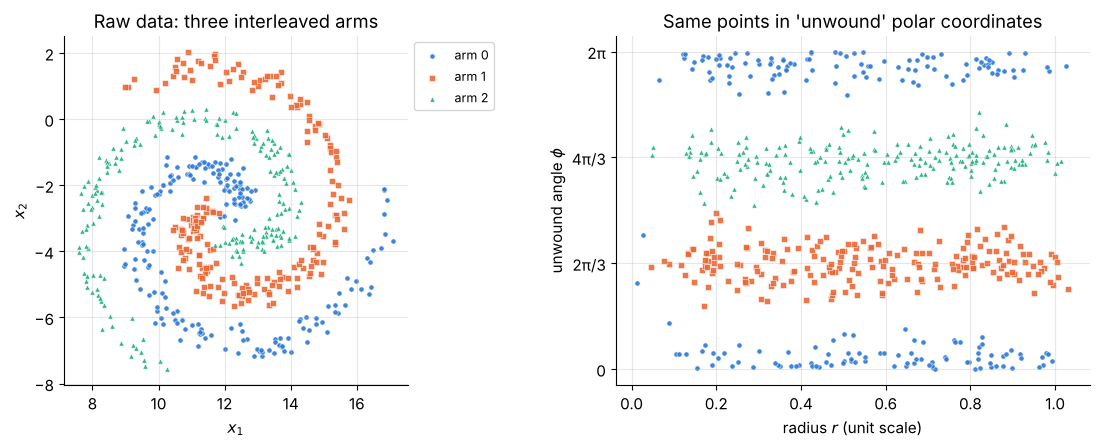

In [7]:
def polar_view(X, center=CENTER, scale=SCALE, turns=TURNS):
    """Radius r and 'unwound' angle phi = theta - 2*pi*turns*r (mod 2*pi) of each point."""
    d = (X - center) / scale
    r = np.hypot(d[:, 0], d[:, 1])
    theta = np.arctan2(d[:, 1], d[:, 0])
    phi = np.mod(theta - 2 * np.pi * turns * r, 2 * np.pi)
    return r, phi


def scatter_classes(ax, X, y, s=14, alpha=0.9, edge="white", label_prefix="", **kw):
    """Scatter each class with its own color and marker shape."""
    for k in np.unique(y):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=s, c=CLASS_COLORS[k], marker=CLASS_MARKERS[k], alpha=alpha,
                   edgecolors=edge, linewidths=0.4, label=f"{label_prefix}arm {k}", **kw)


fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
scatter_classes(axes[0], X, y)
axes[0].set_aspect("equal")
axes[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Raw data: three interleaved arms")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)

r_pol, phi_pol = polar_view(X)
scatter_classes(axes[1], np.column_stack([r_pol, phi_pol]), y)
axes[1].set_yticks([0, 2 * np.pi / 3, 4 * np.pi / 3, 2 * np.pi], ["0", "2π/3", "4π/3", "2π"])
axes[1].set(xlabel="radius $r$ (unit scale)", ylabel="unwound angle $\\phi$",
            title="Same points in 'unwound' polar coordinates")
plt.tight_layout()
plt.show()

On the left, the raw data: three arms, each making one full turn, thicker near the tips because angular noise is magnified by the radius. On the right, the *same* 600 points in different coordinates: the radius $r$ and the **unwound angle** $\phi = \theta - 2\pi\tau r$ (mod $2\pi$). In these coordinates each arm becomes a horizontal band (arm 0 near $0 \equiv 2\pi$, arm 1 near $2\pi/3$, arm 2 near $4\pi/3$), and the problem is almost trivial.

> **Key idea.** Whether a problem is "linear" depends on the **coordinates** you describe it in. A linear model on $(x_1, x_2)$ cannot solve the spiral, but a linear model on cleverly engineered features could. An MLP's hidden layer *learns* its own features from data, which is the whole point of this notebook.

### 1.5 How well could anyone do? A generator-aware rule

Since we wrote the generator, we can build an almost perfect classifier by hand: unwind the angle and pick the arm whose center angle $2\pi k/3$ is closest on the circle. Without the small $\sigma_{xy}$ jitter this would be exactly the **Bayes-optimal** rule (the best any classifier can do): the radius is then known exactly and the unwound angle is the arm angle plus symmetric Gaussian noise, so the most likely arm is the nearest one. With the jitter it is very close to optimal. Its accuracy on a large fresh sample estimates the **irreducible error**, the mistakes caused by genuinely overlapping arms.

In [8]:
def generator_rule(X, center=CENTER, scale=SCALE, turns=TURNS, n_arms=N_ARMS):
    """Predict the arm whose angle 2*pi*k/n_arms is closest (on the circle) to the unwound angle."""
    _, phi = polar_view(X, center, scale, turns)
    arm_angles = 2 * np.pi * np.arange(n_arms) / n_arms
    gap = np.angle(np.exp(1j * (phi[:, None] - arm_angles[None, :])))   # wrapped difference in (-pi, pi]
    return np.abs(gap).argmin(axis=1)


X_fresh, y_fresh = make_spiral_arms(n_per_class=10_000, seed=2024)   # 30,000 brand-new points
ceiling = (generator_rule(X_fresh) == y_fresh).mean()
print(f"generator rule on our 600 points : {(generator_rule(X) == y).mean():.4f}")
print(f"generator rule on 30,000 new ones: {ceiling:.4f}  (about {100 * (1 - ceiling):.1f}% irreducible error)")

generator rule on our 600 points : 0.9967
generator rule on 30,000 new ones: 0.9950  (about 0.5% irreducible error)


So the arms barely overlap: about 99.5% accuracy is achievable, and any model that does much worse is losing accuracy through its own limitations, not because of the data. Remember this ceiling: we will compare every model against it.

> **Going deeper.** In real projects you never know the true rule. A common substitute for the ceiling is *human-level performance* or the agreement rate between two expert labelers. The generator rule here is a luxury of synthetic data, and we will use it again in Section 12, together with the ability to draw unlimited fresh data, to measure generalization precisely.

<details>
<summary><b>Quick check</b>: why can no classifier reach 100% on fresh data from this generator?</summary>

Because the noise terms $\varepsilon$ and $\boldsymbol\eta$ occasionally push a point of one arm into a spot where points of another arm are *more* likely. Near the center the arms are only a few tenths of a unit apart, so this happens most often there. For such a point, the label is genuinely ambiguous given its coordinates: any deterministic rule must get some of these points wrong.
</details>

## 2. From arrays to tensors: split, scale, choose dtypes

### 2.1 A stratified 7:2:1 split

We need three disjoint subsets, each with its own job:

| subset | share | job | may we make decisions with it? |
|---|---|---|---|
| **train** | 70% | fit the weights by gradient descent | yes (that is its purpose) |
| **validation** | 20% | monitor training, compare settings (learning rate, width, ...) | yes |
| **test** | 10% | one final, unbiased estimate of performance on new data | **no**: look at it once, at the very end |

If you peek at the test set while choosing settings, it silently becomes a second validation set and the final number becomes optimistic.

`train_test_split` only cuts in two, so we call it twice: first split off 20% as validation, then take 12.5% of the remaining 80% as test, because $0.125 \times 0.8 = 0.1$. With 600 points: $0.2 \times 600 = 120$ validation points, then $0.125 \times 480 = 60$ test points, leaving $420$ for training.

`stratify=y` makes every subset keep the class proportions of the full data (here exactly one third each). Without it, a small subset can be lopsided by chance: with only 60 test points, an unlucky split could hold 26 points of one arm and 15 of another.

In [9]:
X_rest, X_val, y_rest, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X_rest, y_rest, test_size=0.125,
                                                    stratify=y_rest, random_state=SEED)

split_table = pd.DataFrame(
    [{"points": len(t), "share": len(t) / len(y), **{f"arm {k}": int((t == k).sum()) for k in range(3)}}
     for t in (y_train, y_val, y_test)],
    index=["train", "validation", "test"],
)
display(split_table)

,points,share,arm 0,arm 1,arm 2
train,420,0.7,140,140,140
validation,120,0.2,40,40,40
test,60,0.1,20,20,20


### 2.2 Standardization, fitted on the training set only

A `StandardScaler` learns, **from the training set only**, the mean $\mu_j$ and standard deviation $\sigma_j$ of every feature $j$:

$$
\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \qquad \sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2}, \qquad z_{ij} = \frac{x_{ij}-\mu_j}{\sigma_j},
$$

where $n = 420$ is the number of training points (note the $1/n$, not $1/(n-1)$). It then applies the *same* $\mu_j, \sigma_j$ to validation and test points, and later to every grid point we feed the model for plotting.

**Why fit on train only?** $\mu$ and $\sigma$ are learned parameters, just like the weights. Validation and test points must play the role of data the model has never seen, and using them to compute $\mu, \sigma$ would leak a little information about them into the model. More practically, once the model is deployed, points arrive one at a time and there is no "test set" to compute statistics from, so the training statistics are all you will ever have.

**Why standardize at all?** Our raw features sit around $x_1 \approx 12$ and $x_2 \approx -3$. Three reasons to fix that:
1. PyTorch's default initialization places most hidden ReLU units' "fold lines" close to the origin (median distance about 0.7, and roughly three quarters lie within one unit). With raw inputs most fold lines would miss the data cloud entirely (Section 9.3 measures this).
2. The gradient of a first-layer weight is proportional to its input value, so large inputs mean large, unstable steps for a given learning rate.
3. Features with very different scales would need very different learning rates, while standardization lets one learning rate fit all.

In [10]:
scaler = StandardScaler().fit(X_train)            # learns mu and sigma from the 420 training points
X_train_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_train, X_val, X_test))

print("learned mean :", scaler.mean_.round(4), "  learned std:", scaler.scale_.round(4))
summary = pd.DataFrame({
    "train mean": X_train_s.mean(0), "train std": X_train_s.std(0),
    "val mean": X_val_s.mean(0), "val std": X_val_s.std(0),
    "test mean": X_test_s.mean(0), "test std": X_test_s.std(0),
}, index=["z1", "z2"])
display(summary.round(3) + 0.0)                  # "+ 0.0" turns -0.0 into 0.0

learned mean : [11.9264 -3.0285]   learned std: [2.0917 2.2609]


,train mean,train std,val mean,val std,test mean,test std
z1,0.0,1.0,0.032,1.020,-0.102,1.082
z2,0.0,1.0,0.121,0.945,-0.084,0.845


The training features now have mean exactly 0 and standard deviation exactly 1, and validation and test are close but not exact, which is what should happen when the statistics come from the training set only.

### ✏️ Exercise 2: a standardizer from scratch

Implement `fit_standardizer(X_train)` returning `(mu, sigma)` and `apply_standardizer(X, mu, sigma)` returning the standardized array, using the population standard deviation (the $1/n$ version, NumPy's default `ddof=0`). The checker compares your output with scikit-learn's `StandardScaler`.

In [11]:
# ✏️ Exercise 2: standardization from scratch
def fit_standardizer(X_train):
    """Return (mu, sigma): per-column mean and population standard deviation, each of shape (d,)."""
    # YOUR CODE HERE
    raise NotImplementedError


def apply_standardizer(X, mu, sigma):
    """Return (X - mu) / sigma, broadcasting over rows."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex2():
    mu, sigma = fit_standardizer(X_train)
    assert np.shape(mu) == (2,) and np.shape(sigma) == (2,), "mu and sigma must have shape (2,)"
    assert np.allclose(mu, scaler.mean_) and np.allclose(sigma, scaler.scale_), "statistics differ from sklearn"
    assert np.allclose(apply_standardizer(X_val, mu, sigma), X_val_s), "transformed validation data differ"
    toy = np.array([[1.0, 10.0], [3.0, 10.0], [5.0, 40.0]])
    mu_t, sd_t = fit_standardizer(toy)
    assert np.allclose(mu_t, [3.0, 20.0]) and np.allclose(sd_t, [np.sqrt(8 / 3), np.sqrt(200)]), \
        "check the toy example: use the 1/n (population) standard deviation"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def fit_standardizer(X_train):
    return X_train.mean(axis=0), X_train.std(axis=0)     # std uses ddof=0 by default

def apply_standardizer(X, mu, sigma):
    return (X - mu) / sigma                             # (n, d) - (d,) broadcasts over rows
```
`axis=0` averages down the rows, giving one statistic per column. scikit-learn also guards against $\sigma_j = 0$ (a constant feature) by leaving such a column unscaled, and a careful implementation would do the same.
</details>

### 2.3 Tensors and dtypes: `float32` features, `int64` labels

PyTorch models consume tensors, and the **dtype** (number type) matters:

| tensor | shape | dtype | why this dtype |
|---|---|---|---|
| features `X_*_t` | $(n, 2)$ | `torch.float32` | matches the dtype of `nn.Linear`'s weights, with half the memory of `float64` and plenty precise for training |
| labels `y_*_t` | $(n,)$ | `torch.long` (= `int64`) | labels are **class indices**: the loss uses them to *pick* one log-probability per row, and indices must be integers |

NumPy creates `float64` arrays by default, so we convert explicitly. (`torch.tensor` copies the data, while `torch.from_numpy` would share memory with the array and keep its `float64` dtype.)

In [12]:
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

for name, t in [("X_train_t", X_train_t), ("y_train_t", y_train_t), ("X_val_t", X_val_t),
                ("y_val_t", y_val_t), ("X_test_t", X_test_t), ("y_test_t", y_test_t)]:
    print(f"{name:10s} shape={str(tuple(t.shape)):9s} dtype={t.dtype}")

X_train_t  shape=(420, 2)  dtype=torch.float32
y_train_t  shape=(420,)    dtype=torch.int64
X_val_t    shape=(120, 2)  dtype=torch.float32
y_val_t    shape=(120,)    dtype=torch.int64
X_test_t   shape=(60, 2)   dtype=torch.float32
y_test_t   shape=(60,)     dtype=torch.int64


What goes wrong with the wrong dtypes? Let us provoke both errors on purpose (and catch them, so the notebook keeps running):

In [13]:
layer = nn.Linear(2, 3)                            # weights are float32
loss_fn_demo = nn.CrossEntropyLoss()
logits_demo = layer(X_train_t[:4])                 # fine: float32 input

attempts = {
    "float64 features": lambda: layer(torch.tensor(X_train_s[:4])),            # dtype=float64
    "float labels": lambda: loss_fn_demo(logits_demo, y_train_t[:4].float()),
    "int32 labels": lambda: loss_fn_demo(logits_demo, y_train_t[:4].int()),
    "int64 labels": lambda: loss_fn_demo(logits_demo, y_train_t[:4]),
}
for what, attempt in attempts.items():
    try:
        out = attempt()
        print(f"{what:17s} -> OK, loss = {out.item():.4f}")
    except RuntimeError as err:
        print(f"{what:17s} -> RuntimeError: {str(err).splitlines()[0][:85]}")

float64 features  -> RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float
float labels      -> RuntimeError: expected target dtype to be Long or Byte, but got Float
int32 labels      -> RuntimeError: expected target dtype to be Long or Byte, but got Int
int64 labels      -> OK, loss = 1.2462


The exact wording of the messages depends on your PyTorch version, but the lesson does not: **features `float32`, labels `long`**. (Recent versions also accept `uint8` labels, but `long` is the documented, portable choice.)

<details>
<summary><b>Quick check</b>: a classmate "standardizes everything", labels included. What happens?</summary>

The labels $\{0, 1, 2\}$ would become something like $\{-1.22, 0, 1.22\}$: no longer valid class indices, and no longer integers, so `CrossEntropyLoss` would refuse them. Labels are **categories**, not quantities, and their numeric values are just names. Only input features are standardized.
</details>

## 3. Feeding the model: `Dataset` and `DataLoader`

### 3.1 A custom `Dataset`

PyTorch separates *what the data is* from *how it is served*:

- A **`Dataset`** answers two questions: how many examples are there (`__len__`) and what is example number `i` (`__getitem__`). It can read from memory, disk or the network, and the rest of the pipeline does not care.
- A **`DataLoader`** asks the dataset for examples in some order, groups them into **mini-batches**, and hands batches to the training loop.

In [14]:
class SpiralDataset(Dataset):
    """Serve (features, label) pairs from in-memory arrays or tensors."""

    def __init__(self, X, y):
        self.X = torch.as_tensor(X, dtype=torch.float32)   # no copy if already float32 tensors
        self.y = torch.as_tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_ds = SpiralDataset(X_train_t, y_train_t)
val_ds = SpiralDataset(X_val_t, y_val_t)
test_ds = SpiralDataset(X_test_t, y_test_t)

x0, y0 = train_ds[0]
print("len(train_ds) =", len(train_ds), "| len(val_ds) =", len(val_ds), "| len(test_ds) =", len(test_ds))
print("train_ds[0] ->", x0, "shape", tuple(x0.shape), x0.dtype, "| label", y0, y0.dtype)

len(train_ds) = 420 | len(val_ds) = 120 | len(test_ds) = 60
train_ds[0] -> tensor([ 0.8268, -1.6860]) shape (2,) torch.float32 | label tensor(0) torch.int64


### 3.2 The `DataLoader`: batching and shuffling

Here is what happens each time the training loop asks the loader for the next batch:

```
 sampler       : a shuffled list of indices, e.g. [17, 302, 5, 88, ...]     (reshuffled every epoch)
 dataset[i]    : 32 calls  ->  [(x17, y17), (x302, y302), (x5, y5), ...]    each x: (2,), each y: ()
 collate_fn    : stack     ->  xb: (32, 2) float32,   yb: (32,) int64
```

- **`shuffle=True` for training.** Mini-batch gradient descent assumes each batch is a fair random sample of the data. If the data were stored sorted by class, consecutive batches would contain one class only and each update would drag the model toward that class.
- **`shuffle=False` for validation and test.** The order does not change any metric, and a fixed order keeps predictions aligned with the stored labels for later analysis.
- **A seeded `torch.Generator`** makes the shuffling reproducible: the same seed gives the same sequence of batches.

In [15]:
BATCH_SIZE = 32
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), xb.dtype, "|", tuple(yb.shape), yb.dtype)
print("labels in this batch:", yb.tolist())
batch_sizes = [len(yb) for _, yb in train_loader]
print(f"batches per epoch: {len(train_loader)} -> sizes {batch_sizes}")

one batch: (32, 2) torch.float32 | (32,) torch.int64
labels in this batch: [1, 1, 0, 2, 2, 0, 1, 1, 1, 2, 2, 2, 1, 1, 1, 2, 0, 2, 0, 2, 1, 1, 2, 1, 0, 2, 1, 2, 1, 2, 2, 2]
batches per epoch: 14 -> sizes [32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 4]


An epoch over 420 training points with batches of 32 takes $\lceil 420/32 \rceil = 14$ batches: 13 full ones ($13 \times 32 = 416$ points) and a last batch with only $420 - 416 = 4$ points. Two consequences:

- The last, tiny batch gives a noisier gradient. `DataLoader(..., drop_last=True)` would skip it (13 batches per epoch, and because of shuffling, *different* 4 points are skipped each epoch).
- When we average the loss over an epoch, a plain mean of the 14 batch losses would give those 4 points the same weight as 32 points. Section 7 weights each batch by its size instead.

> **Going deeper.** For data that already sits in memory as tensors, `torch.utils.data.TensorDataset(X_train_t, y_train_t)` does exactly what our `SpiralDataset` does. Writing the class yourself pays off when examples must be loaded or transformed on the fly, such as images read from disk (Notebook 13).

### ✏️ Exercise 3: write the collate step yourself

The DataLoader's default `collate_fn` receives a Python **list of `(x, y)` pairs** and must return two batched tensors. Implement `collate_pairs(batch)` returning `(xb, yb)` where `xb` stacks the feature tensors into shape `(B, 2)` and `yb` stacks the scalar labels into shape `(B,)`, preserving dtypes. Hint: `torch.stack`.

In [16]:
# ✏️ Exercise 3: a collate function
def collate_pairs(batch):
    """batch: list of (x, y) with x of shape (2,) float32 and y a 0-d int64 tensor. Return (xb, yb)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    batch = [train_ds[i] for i in (5, 0, 17)]
    xb3, yb3 = collate_pairs(batch)
    assert tuple(xb3.shape) == (3, 2) and tuple(yb3.shape) == (3,), f"shapes {tuple(xb3.shape)}, {tuple(yb3.shape)}"
    assert xb3.dtype == torch.float32 and yb3.dtype == torch.long, "dtypes must be preserved"
    assert torch.equal(xb3, X_train_t[[5, 0, 17]]) and torch.equal(yb3, y_train_t[[5, 0, 17]]), "wrong values/order"
    loader = DataLoader(train_ds, batch_size=32, shuffle=False, collate_fn=collate_pairs)
    xb_l, yb_l = next(iter(loader))
    assert torch.equal(xb_l, X_train_t[:32]) and torch.equal(yb_l, y_train_t[:32]), "fails inside a DataLoader"


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def collate_pairs(batch):
    xs, ys = zip(*batch)                  # unzip [(x1, y1), (x2, y2), ...] into two tuples
    return torch.stack(xs), torch.stack(ys)
```
`torch.stack` adds a new leading dimension: $B$ tensors of shape $(2,)$ become one $(B, 2)$ tensor, and $B$ zero-dimensional labels become a $(B,)$ vector. This is what `torch.utils.data.default_collate` does for this kind of batch.
</details>

<details>
<summary><b>Quick check</b>: with <code>batch_size=50</code> and <code>drop_last=False</code>, how many batches does one training epoch have, and how big is the last one?</summary>

$\lceil 420/50 \rceil = 9$ batches: eight full batches of 50 (400 points) and a last batch of $420 - 400 = 20$ points.
</details>

## 4. The baseline: a linear classifier and why it must fail

### 4.1 Softmax regression draws straight boundaries

Softmax regression (Notebook 09) computes one score, a **logit**, per class from a weighted sum of the inputs:

$$
\mathbf{z} = \mathbf{W}\mathbf{x} + \mathbf{b}, \qquad \mathbf{W} \in \mathbb{R}^{3 \times 2},\ \mathbf{b} \in \mathbb{R}^{3},\ \mathbf{x} \in \mathbb{R}^{2},
\qquad \hat{y} = \arg\max_{c}\ z_c .
$$

Row $c$ of $\mathbf{W}$, written $\mathbf{w}_c^\top$, scores class $c$: $z_c = \mathbf{w}_c^\top\mathbf{x} + b_c$. (Softmax turns logits into probabilities but never changes which logit is largest, so it does not affect the predicted class.)

**Claim.** Every class region of a linear classifier is **convex**, and every boundary between two classes is a piece of a **straight line**.

**Proof.** The region where class $i$ wins is

$$
R_i = \{\mathbf{x} : z_i(\mathbf{x}) \ge z_j(\mathbf{x}) \text{ for all } j \ne i\}
    = \bigcap_{j \ne i} \{\mathbf{x} : (\mathbf{w}_i - \mathbf{w}_j)^\top \mathbf{x} + (b_i - b_j) \ge 0\}.
$$

Each set in the intersection is a **half-plane**, bounded by the line $(\mathbf{w}_i - \mathbf{w}_j)^\top \mathbf{x} + (b_i - b_j) = 0$. A half-plane is convex: if two points satisfy a linear inequality, so does every point of the segment between them, because a weighted average of two numbers that are both $\ge 0$ is again $\ge 0$. An intersection of convex sets is convex. So $R_i$ is a convex polygon (possibly unbounded), and two regions can only meet along those lines.

**Consequence for spirals.** A convex region that contains two points of an arm contains the whole straight segment between them. Pick, for example, the tip of arm 0 ($r = 1$) and the point of arm 0 halfway out ($r = 0.5$), which lies on the opposite side of the center: the segment between them crosses both other arms (arm 1 twice). So any region that captures a good part of one arm also swallows large parts of the others. No choice of $\mathbf{W}, \mathbf{b}$ can avoid this.

> **Olympiad tip.** Here is a neat consequence. If the three pairwise boundary lines are not parallel, they pass through **one common point**: at a point where $z_0 = z_1$ and $z_1 = z_2$, automatically $z_0 = z_2$. So a 3-class linear classifier always looks like three wedges meeting at a single "triple point". (Exercise 4 asks you to compute it.)

### 4.2 Training the linear model

We train `nn.Linear(2, 3)` with the same ingredients the MLP will use: cross-entropy loss, SGD with learning rate 0.1, batches of 32, 100 epochs. The loop below is deliberately minimal, and Section 7 dissects every line.

We also need **accuracy**, the fraction of correct predictions. `torch.max(logits, dim=1)` returns a pair `(values, indices)`: the largest logit in every row and *where* it is. The indices are the predicted classes (`logits.argmax(dim=1)` returns them directly).

In [17]:
def compute_accuracy(logits, targets):
    """Fraction of rows whose largest logit is at the target index. logits (n, C), targets (n,)."""
    _, predicted = torch.max(logits, dim=1)        # values are not needed, only the positions
    return (predicted == targets).float().mean().item()


torch.manual_seed(SEED)
linear_model = nn.Linear(2, 3).to(DEVICE)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.1)
for epoch in range(100):
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        loss = loss_fn(linear_model(xb), yb)       # forward pass + loss
        optimizer.zero_grad()                      # clear old gradients
        loss.backward()                            # compute new gradients
        optimizer.step()                           # update W and b

with torch.no_grad():
    lin_train_acc = compute_accuracy(linear_model(X_train_t.to(DEVICE)), y_train_t.to(DEVICE))
    lin_val_acc = compute_accuracy(linear_model(X_val_t.to(DEVICE)), y_val_t.to(DEVICE))

# For comparison: scikit-learn's logistic regression minimizes the (regularized) cross-entropy with a precise solver.
sk_linear = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
display(pd.DataFrame({
    "train accuracy": [lin_train_acc, sk_linear.score(X_train_s, y_train)],
    "validation accuracy": [lin_val_acc, sk_linear.score(X_val_s, y_val)],
}, index=["PyTorch nn.Linear (SGD)", "scikit-learn LogisticRegression"]).round(4))
print(f"chance level: {1 / 3:.4f} | generator-rule ceiling: {ceiling:.4f}")

,train accuracy,validation accuracy
PyTorch nn.Linear (SGD),0.3714,0.4083
scikit-learn LogisticRegression,0.3690,0.4083


chance level: 0.3333 | generator-rule ceiling: 0.9950


### 4.3 Drawing decision regions with a grid

To *see* what a classifier does, we ask it about every pixel of a picture. The recipe, which we will reuse for every model in this notebook:

```
 1. xs = linspace(x1_min, x1_max, 250), ys = linspace(x2_min, x2_max, 250)    250 values each
 2. xx, yy = meshgrid(xs, ys)                         two (250, 250) arrays: the coordinates of every pixel
 3. grid = column_stack([xx.ravel(), yy.ravel()])     (62500, 2): one row per pixel, in ORIGINAL units
 4. scaler.transform(grid) -> float32 tensor -> model -> logits (62500, 3) -> argmax -> (62500,)
 5. reshape to (250, 250) and color each pixel with contourf(xx, yy, labels)
```

Step 4 is the one people forget: the grid lives in original units, so it must go through **the same scaler** as the training data before it reaches the model. Feeding raw coordinates to a model trained on standardized ones produces nonsense pictures.

The helpers below take any `proba_fn` that maps an `(n, 2)` array of original-unit points to an `(n, C)` array of class probabilities, so the same plotting code works for PyTorch models, scikit-learn models and our generator rule.

In [18]:
def make_grid(X_ref, steps=250, pad=0.8):
    """A steps x steps grid covering the bounding box of X_ref plus a margin. Returns xx, yy, points."""
    lo, hi = X_ref.min(axis=0) - pad, X_ref.max(axis=0) + pad
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], steps), np.linspace(lo[1], hi[1], steps))
    return xx, yy, np.column_stack([xx.ravel(), yy.ravel()])


@torch.no_grad()
def predict_proba(model, X_orig, scaler):
    """Class probabilities, shape (n, C), for points given in ORIGINAL units."""
    was_training = model.training
    model.eval()
    device = next(model.parameters()).device
    Xt = torch.tensor(scaler.transform(X_orig), dtype=torch.float32, device=device)
    probs = torch.softmax(model(Xt), dim=1).cpu().numpy()
    model.train(was_training)                      # leave the model in the mode we found it in
    return probs


def plot_regions(ax, proba_fn, X_pts=None, y_pts=None, title="", X_ref=None, steps=250, s=12,
                 boundary=True, legend=False):
    """Color every pixel by the predicted class, draw the boundaries, overlay labeled points."""
    xx, yy, grid = make_grid(X if X_ref is None else X_ref, steps)
    labels = proba_fn(grid).argmax(axis=1).reshape(xx.shape)
    ax.contourf(xx, yy, labels, levels=[-0.5, 0.5, 1.5, 2.5], cmap=REGION_CMAP)
    if boundary:
        for k in range(3):
            if (labels == k).any() and (labels != k).any():
                ax.contour(xx, yy, (labels == k).astype(float), levels=[0.5], colors="#333333", linewidths=0.7)
    if X_pts is not None:
        scatter_classes(ax, X_pts, y_pts, s=s, edge="#222222")
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    if legend:
        ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
    return labels

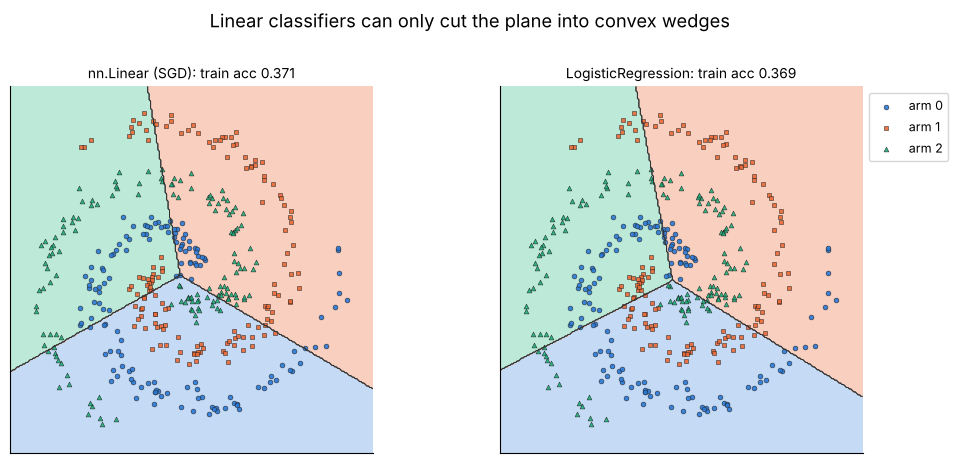

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_regions(axes[0], lambda P: predict_proba(linear_model, P, scaler), X_train, y_train,
             title=f"nn.Linear (SGD): train acc {lin_train_acc:.3f}")
plot_regions(axes[1], lambda P: sk_linear.predict_proba(scaler.transform(P)), X_train, y_train,
             title=f"LogisticRegression: train acc {sk_linear.score(X_train_s, y_train):.3f}", legend=True)
fig.suptitle("Linear classifiers can only cut the plane into convex wedges", y=1.0)
plt.tight_layout()
plt.show()

Three straight-edged wedges meeting at one triple point, exactly as the theory predicts. Each wedge grabs a slice of every arm, and both linear models end up only modestly better than guessing (one third). Both models minimize cross-entropy rather than the number of errors, so they are not even the most accurate linear classifiers: a separate search over $\mathbf{W}, \mathbf{b}$ that maximizes the training accuracy directly (not shown here) finds an `nn.Linear(2, 3)` with about 0.56 training accuracy. That is still hopeless next to the 0.995 ceiling. Because the classes are not convex, no amount of training, no better optimizer and no more data can make a linear model good here. The model class itself is too weak.

> **Common pitfall.** "Low accuracy, so train longer!" is the wrong reflex when the **model class** cannot represent the answer. Training longer only helps a model that is still improving, and here scikit-learn's exact solver and our SGD land in the same place.

### ✏️ Exercise 4: the triple point

Write `triple_point(W, b)` that returns the point $\mathbf{x} \in \mathbb{R}^2$ where all three logits of a linear classifier are equal. `W` is a `(3, 2)` tensor and `b` a `(3,)` tensor (as stored by `nn.Linear(2, 3)`). Hint: solve the $2 \times 2$ linear system $(\mathbf{w}_0 - \mathbf{w}_1)^\top\mathbf{x} = b_1 - b_0$, $(\mathbf{w}_1 - \mathbf{w}_2)^\top\mathbf{x} = b_2 - b_1$ with `torch.linalg.solve`. Return a tensor of shape `(2,)` (in the standardized coordinates the model works in).

In [20]:
# ✏️ Exercise 4: where the three boundaries meet
def triple_point(W, b):
    """Return the (2,) point where W @ x + b has three equal entries."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    W_t, b_t = linear_model.weight.detach().cpu(), linear_model.bias.detach().cpu()
    p = triple_point(W_t, b_t)
    assert tuple(p.shape) == (2,), f"expected shape (2,), got {tuple(p.shape)}"
    z = W_t @ p + b_t
    assert torch.allclose(z, z.mean().expand(3), atol=1e-4), f"logits at your point are not equal: {z}"
    W2 = torch.tensor([[1.0, 0.0], [0.0, 1.0], [-1.0, -1.0]])
    b2 = torch.tensor([0.0, 1.0, 2.0])
    assert torch.allclose(triple_point(W2, b2), torch.tensor([1.0, 0.0]), atol=1e-5), "wrong point for a toy example"


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def triple_point(W, b):
    A = torch.stack([W[0] - W[1], W[1] - W[2]])     # (2, 2): one boundary per row
    rhs = torch.stack([b[1] - b[0], b[2] - b[1]])   # (2,)
    return torch.linalg.solve(A, rhs)
```
Equal $z_0 = z_1$ and $z_1 = z_2$ give two linear equations in two unknowns. In the toy example, $\mathbf{x} = (1, 0)$ gives logits $(1, 1, 1)$. The system is singular only when two boundaries are parallel, in which case there is no single triple point.
</details>

## 5. The multilayer perceptron

### 5.1 From one layer to two

An MLP inserts a **hidden layer** between input and output. For one input point $\mathbf{x} \in \mathbb{R}^2$:

$$
\mathbf{a} = \mathbf{W}_1\mathbf{x} + \mathbf{b}_1, \qquad
\mathbf{h} = \operatorname{ReLU}(\mathbf{a}), \qquad
\mathbf{z} = \mathbf{W}_2\mathbf{h} + \mathbf{b}_2,
$$

with $\mathbf{W}_1 \in \mathbb{R}^{128 \times 2}$, $\mathbf{b}_1 \in \mathbb{R}^{128}$, $\mathbf{W}_2 \in \mathbb{R}^{3 \times 128}$, $\mathbf{b}_2 \in \mathbb{R}^{3}$. The vector $\mathbf{a}$ holds the **pre-activations**, $\mathbf{h}$ the **hidden features** (also called activations) and $\mathbf{z}$ the three **logits**. $\operatorname{ReLU}(a) = \max(0, a)$ acts on every entry separately.

```
 input (2)            hidden layer: 128 units                   output: 3 logits
                    a_j = w_j . x + b_j,  h_j = max(0, a_j)
  x1 ──┐            ┌──[ unit 1 ]──┐
       ├─ every ───►│      ...     ├── every unit to every ──►  z0, z1, z2 ──► argmax (prediction)
  x2 ──┘   input    └──[unit 128]──┘    output                              └► CrossEntropyLoss (training)
     W1: 128 x 2, b1: 128                  W2: 3 x 128, b2: 3
```

In code we process a whole batch at once. With $B$ points stacked as rows of $\mathbf{X} \in \mathbb{R}^{B \times 2}$:

| quantity | formula | shape | note |
|---|---|---|---|
| input batch | $\mathbf{X}$ | $(B, 2)$ | standardized, `float32` |
| first weights | $\mathbf{W}_1$ | $(128, 2)$ | `nn.Linear` stores weights as (out, in) |
| pre-activations | $\mathbf{A} = \mathbf{X}\mathbf{W}_1^\top + \mathbf{b}_1$ | $(B, 128)$ | $\mathbf{b}_1$ is broadcast over rows |
| hidden features | $\mathbf{H} = \operatorname{ReLU}(\mathbf{A})$ | $(B, 128)$ | |
| logits | $\mathbf{Z} = \mathbf{H}\mathbf{W}_2^\top + \mathbf{b}_2$ | $(B, 3)$ | **no** softmax here |
| labels | $\mathbf{y}$ | $(B,)$ | `int64` class indices |

**Parameter count.** A linear layer with $d_{\text{in}}$ inputs and $d_{\text{out}}$ outputs has $d_{\text{in}} d_{\text{out}}$ weights and $d_{\text{out}}$ biases, i.e. $(d_{\text{in}} + 1)\,d_{\text{out}}$ parameters. Our network has $(2+1) \cdot 128 + (128+1) \cdot 3 = 384 + 387 = 771$ parameters, compared with $(2+1) \cdot 3 = 9$ for softmax regression.

### 5.2 Why the nonlinearity is essential

Remove the ReLU and the two layers collapse into one:

$$
\mathbf{W}_2(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = \underbrace{(\mathbf{W}_2\mathbf{W}_1)}_{3 \times 2}\mathbf{x} + \underbrace{(\mathbf{W}_2\mathbf{b}_1 + \mathbf{b}_2)}_{3},
$$

which is just softmax regression with $\mathbf{W} = \mathbf{W}_2\mathbf{W}_1$ and $\mathbf{b} = \mathbf{W}_2\mathbf{b}_1 + \mathbf{b}_2$. Stacking a hundred linear layers still gives a linear model with convex regions. The code confirms that a "deep" network without activations computes exactly the same function as a single collapsed `nn.Linear`:

In [21]:
torch.manual_seed(SEED)
no_relu = nn.Sequential(nn.Linear(2, 128), nn.Linear(128, 3))          # two layers, no activation
W1_, b1_ = no_relu[0].weight, no_relu[0].bias
W2_, b2_ = no_relu[1].weight, no_relu[1].bias
collapsed = nn.Linear(2, 3)
with torch.no_grad():
    collapsed.weight.copy_(W2_ @ W1_)                                  # (3, 128) @ (128, 2) -> (3, 2)
    collapsed.bias.copy_(W2_ @ b1_ + b2_)
    diff = (no_relu(X_train_t) - collapsed(X_train_t)).abs().max().item()
print(f"largest difference between the 2-layer linear net and one collapsed layer: {diff:.2e}")

largest difference between the 2-layer linear net and one collapsed layer: 5.96e-07


The difference is at the level of `float32` rounding. **The nonlinearity is what makes depth meaningful.**

### 5.3 The ReLU activation

$$
\operatorname{ReLU}(a) = \max(0, a), \qquad \operatorname{ReLU}'(a) = \begin{cases} 1 & a > 0 \\ 0 & a < 0 \end{cases}
$$

(at $a = 0$ PyTorch uses the derivative $0$). ReLU is the default choice for hidden layers because it is cheap, its gradient does not shrink for positive inputs, and it is **piecewise linear**: each unit is either "off" (outputs 0) or "on" (passes its input through). Section 9 shows that this on/off behavior is exactly what lets the network bend its decision boundary. Section 11.6 compares it with tanh, sigmoid and LeakyReLU.

### 5.4 The model in PyTorch

A PyTorch model is a class that inherits from `nn.Module`: layers that hold parameters are created in `__init__`, and `forward` describes the computation. Two design decisions:

- `forward` returns **logits**. There is no softmax at the end, because `nn.CrossEntropyLoss` applies (log-)softmax internally (Section 6 explains why that matters).
- The number of outputs is not hard-coded: `torch.unique(y_train_t)` lists the distinct labels, and its length is the number of classes. (Section 10.5 discusses the pitfalls of this convenient trick.)

We also expose the hidden features through a small `hidden` method, which Section 9 uses to look inside the network.

In [22]:
class MLP(nn.Module):
    """input -> Linear -> ReLU -> Linear -> logits. No softmax: CrossEntropyLoss applies it."""

    def __init__(self, input_dims, hidden_dims, output_dims):
        super().__init__()
        self.linear1 = nn.Linear(input_dims, hidden_dims)
        self.output = nn.Linear(hidden_dims, output_dims)

    def hidden(self, x):
        """Hidden features h = ReLU(W1 x + b1), shape (batch, hidden_dims)."""
        return F.relu(self.linear1(x))

    def forward(self, x):
        return self.output(self.hidden(x))


input_dims = X_train_t.shape[1]
output_dims = torch.unique(y_train_t).shape[0]
hidden_dims = 128
print(f"input_dims = {input_dims}, hidden_dims = {hidden_dims}, "
      f"output_dims = torch.unique(y_train_t).shape[0] = {output_dims}  (unique labels: {torch.unique(y_train_t).tolist()})")

torch.manual_seed(SEED)
model = MLP(input_dims, hidden_dims, output_dims).to(DEVICE)
print(model)
for name, p in model.named_parameters():
    print(f"  {name:15s} {str(tuple(p.shape)):10s} {p.numel():4d} parameters")
n_params = sum(p.numel() for p in model.parameters())
print(f"total: {n_params} parameters (formula: {(2 + 1) * 128 + (128 + 1) * 3})")

input_dims = 2, hidden_dims = 128, output_dims = torch.unique(y_train_t).shape[0] = 3  (unique labels: [0, 1, 2])
MLP(
  (linear1): Linear(in_features=2, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=3, bias=True)
)
  linear1.weight  (128, 2)    256 parameters
  linear1.bias    (128,)      128 parameters
  output.weight   (3, 128)    384 parameters
  output.bias     (3,)          3 parameters
total: 771 parameters (formula: 771)


**A sanity check before training.** At initialization the logits are small, so the predicted probabilities are close to uniform, $p_c \approx 1/3$, and the cross-entropy loss should be close to $-\ln(1/3) = \ln 3 \approx 1.0986$. If your initial loss is far above $\ln C$ for $C$ classes, something is wrong (unscaled inputs, a bad initialization, labels mixed up) before training even starts.

In [23]:
with torch.no_grad():
    init_logits = model(X_train_t.to(DEVICE))
    init_probs = torch.softmax(init_logits, dim=1)
    init_loss = nn.CrossEntropyLoss()(init_logits, y_train_t.to(DEVICE)).item()
print("logits of the first 3 training points:\n", init_logits[:3].cpu().numpy().round(4))
print("probabilities of the first 3 training points:\n", init_probs[:3].cpu().numpy().round(4))
print(f"initial loss on the training set: {init_loss:.4f}   vs   ln 3 = {math.log(3):.4f}")
print(f"initial training accuracy: {compute_accuracy(init_logits, y_train_t.to(DEVICE)):.4f}")

logits of the first 3 training points:
 [[-0.2016  0.0928  0.317 ]
 [-0.1694  0.1136  0.2337]
 [-0.278  -0.0978  0.1606]]
probabilities of the first 3 training points:
 [[0.2486 0.3337 0.4176]
 [0.2615 0.3471 0.3914]
 [0.2668 0.3195 0.4137]]
initial loss on the training set: 1.1047   vs   ln 3 = 1.0986
initial training accuracy: 0.3595


### 5.5 A forward pass by hand

To make every number concrete, take a toy network with **2 inputs, 3 hidden units and 3 classes** and the input $\mathbf{x} = (1, -2)$:

$$
\mathbf{W}_1 = \begin{pmatrix} 1 & 1 \\ 2 & -1 \\ -1 & 0 \end{pmatrix},\ \mathbf{b}_1 = \begin{pmatrix} 0.5 \\ -1 \\ 0 \end{pmatrix}, \qquad
\mathbf{W}_2 = \begin{pmatrix} 1 & 0.5 & 0 \\ 0 & -1 & 2 \\ -1 & 1 & 1 \end{pmatrix},\ \mathbf{b}_2 = \begin{pmatrix} 0 \\ 1 \\ 0 \end{pmatrix}.
$$

| step | unit / class 1 | unit / class 2 | unit / class 3 |
|---|---|---|---|
| $a_j = \mathbf{w}_j^\top\mathbf{x} + b_j$ | $1 - 2 + 0.5 = -0.5$ | $2 + 2 - 1 = 3$ | $-1 + 0 + 0 = -1$ |
| $h_j = \max(0, a_j)$ | $0$ | $3$ | $0$ |
| $z_c = \mathbf{W}_2[c,:]\,\mathbf{h} + b_{2,c}$ | $0.5 \cdot 3 + 0 = 1.5$ | $-1 \cdot 3 + 1 = -2$ | $1 \cdot 3 + 0 = 3$ |
| $e^{z_c}$ | $4.4817$ | $0.1353$ | $20.0855$ |
| $p_c = e^{z_c} / 24.7026$ | $0.1814$ | $0.0055$ | $0.8131$ |

The network predicts the third class (index 2) with probability $0.8131$. If the true label were index 0, the loss would be $-\ln 0.1814 = 1.7069$, and if it were index 2, only $-\ln 0.8131 = 0.2069$. Notice that hidden units 1 and 3 are **off** for this input: they output 0, and (since $\operatorname{ReLU}'=0$ there) no gradient flows through them for this example. Let us confirm with PyTorch by loading these exact weights into our `MLP` class:

In [24]:
toy = MLP(input_dims=2, hidden_dims=3, output_dims=3)
toy.load_state_dict({
    "linear1.weight": torch.tensor([[1.0, 1.0], [2.0, -1.0], [-1.0, 0.0]]),
    "linear1.bias": torch.tensor([0.5, -1.0, 0.0]),
    "output.weight": torch.tensor([[1.0, 0.5, 0.0], [0.0, -1.0, 2.0], [-1.0, 1.0, 1.0]]),
    "output.bias": torch.tensor([0.0, 1.0, 0.0]),
})
x_toy = torch.tensor([[1.0, -2.0]])                                    # a batch with one point: (1, 2)
with torch.no_grad():
    a_toy = toy.linear1(x_toy)
    h_toy = toy.hidden(x_toy)
    z_toy = toy(x_toy)
    p_toy = torch.softmax(z_toy, dim=1)
print("a =", a_toy.numpy().round(4), " h =", h_toy.numpy().round(4), " z =", z_toy.numpy().round(4))
print("p =", p_toy.numpy().round(4))
for label in (0, 2):
    loss_toy = F.cross_entropy(z_toy, torch.tensor([label])).item()
    print(f"loss if the true label is {label}: {loss_toy:.4f}")

a = [[-0.5  3.  -1. ]]  h = [[0. 3. 0.]]  z = [[ 1.5 -2.   3. ]]
p = [[0.1814 0.0055 0.8131]]
loss if the true label is 0: 1.7069
loss if the true label is 2: 0.2069


### 5.6 How PyTorch initializes the weights

`nn.Linear(d_in, d_out)` draws every weight and bias independently from the uniform distribution $\mathcal{U}\!\left(-1/\sqrt{d_{\text{in}}},\ 1/\sqrt{d_{\text{in}}}\right)$. (Internally this is "Kaiming-uniform with $a = \sqrt5$", which works out to exactly this bound.) For our first layer $d_{\text{in}} = 2$, so the bound is $1/\sqrt2 \approx 0.7071$, and for the output layer $d_{\text{in}} = 128$ gives $1/\sqrt{128} \approx 0.0884$. The small output weights explain why the initial logits above were tiny and the initial loss so close to $\ln 3$.

In [25]:
for layer_name, layer in [("linear1", model.linear1), ("output", model.output)]:
    bound = 1 / math.sqrt(layer.in_features)
    for kind, p in [("weight", layer.weight), ("bias", layer.bias)]:
        print(f"{layer_name + '.' + kind:15s} range [{p.min().item():+.4f}, {p.max().item():+.4f}]   "
              f"bound 1/sqrt({layer.in_features}) = {bound:.4f}")

linear1.weight  range [-0.7034, +0.7068]   bound 1/sqrt(2) = 0.7071
linear1.bias    range [-0.7038, +0.6971]   bound 1/sqrt(2) = 0.7071
output.weight   range [-0.0879, +0.0880]   bound 1/sqrt(128) = 0.0884
output.bias     range [-0.0569, +0.0874]   bound 1/sqrt(128) = 0.0884


### ✏️ Exercise 5: counting parameters

1. `count_mlp_params(layer_sizes)`: given the list of layer widths from input to output, e.g. `[2, 128, 3]`, return the total number of weights and biases.
2. `width_for_budget(n_hidden_layers, budget, d_in=2, d_out=3)`: find the width $w$ (the same for every hidden layer) whose parameter count is **closest** to `budget`. Break ties toward the smaller width. You will use this idea in Section 11.5 to compare networks of different depths fairly.

In [26]:
# ✏️ Exercise 5: parameter counting
def count_mlp_params(layer_sizes):
    """Total parameters of an MLP with fully connected layers of the given widths."""
    # YOUR CODE HERE
    raise NotImplementedError


def width_for_budget(n_hidden_layers, budget, d_in=2, d_out=3):
    """Hidden width w (same for all hidden layers) whose parameter count is closest to budget."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    assert count_mlp_params([2, 128, 3]) == 771, "the reference MLP has 771 parameters"
    assert count_mlp_params([2, 3]) == 9, "softmax regression on 2 features with 3 classes has 9"
    assert count_mlp_params([2, 24, 24, 3]) == 747
    assert count_mlp_params([2, 18, 18, 18, 3]) == 795
    assert count_mlp_params([16384, 256, 128, 64, 7]) == 4_236_167, "an image-sized MLP"
    assert width_for_budget(1, 771) == 128
    assert width_for_budget(2, 771) == 24, "2 hidden layers: 24 units give 747 parameters, 25 give 803"
    assert width_for_budget(3, 771) == 18, "3 hidden layers: 18 units give 795 parameters, 17 give 717"


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def count_mlp_params(layer_sizes):
    return sum((d_in + 1) * d_out for d_in, d_out in zip(layer_sizes[:-1], layer_sizes[1:]))

def width_for_budget(n_hidden_layers, budget, d_in=2, d_out=3):
    best_w, best_gap = None, None
    for w in range(1, budget + 1):
        gap = abs(count_mlp_params([d_in] + [w] * n_hidden_layers + [d_out]) - budget)
        if best_gap is None or gap < best_gap:          # strict "<" keeps the smaller width on ties
            best_w, best_gap = w, gap
    return best_w
```
Each consecutive pair of widths is one `nn.Linear`, contributing $(d_\text{in}+1)\,d_\text{out}$ parameters. With $L \ge 2$ hidden layers of width $w$ the count grows like $(L-1)w^2$, so equal budgets force deeper networks to be narrower: $24$ units for two layers and $18$ for three, versus $128$ for one.
</details>

## 6. `CrossEntropyLoss` from the inside

### 6.1 From logits to probabilities: softmax

The softmax function turns a vector of logits $\mathbf{z} \in \mathbb{R}^C$ into probabilities:

$$
p_c = \operatorname{softmax}(\mathbf{z})_c = \frac{e^{z_c}}{\sum_{j=1}^{C} e^{z_j}}, \qquad c = 1, \dots, C.
$$

Every $p_c$ is positive, they sum to 1, a larger logit always gives a larger probability (so $\arg\max$ is unchanged), and adding the same constant to all logits changes nothing (multiply top and bottom by $e^{\text{const}}$).

### 6.2 The loss: negative log-probability of the true class

For one example whose true class is $y$, the cross-entropy loss is the negative log of the probability the model gave to the truth:

$$
\ell = -\log p_y = -z_y + \log\sum_{j=1}^{C} e^{z_j}.
$$

For a batch of $N$ examples, with one-hot labels $y_{ic} = 1$ if example $i$ belongs to class $c$ and $0$ otherwise, the loss is the average

$$
\mathcal{L}_{\text{CE}} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{c=1}^{C} y_{ic}\,\log \hat{p}_{ic} = -\frac{1}{N}\sum_{i=1}^{N} \log \hat{p}_{i,\,y_i},
$$

where $\hat p_{ic}$ is the predicted probability of class $c$ for example $i$. Only the true-class term survives the inner sum, because all other $y_{ic}$ are zero. Reference values: a perfect, confident prediction costs $0$, a uniform guess over 3 classes costs $\ln 3 \approx 1.0986$, and a confident wrong prediction costs a lot ($-\ln 0.01 \approx 4.6$). Minimizing this loss is the same as maximizing the likelihood of the observed labels (Notebook 07).

### 6.3 A batch by hand

Three examples, three classes:

| example | logits $\mathbf{z}$ | $e^{\mathbf{z}}$ | sum | probabilities $\mathbf{p}$ | true $y$ | $-\log p_y$ |
|---|---|---|---|---|---|---|
| 1 | $(2,\ 1,\ -1)$ | $(7.3891,\ 2.7183,\ 0.3679)$ | $10.4752$ | $(0.7054,\ 0.2595,\ 0.0351)$ | 0 | $0.3490$ |
| 2 | $(0.5,\ 0.5,\ 0.5)$ | $(1.6487,\ 1.6487,\ 1.6487)$ | $4.9462$ | $(0.3333,\ 0.3333,\ 0.3333)$ | 2 | $1.0986$ |
| 3 | $(-1,\ 3,\ 0)$ | $(0.3679,\ 20.0855,\ 1)$ | $21.4534$ | $(0.0171,\ 0.9362,\ 0.0466)$ | 1 | $0.0659$ |

The batch loss is the mean $(0.3490 + 1.0986 + 0.0659)/3 = 0.5045$. Example 2 shows that equal logits mean "no idea" (loss $\ln 3$) regardless of their common value. Now four ways to compute the same number in PyTorch:

In [27]:
z_batch = torch.tensor([[2.0, 1.0, -1.0], [0.5, 0.5, 0.5], [-1.0, 3.0, 0.0]])
y_batch = torch.tensor([0, 2, 1])

p_batch = torch.softmax(z_batch, dim=1)
manual = -torch.log(p_batch[torch.arange(3), y_batch]).mean()          # pick p_{i, y_i} row by row
one_hot = F.one_hot(y_batch, num_classes=3).float()
one_hot_formula = -(one_hot * torch.log(p_batch)).sum(dim=1).mean()   # the double-sum formula
module = nn.CrossEntropyLoss()(z_batch, y_batch)                       # what we train with
pieces = F.nll_loss(F.log_softmax(z_batch, dim=1), y_batch)            # what the module does inside
prob_targets = nn.CrossEntropyLoss()(z_batch, one_hot)                 # float (N, C) probability targets

print("per-example losses:", F.cross_entropy(z_batch, y_batch, reduction="none").numpy().round(4))
for name, value in [("manual -log p_y", manual), ("one-hot double sum", one_hot_formula),
                    ("nn.CrossEntropyLoss", module), ("log_softmax + nll_loss", pieces),
                    ("probability targets", prob_targets)]:
    print(f"{name:24s} {value.item():.4f}")

per-example losses: [0.349  1.0986 0.0659]
manual -log p_y          0.5045
one-hot double sum       0.5045
nn.CrossEntropyLoss      0.5045
log_softmax + nll_loss   0.5045
probability targets      0.5045


### 6.4 What `CrossEntropyLoss` computes internally

```
 logits Z (N, C) ──log_softmax──► log-probabilities (N, C) ──pick column y_i in row i──► (N,) ──mean──► loss
                   (stable)                                   (this is nll_loss)
```

**Why log-softmax and not `log(softmax(z))`?** Exponentials overflow. In `float32`, $e^{89}$ is already infinite, so logits like $(1000, 999, 998)$ break a naive softmax. The fix is the **log-sum-exp trick**: with $m = \max_j z_j$,

$$
\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m},
$$

where every exponent is now $\le 0$, so nothing overflows, and the largest term is exactly $e^0 = 1$, so the sum cannot underflow to 0 either. Then $\log p_c = z_c - m - \log\sum_j e^{z_j - m}$.

In [28]:
z_big = torch.tensor([[1000.0, 999.0, 998.0]])
naive = torch.exp(z_big) / torch.exp(z_big).sum()
print("naive softmax      :", naive.numpy(), "-> exp(1000) overflows to inf, and inf/inf = nan")
m = z_big.max(dim=1, keepdim=True).values
stable_log_p = z_big - m - torch.log(torch.exp(z_big - m).sum(dim=1, keepdim=True))
print("stable log-softmax :", stable_log_p.numpy().round(4), " | torch:", F.log_softmax(z_big, dim=1).numpy().round(4))
print(f"cross-entropy for label 2: {F.cross_entropy(z_big, torch.tensor([2])).item():.4f} (finite)")

naive softmax      : [[nan nan nan]] -> exp(1000) overflows to inf, and inf/inf = nan
stable log-softmax : [[-0.4076 -1.4076 -2.4076]]  | torch: [[-0.4076 -1.4076 -2.4076]]
cross-entropy for label 2: 2.4076 (finite)


Useful options of `nn.CrossEntropyLoss`: `reduction="none"` returns one loss per example (handy for finding the hardest examples), `"sum"` adds them up, and the default `"mean"` averages, `weight=` gives each class its own weight (for imbalanced data), `label_smoothing=0.1` mixes the one-hot targets with a uniform distribution, and `ignore_index=` skips examples with a given label.

### 6.5 The gradient: $\mathbf{p} - \mathbf{y}$

Differentiate $\ell = -z_y + \log\sum_j e^{z_j}$ with respect to one logit $z_c$:

$$
\frac{\partial \ell}{\partial z_c} = -\mathbb{1}[c = y] + \frac{e^{z_c}}{\sum_j e^{z_j}} = p_c - y_c,
$$

where $y_c$ is the one-hot label. For the batch mean, each row is divided by $N$. This is a beautiful gradient: the true-class logit is pushed **up** by $1 - p_y$ (a lot when the model is wrong, almost nothing when it is right and confident), every other logit is pushed **down** by its own probability, and every component lies in $[-1, 1]$, so the signal never explodes. Autograd agrees with the formula on our 3-example batch:

In [29]:
z_leaf = z_batch.clone().requires_grad_(True)
F.cross_entropy(z_leaf, y_batch).backward()
formula = (torch.softmax(z_batch, dim=1) - F.one_hot(y_batch, 3).float()) / len(y_batch)
print("autograd gradient:\n", z_leaf.grad.numpy().round(4))
print("(p - y) / N      :\n", formula.numpy().round(4))
print("max difference:", (z_leaf.grad - formula).abs().max().item())

autograd gradient:
 [[-0.0982  0.0865  0.0117]
 [ 0.1111  0.1111 -0.2222]
 [ 0.0057 -0.0213  0.0155]]
(p - y) / N      :
 [[-0.0982  0.0865  0.0117]
 [ 0.1111  0.1111 -0.2222]
 [ 0.0057 -0.0213  0.0155]]
max difference: 2.9802322387695312e-08


### 6.6 Why the model outputs logits and never a softmax

Because `nn.CrossEntropyLoss` applies log-softmax itself, the model must hand it **raw logits**. Adding `torch.softmax` at the end of `forward` is one of the most common bugs in PyTorch code, and it fails *silently*: training still runs, the loss still decreases, but badly. The loss then treats probabilities (numbers in $[0, 1]$) as if they were logits and applies a **second softmax**. With 3 classes, the most confident output the second softmax can produce comes from the input $(1, 0, 0)$:

$$
q_{\max} = \frac{e^{1}}{e^{1} + e^{0} + e^{0}} = \frac{e}{e + 2} \approx 0.5761, \qquad \text{so} \qquad \ell \;\ge\; -\ln 0.5761 \approx 0.5514 .
$$

Even a perfect classifier cannot push the loss below $0.5514$, and the gradients pass through two squashing functions, so they shrink. Section 7.7 measures the damage. If you need probabilities (for plots or decisions), apply `torch.softmax` **outside** the model, as our `predict_proba` helper does.

### 6.7 Why targets are class indices (`long`)

The loss picks $\log \hat p_{i, y_i}$: entry $y_i$ of row $i$. So $y_i$ is an **index**, it must be an integer in $\{0, \dots, C-1\}$, and PyTorch's standard index dtype is `int64` (`torch.long`). Two consequences:

- Labels such as $\{1, 2, 3\}$ or $\{0, 5, 9\}$ must be re-encoded to $\{0, 1, 2\}$ first, and a label equal to $C$ raises `IndexError: Target 3 is out of bounds` (Section 10.5 shows how to re-encode).
- Float targets are allowed **only** as a full probability table of shape $(N, C)$ (soft labels, label smoothing), as in the last line of the cell in 6.3, never as a float vector of class numbers.

### ✏️ Exercise 6: a numerically stable cross-entropy

Implement `cross_entropy_from_scratch(logits, targets)` for logits of shape `(N, C)` and `long` targets of shape `(N,)`, returning the mean loss as a 0-d tensor. Use the log-sum-exp trick, and do **not** call `F.cross_entropy`, `F.log_softmax`, `torch.logsumexp` or `nn.CrossEntropyLoss`. The checker includes logits as large as $\pm 10^4$.

In [30]:
# ✏️ Exercise 6: stable cross-entropy
def cross_entropy_from_scratch(logits, targets):
    """Mean of -log softmax(logits)[i, targets[i]] over the batch, computed stably."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    out = cross_entropy_from_scratch(z_batch, y_batch)
    assert torch.is_tensor(out) and out.ndim == 0, "return a 0-d tensor"
    assert abs(out.item() - 0.5045) < 1e-3, f"worked example should give 0.5045, got {out.item():.4f}"
    gen = torch.Generator().manual_seed(0)
    Z = torch.randn(50, 4, generator=gen) * 3
    T = torch.randint(0, 4, (50,), generator=gen)
    assert torch.allclose(cross_entropy_from_scratch(Z, T), F.cross_entropy(Z, T), atol=1e-5), "random case differs"
    Z_ext = torch.tensor([[1e4, -1e4, 0.0], [-1e4, 1e4, 5e3]])
    T_ext = torch.tensor([1, 2])
    got = cross_entropy_from_scratch(Z_ext, T_ext)
    assert torch.isfinite(got), "overflow: use the log-sum-exp trick"
    assert torch.allclose(got, F.cross_entropy(Z_ext, T_ext)), f"extreme case: {got} vs {F.cross_entropy(Z_ext, T_ext)}"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def cross_entropy_from_scratch(logits, targets):
    m = logits.max(dim=1, keepdim=True).values                        # (N, 1)
    log_sum_exp = m.squeeze(1) + torch.log(torch.exp(logits - m).sum(dim=1))
    true_logit = logits[torch.arange(len(targets)), targets]          # z_{i, y_i}
    return (log_sum_exp - true_logit).mean()
```
This is $\ell_i = -z_{i,y_i} + \log\sum_j e^{z_{ij}}$ with the maximum subtracted inside the exponentials. For the first extreme row the loss is $2 \times 10^4$: huge but finite, which is the correct value for a prediction that is that confidently wrong.
</details>

## 7. Training the reference model

### 7.1 The reference configuration

| setting | value | comment |
|---|---|---|
| architecture | 2 → 128 → 3, ReLU | one hidden layer, 771 parameters |
| output size | 3 | `torch.unique(y_train_t).shape[0]` |
| loss | `nn.CrossEntropyLoss()` | expects logits and `long` labels |
| optimizer | `torch.optim.SGD` | plain stochastic gradient descent, no momentum |
| learning rate | 0.1 | |
| batch size | 32 | 14 batches per epoch |
| epochs | 100 | 1,400 parameter updates in total |
| split / seed | 7:2:1 stratified / 42 | |
| metric | accuracy | plus the loss itself |

This is a sensible, standard starting point, not a tuned one. Sections 10–11 will show how good it really is.

### 7.2 Anatomy of one training step

Mini-batch SGD repeats the update

$$
\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\, \nabla_{\boldsymbol\theta}\, \mathcal{L}_{\text{batch}}(\boldsymbol\theta),
$$

where $\boldsymbol\theta$ collects all 771 parameters, $\eta$ is the learning rate and $\mathcal{L}_{\text{batch}}$ is the mean cross-entropy on the current batch. In PyTorch each step is four lines:

| line | what it does |
|---|---|
| `loss = loss_fn(model(xb), yb)` | **forward pass**: computes the loss and records the computation graph |
| `optimizer.zero_grad()` | sets every `p.grad` to zero (or `None`) |
| `loss.backward()` | **backpropagation**: walks the graph backwards and *adds* $\partial \mathcal{L}/\partial p$ into `p.grad` |
| `optimizer.step()` | applies $p \leftarrow p - \eta\,$`p.grad` to every parameter |

The word *adds* is why `zero_grad()` matters: PyTorch **accumulates** gradients across `backward()` calls (useful for simulating big batches, fatal when forgotten). Watch the gradient of one bias double when we call `backward()` twice:

In [31]:
torch.manual_seed(SEED)
demo_model = MLP(input_dims, hidden_dims, output_dims)
demo_loss_fn = nn.CrossEntropyLoss()
xb_demo, yb_demo = X_train_t[:32], y_train_t[:32]

demo_loss_fn(demo_model(xb_demo), yb_demo).backward()
g_once = demo_model.output.bias.grad.clone()
demo_loss_fn(demo_model(xb_demo), yb_demo).backward()                 # forgot zero_grad()!
g_twice = demo_model.output.bias.grad.clone()
print("output.bias.grad after 1 backward :", g_once.numpy().round(4))
print("output.bias.grad after 2 backwards:", g_twice.numpy().round(4), "-> ratio", (g_twice / g_once).numpy().round(4))

# One real SGD step and a check of the update rule p_new = p_old - lr * grad.
demo_opt = torch.optim.SGD(demo_model.parameters(), lr=0.1)
demo_opt.zero_grad()
demo_loss_fn(demo_model(xb_demo), yb_demo).backward()
before = demo_model.output.bias.detach().clone()
grad = demo_model.output.bias.grad.clone()
demo_opt.step()
print("update rule holds:", torch.allclose(demo_model.output.bias.detach(), before - 0.1 * grad))

output.bias.grad after 1 backward : [ 0.0175 -0.0325  0.0149]
output.bias.grad after 2 backwards: [ 0.0351 -0.065   0.0299] -> ratio [2. 2. 2.]
update rule holds: True


Note also that the three bias gradients sum to zero. That is no accident: by Section 6.5 the gradient with respect to the logits of each example is $\mathbf{p} - \mathbf{y}$, whose entries sum to $1 - 1 = 0$, and the bias gradient is the batch average of these vectors.

### ✏️ Exercise 7: an SGD step without an optimizer

Implement `manual_sgd_step(model, lr)`, which assumes `loss.backward()` has already filled the `.grad` fields. It must update every parameter in place with $p \leftarrow p - \eta\,\nabla_p$ and then reset the gradients to zero. Hint: parameters are leaf tensors that require gradients, so do the in-place update inside `with torch.no_grad():`.

In [32]:
# ✏️ Exercise 7: manual SGD
def manual_sgd_step(model, lr):
    """In-place p <- p - lr * p.grad for every parameter, then zero the gradients."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex7():
    torch.manual_seed(0)
    m_manual, m_torch = MLP(2, 16, 3), MLP(2, 16, 3)
    m_torch.load_state_dict(m_manual.state_dict())                     # identical starting weights
    opt = torch.optim.SGD(m_torch.parameters(), lr=0.1)
    for step in range(3):
        xb_s, yb_s = X_train_t[32 * step: 32 * (step + 1)], y_train_t[32 * step: 32 * (step + 1)]
        F.cross_entropy(m_manual(xb_s), yb_s).backward()
        manual_sgd_step(m_manual, lr=0.1)
        opt.zero_grad()
        F.cross_entropy(m_torch(xb_s), yb_s).backward()
        opt.step()
    for (name, p1), p2 in zip(m_manual.named_parameters(), m_torch.parameters()):
        assert torch.allclose(p1, p2, atol=1e-6), f"{name} differs from torch.optim.SGD after 3 steps"
        assert p1.grad is None or torch.all(p1.grad == 0), f"{name}.grad was not reset to zero"


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def manual_sgd_step(model, lr):
    with torch.no_grad():                    # the update itself must not be recorded by autograd
        for p in model.parameters():
            if p.grad is not None:
                p -= lr * p.grad              # in-place, so the model keeps the same tensor
                p.grad.zero_()
```
Without `torch.no_grad()`, PyTorch refuses an in-place change of a leaf tensor that requires gradients. Writing `p = p - lr * p.grad` instead would only rebind the loop variable and leave the model untouched.
</details>

### 7.3 One epoch of training, one pass of evaluation

Two functions do all the work. Read the comments: each line answers a "why".

- **`model.train()` / `model.eval()`** switch layers that behave differently during training and evaluation (dropout, batch normalization). Our MLP has none yet, but calling them is a habit that saves you later (Section 10.4).
- **`torch.no_grad()`** during evaluation: no computation graph is recorded, which saves memory and time. We never call `backward()` on validation data.
- **`.detach().cpu()`** when collecting predictions: `detach()` cuts the tensor from the computation graph (otherwise each stored batch would keep its whole graph alive in memory), and `.cpu()` moves it to ordinary memory (freeing GPU memory and allowing NumPy conversions). On a CPU-only machine `.cpu()` does nothing, so the same code runs everywhere.
- **`torch.cat`** glues the per-batch tensors into one `(n, C)` tensor, so the epoch accuracy is computed over the *whole* epoch, not averaged from per-batch accuracies.
- **Loss weighting:** we add `loss.item() * len(yb)` and divide by the number of examples at the end. This is the exact mean over examples, even though the last batch holds only 4 points.

In [33]:
def train_one_epoch(model, loader, loss_fn, optimizer, device=DEVICE):
    """One pass over the training data with parameter updates. Returns (mean loss, accuracy)."""
    model.train()
    total_loss, logits_list, targets_list = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)                         # (B, C) raw scores
        loss = loss_fn(logits, yb)                 # mean cross-entropy over the batch
        optimizer.zero_grad()                      # 1. forget the previous batch's gradients
        loss.backward()                            # 2. backpropagate
        optimizer.step()                           # 3. update the parameters
        total_loss += loss.item() * len(yb)        # .item(): a plain Python float, no graph attached
        logits_list.append(logits.detach().cpu())
        targets_list.append(yb.cpu())
    all_logits, all_targets = torch.cat(logits_list), torch.cat(targets_list)
    return total_loss / len(all_targets), compute_accuracy(all_logits, all_targets)


def evaluate(model, loader, loss_fn, device=DEVICE):
    """Loss and accuracy on a dataset, without updating anything. Returns (mean loss, accuracy)."""
    model.eval()
    total_loss, logits_list, targets_list = 0.0, [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            logits_list.append(logits.cpu())       # no detach needed: no graph was recorded
            targets_list.append(yb.cpu())
    all_logits, all_targets = torch.cat(logits_list), torch.cat(targets_list)
    return total_loss / len(all_targets), compute_accuracy(all_logits, all_targets)


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, log_every=10):
    """Train for a number of epochs and return the history of train/validation loss and accuracy."""
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[key].append(value)
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print(f"epoch {epoch:3d} | train loss {train_loss:.4f}, acc {train_acc:.3f} "
                  f"| val loss {val_loss:.4f}, acc {val_acc:.3f}")
    return history

### 7.4 Training

We build a fresh model and a fresh training loader. The loader gets its own newly seeded generator so that this run does not depend on how many times we peeked at batches earlier in the notebook.

In [34]:
LR, EPOCHS, HIDDEN_DIMS = 0.1, 100, 128

torch.manual_seed(SEED)
model = MLP(input_dims, HIDDEN_DIMS, output_dims).to(DEVICE)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)

t0 = time.time()
history = fit(model, train_loader, val_loader, loss_fn, optimizer, epochs=EPOCHS)
t_loader = time.time() - t0
print(f"training time: {t_loader:.1f} s")

epoch   1 | train loss 1.0434, acc 0.410 | val loss 1.2581, acc 0.433


epoch  10 | train loss 0.7906, acc 0.595 | val loss 0.8138, acc 0.608


epoch  20 | train loss 0.6315, acc 0.757 | val loss 0.6520, acc 0.775


epoch  30 | train loss 0.5133, acc 0.824 | val loss 0.6060, acc 0.725


epoch  40 | train loss 0.4360, acc 0.874 | val loss 0.4884, acc 0.808


...

epoch  60 | train loss 0.3352, acc 0.905 | val loss 0.4207, acc 0.842


epoch  70 | train loss 0.3122, acc 0.917 | val loss 0.3717, acc 0.850


epoch  80 | train loss 0.2767, acc 0.926 | val loss 0.4374, acc 0.825


epoch  90 | train loss 0.2515, acc 0.936 | val loss 0.3085, acc 0.917


epoch 100 | train loss 0.2291, acc 0.950 | val loss 0.3039, acc 0.892
training time: 0.8 s


### 7.5 Learning curves

The standard 2×2 picture: losses on top, accuracies at the bottom, training in blue, validation in orange.

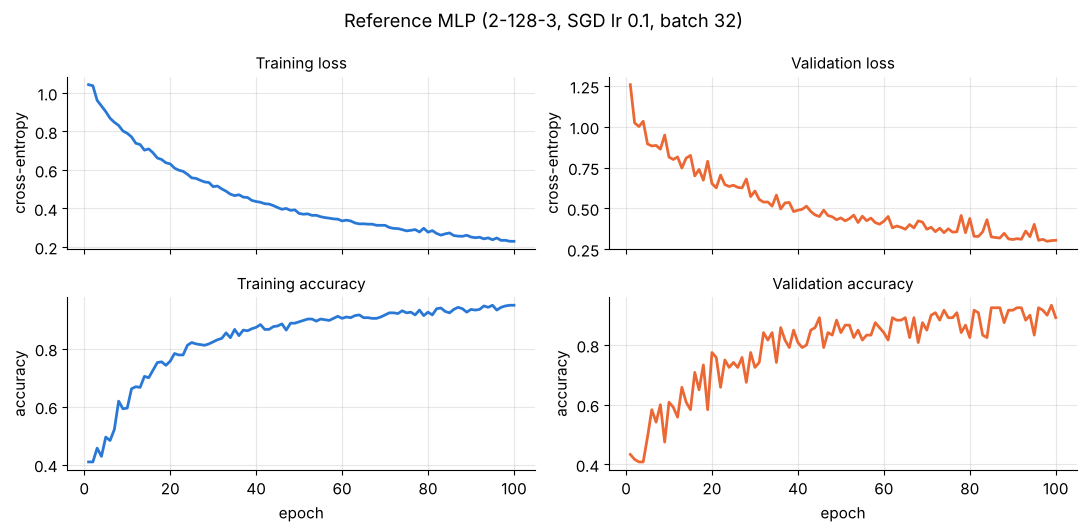

final epoch: {'train_loss': 0.2291, 'val_loss': 0.3039, 'train_acc': 0.95, 'val_acc': 0.8917}
best validation accuracy 0.9333 at epoch 99


In [35]:
def plot_history(history, title=None):
    """2x2 grid: training/validation loss (top) and accuracy (bottom)."""
    fig, axes = plt.subplots(2, 2, figsize=(11, 5.4), sharex=True)
    epochs_axis = np.arange(1, len(history["train_loss"]) + 1)
    panels = [("train_loss", "Training loss", TRAIN_COLOR), ("val_loss", "Validation loss", VAL_COLOR),
              ("train_acc", "Training accuracy", TRAIN_COLOR), ("val_acc", "Validation accuracy", VAL_COLOR)]
    for ax, (key, name, color) in zip(axes.flat, panels):
        ax.plot(epochs_axis, history[key], color=color, lw=2)
        ax.set_title(name, fontsize=11)
        ax.set_ylabel("cross-entropy" if "loss" in key else "accuracy")
    for ax in axes[1]:
        ax.set_xlabel("epoch")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history, "Reference MLP (2-128-3, SGD lr 0.1, batch 32)")
final = {k: v[-1] for k, v in history.items()}
best_epoch = int(np.argmax(history["val_acc"])) + 1
print("final epoch:", {k: round(v, 4) for k, v in final.items()})
print(f"best validation accuracy {max(history['val_acc']):.4f} at epoch {best_epoch}")

**Reading the curves.**

- Both losses fall steadily and both accuracies rise, and there is no sign of trouble such as a diverging loss or a validation loss that turns upward.
- At epoch 100 the curves are **still sloping**: the training loss is still going down and the training accuracy (0.950) is still climbing. The model has not converged, and it is *under-trained* rather than overfitted. Training longer, or with a larger learning rate, should help. Section 11 tests exactly this.
- The validation curves are much more jagged than the training curves. Two reasons: the validation set is small (one point = $1/120 \approx 0.8$ percentage points of accuracy), and each value is a snapshot of the weights after the epoch's last noisy SGD step, whereas the training values are averages over the 14 batches of the epoch. The best single validation value (0.933 at epoch 99) is partly luck, so do not read too much into one epoch.
- The training metrics are measured *during* the epoch while the weights keep changing, so they describe a slightly older model than the end-of-epoch validation metrics. That is why, early on, the validation accuracy can even exceed the training accuracy.

### 7.6 The test set, used once

Now, and only now, we evaluate on the test set, using the same `evaluate` function.

In [36]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
n_test = len(test_ds)
print(f"test loss {test_loss:.4f} | test accuracy {test_acc:.4f} = {round(test_acc * n_test)}/{n_test} correct")
se = math.sqrt(test_acc * (1 - test_acc) / n_test)
print(f"standard error of this accuracy estimate: about {se:.3f} (one test point = {1 / n_test:.3f})")

test loss 0.2878 | test accuracy 0.8833 = 53/60 correct
standard error of this accuracy estimate: about 0.041 (one test point = 0.017)


The test accuracy agrees with the validation accuracy of the final epoch within the statistical noise of such small sets. The standard error $\sqrt{p(1-p)/n}$ shows that with only 60 test points a single number like this has an uncertainty of a few percentage points, so treat it as "roughly 90%", not as a precise value.

### 7.7 A classic bug, measured: the double softmax

Section 6.6 predicted that putting a softmax inside the model cripples training and puts a floor of $0.5514$ under the loss. Let us train exactly the same network, same seed, same batches, with that one bug:

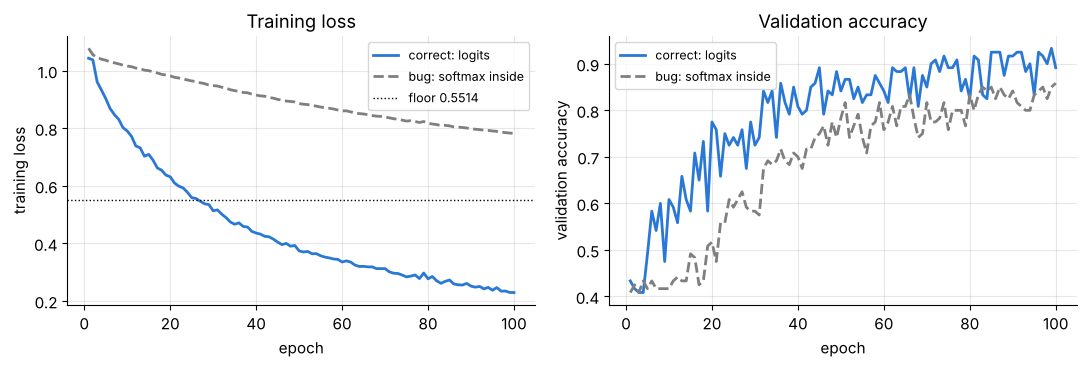

final training loss: correct 0.2291 | buggy 0.7819
final validation accuracy: correct 0.8917 | buggy 0.8583


In [37]:
class DoubleSoftmaxMLP(MLP):
    """The bug: forward returns probabilities, so CrossEntropyLoss applies a second softmax."""

    def forward(self, x):
        return torch.softmax(super().forward(x), dim=1)


torch.manual_seed(SEED)
buggy = DoubleSoftmaxMLP(input_dims, HIDDEN_DIMS, output_dims).to(DEVICE)
buggy_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(SEED))
buggy_history = fit(buggy, buggy_loader, val_loader, nn.CrossEntropyLoss(),
                    torch.optim.SGD(buggy.parameters(), lr=LR), epochs=EPOCHS, log_every=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ep = np.arange(1, EPOCHS + 1)
axes[0].plot(ep, history["train_loss"], color=TRAIN_COLOR, lw=2, label="correct: logits")
axes[0].plot(ep, buggy_history["train_loss"], color="#7f7f7f", lw=2, ls="--", label="bug: softmax inside")
axes[0].axhline(-math.log(math.e / (math.e + 2)), color="black", lw=1, ls=":", label="floor 0.5514")
axes[0].set(xlabel="epoch", ylabel="training loss", title="Training loss")
axes[0].legend(fontsize=9)
axes[1].plot(ep, history["val_acc"], color=TRAIN_COLOR, lw=2, label="correct: logits")
axes[1].plot(ep, buggy_history["val_acc"], color="#7f7f7f", lw=2, ls="--", label="bug: softmax inside")
axes[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"final training loss: correct {history['train_loss'][-1]:.4f} | buggy {buggy_history['train_loss'][-1]:.4f}")
print(f"final validation accuracy: correct {history['val_acc'][-1]:.4f} | buggy {buggy_history['val_acc'][-1]:.4f}")

The buggy model learns far more slowly. Its training loss is still about 0.78 after 100 epochs and can never go below the dotted floor, its gradients are squashed by the extra softmax, and its validation accuracy trails the correct model for almost the whole run. Nothing crashed and no warning appeared, which is exactly what makes this bug dangerous. A quick test catches it: print the model's raw outputs. If every row is non-negative and sums to 1, your model ends in a softmax.

## 8. Seeing the decision: regions, confidence and mistakes

### 8.1 Decision regions of the reference MLP

Same grid recipe as in Section 4.3, new model. On the left are the training points, and on the right are the validation and test points that the model never trained on, with mistakes circled.

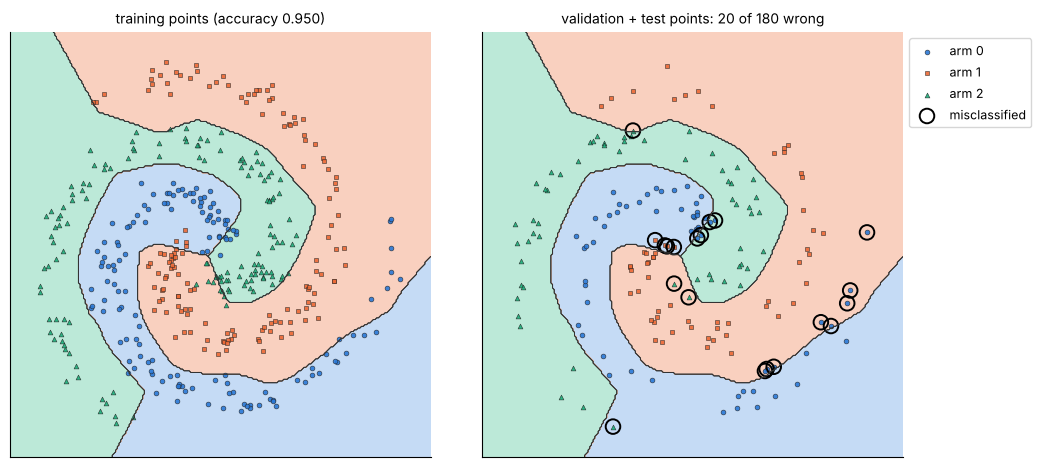

In [38]:
mlp_proba = lambda P: predict_proba(model, P, scaler)                 # original-unit points -> probabilities

X_holdout = np.concatenate([X_val, X_test])
y_holdout = np.concatenate([y_val, y_test])
pred_holdout = mlp_proba(X_holdout).argmax(axis=1)
wrong = pred_holdout != y_holdout

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
plot_regions(axes[0], mlp_proba, X_train, y_train, title=f"training points (accuracy {final['train_acc']:.3f})")
plot_regions(axes[1], mlp_proba, X_holdout, y_holdout,
             title=f"validation + test points: {wrong.sum()} of {len(y_holdout)} wrong", legend=True)
axes[1].scatter(X_holdout[wrong, 0], X_holdout[wrong, 1], s=110, facecolors="none", edgecolors="black",
                linewidths=1.4, label="misclassified")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
plt.tight_layout()
plt.show()

The boundary now **bends**: it follows the arms around the center instead of cutting straight across. Look closely and you will see that it is made of short straight segments joined at corners, and Section 9 explains why. The mistakes sit where we would expect: near the center, where the arms are closest, and at the outer tips, where training points are sparse and the model has to guess where an arm continues.

### 8.2 Probability and confidence maps

The argmax throws away the model's *confidence*. Plotting each class probability $p_c(\mathbf{x})$, and the **confidence** $\max_c p_c(\mathbf{x})$, shows where the model is sure and where it hesitates.

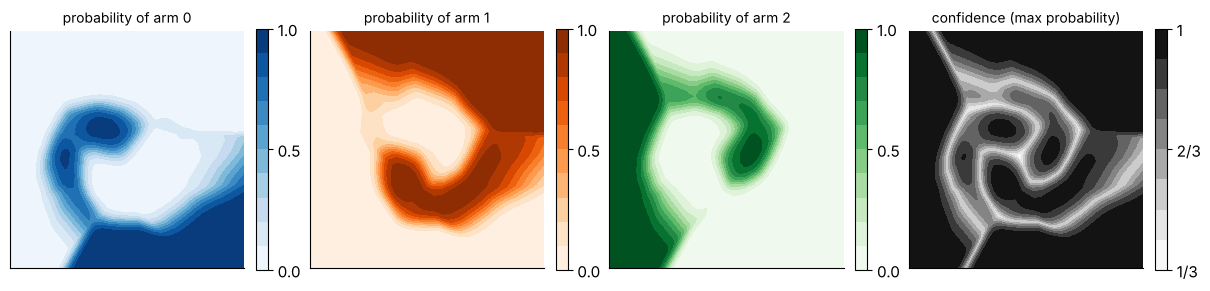

In [39]:
xx, yy, grid = make_grid(X, steps=200)
P_grid = mlp_proba(grid)                                               # (40000, 3)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), layout="constrained")
for k, cmap in enumerate(["Blues", "Oranges", "Greens"]):
    im = axes[k].contourf(xx, yy, P_grid[:, k].reshape(xx.shape), levels=np.linspace(0, 1, 11), cmap=cmap)
    axes[k].set_title(f"probability of arm {k}", fontsize=10)
    fig.colorbar(im, ax=axes[k], shrink=0.75, ticks=[0, 0.5, 1])
conf = P_grid.max(axis=1).reshape(xx.shape)
im_conf = axes[3].contourf(xx, yy, conf, levels=np.linspace(1 / 3, 1, 9), cmap="Greys")
axes[3].set_title("confidence (max probability)", fontsize=10)
cbar = fig.colorbar(im_conf, ax=axes[3], shrink=0.75, ticks=[1 / 3, 2 / 3, 1])
cbar.ax.set_yticklabels(["1/3", "2/3", "1"])
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.show()

Each class probability is high along its own arm and fades between arms. The confidence map is darkest in the middle of each arm and pale along the boundaries, where two probabilities are similar. The lowest confidence a 3-class model can show is $1/3$ (all three equal), reached near the center where all arms meet.

### 8.3 Far from the data, ReLU networks are overconfident

What does the model say about points **far outside** the region it was trained on? Let us zoom out to a window ten times wider than the data and also query three faraway points.

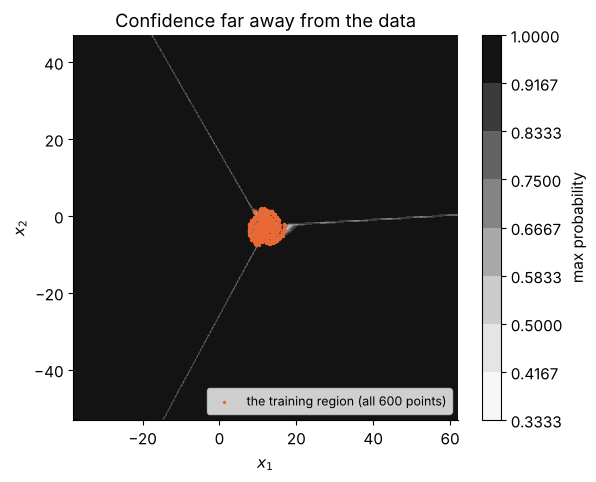

point [42. -3.] -> probabilities [1. 0. 0.]  (predicts arm 0)
point [ 12. -43.] -> probabilities [1. 0. 0.]  (predicts arm 0)
point [-23.  32.] -> probabilities [0. 0. 1.]  (predicts arm 2)


In [40]:
far_ref = CENTER + SCALE * np.array([[-10.0, -10.0], [10.0, 10.0]])  # a box 10x larger than the data
xx_far, yy_far, grid_far = make_grid(far_ref, steps=200, pad=0.0)
conf_far = mlp_proba(grid_far).max(axis=1).reshape(xx_far.shape)

fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.contourf(xx_far, yy_far, conf_far, levels=np.linspace(1 / 3, 1, 9), cmap="Greys")
ax.scatter(X[:, 0], X[:, 1], s=2, c="#eb6834", label="the training region (all 600 points)")
ax.set_aspect("equal")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Confidence far away from the data")
ax.grid(False)
ax.legend(loc="lower right", fontsize=9)
fig.colorbar(im, ax=ax, label="max probability")
plt.show()

far_points = CENTER + SCALE * np.array([[6.0, 0.0], [0.0, -8.0], [-7.0, 7.0]])
for pt, p in zip(far_points, mlp_proba(far_points)):
    print(f"point {pt.round(1)} -> probabilities {p.round(4)}  (predicts arm {p.argmax()})")

Almost the entire zoomed-out window is dark: the model is close to 100% sure about places where it has never seen a single point. This is not a bug of our training but a property of ReLU networks. The network is **piecewise linear** (Section 9), so far enough from the data, where no more folds occur, each logit is a linear function of $\mathbf{x}$. Along any ray going outward the logits grow linearly, their differences grow too, and the softmax saturates toward a one-hot vector. Only along the few directions where two logits grow at exactly the same rate does the confidence stay low.

> **Common pitfall.** A high softmax probability is **not** evidence that an input resembles the training data. Detecting "this input is unlike anything I was trained on" (out-of-distribution detection) needs separate tools, such as density models or distance-aware networks.

### 8.4 Mistakes and the confusion matrix

A **confusion matrix** $\mathbf{M}$ counts, for every pair (true class $i$, predicted class $j$), how many examples fall in that cell. The diagonal holds the correct predictions. We also list the validation examples with the largest individual loss, using `reduction="none"`.

In [41]:
with torch.no_grad():
    model.eval()
    val_logits = model(X_val_t.to(DEVICE)).cpu()
val_pred = val_logits.argmax(dim=1)
cm = confusion_matrix(y_val, val_pred.numpy())
display(pd.DataFrame(cm, index=[f"true arm {k}" for k in range(3)], columns=[f"pred arm {k}" for k in range(3)]))

per_example = F.cross_entropy(val_logits, y_val_t, reduction="none")
r_val, _ = polar_view(X_val)
hardest = torch.argsort(per_example, descending=True)[:6].numpy()
display(pd.DataFrame({
    "x1": X_val[hardest, 0], "x2": X_val[hardest, 1], "radius r": r_val[hardest],
    "true": y_val[hardest], "predicted": val_pred.numpy()[hardest],
    "p(true)": torch.softmax(val_logits, 1)[hardest, y_val[hardest]].numpy(),
    "loss": per_example.numpy()[hardest],
}).round(3))
print(f"median radius of all validation points: {np.median(r_val):.3f}")

,pred arm 0,pred arm 1,pred arm 2
true arm 0,33,4,3
true arm 1,3,37,0
true arm 2,1,2,37


,x1,x2,radius r,true,predicted,p(true),loss
0,11.850,-3.793,0.161,2,1,0.114,2.174
1,10.243,-7.556,0.977,2,0,0.119,2.128
2,11.352,-2.648,0.147,1,0,0.263,1.337
3,11.845,-2.829,0.046,1,0,0.263,1.334
4,11.609,-2.788,0.089,1,0,0.306,1.185
5,12.928,-2.130,0.254,0,2,0.332,1.104


median radius of all validation points: 0.552


The table confirms the visual impression: the costliest mistakes are points at small radius, where the arms crowd together, or at the far tips, where the training data runs out. Per-example losses are a great debugging tool in general, and on real data the highest-loss examples are often mislabeled.

### ✏️ Exercise 8: a confusion matrix with one `bincount`

Implement `confusion_matrix_torch(preds, targets, num_classes)` returning a `(C, C)` `long` tensor whose entry `[i, j]` counts examples with true class `i` and prediction `j`. Use no Python loop: map each pair to the single index `i * C + j`, count with `torch.bincount(..., minlength=C*C)` and reshape.

In [42]:
# ✏️ Exercise 8: confusion matrix via bincount
def confusion_matrix_torch(preds, targets, num_classes):
    """(C, C) tensor M with M[i, j] = #examples with true class i predicted as j."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    M = confusion_matrix_torch(val_pred, y_val_t, 3)
    assert tuple(M.shape) == (3, 3), f"shape {tuple(M.shape)}"
    assert np.array_equal(M.numpy(), cm), "does not match sklearn.metrics.confusion_matrix"
    M2 = confusion_matrix_torch(torch.tensor([0, 0, 0]), torch.tensor([0, 1, 1]), 4)
    expected = torch.zeros(4, 4, dtype=torch.long)
    expected[0, 0], expected[1, 0] = 1, 2
    assert torch.equal(M2, expected), "rows = true class, columns = predicted class, and keep empty classes"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def confusion_matrix_torch(preds, targets, num_classes):
    flat = targets * num_classes + preds                       # a unique id for every (true, pred) pair
    counts = torch.bincount(flat, minlength=num_classes ** 2)
    return counts.reshape(num_classes, num_classes)
```
The pair $(i, j)$ becomes the number $iC + j$, which is like writing $i$ and $j$ as the two digits of a base-$C$ number, so different pairs never collide. `minlength` guarantees all $C^2$ cells exist even when some never occur.
</details>

## 9. Inside the hidden layer

The trained network bends its boundary around the arms, but *how*? A network with one hidden layer is small enough that we can look at every moving part.

### 9.1 Each hidden unit is a ramp with a fold line

Hidden unit $j$ computes $h_j(\mathbf{x}) = \max(0,\ \mathbf{w}_j^\top\mathbf{x} + b_j)$, where $\mathbf{x}$ is the standardized input and $\mathbf{w}_j^\top$ is row $j$ of $\mathbf{W}_1$. The points where $\mathbf{w}_j^\top\mathbf{x} + b_j = 0$ form a straight line, the unit's **fold line**. On one side of it the unit is off ($h_j = 0$), and on the other side it grows in proportion to the distance from the line:

$$
h_j(\mathbf{x}) = \|\mathbf{w}_j\| \cdot \operatorname{dist}(\mathbf{x},\ \text{fold line } j) \qquad \text{on the active side.}
$$

Picture a flat sheet of paper creased along one line, with one half lifted into a ramp. The output layer then adds up 128 such ramps with weights, one weighted sum per class:

$$
z_c(\mathbf{x}) = \sum_{j=1}^{128} W_2[c, j]\, h_j(\mathbf{x}) + b_{2,c}.
$$

So column $j$ of $\mathbf{W}_2$ says how unit $j$ "votes": wherever the unit is active, it raises the logit of every class $c$ with $W_2[c, j] > 0$ and lowers the others, in proportion to how far the point lies past the fold line. Below are the eight units with the largest outgoing weights $\|\mathbf{W}_2[:, j]\|$, drawn as functions on the plane (original units, darker = larger $h_j$), with each fold line in red.

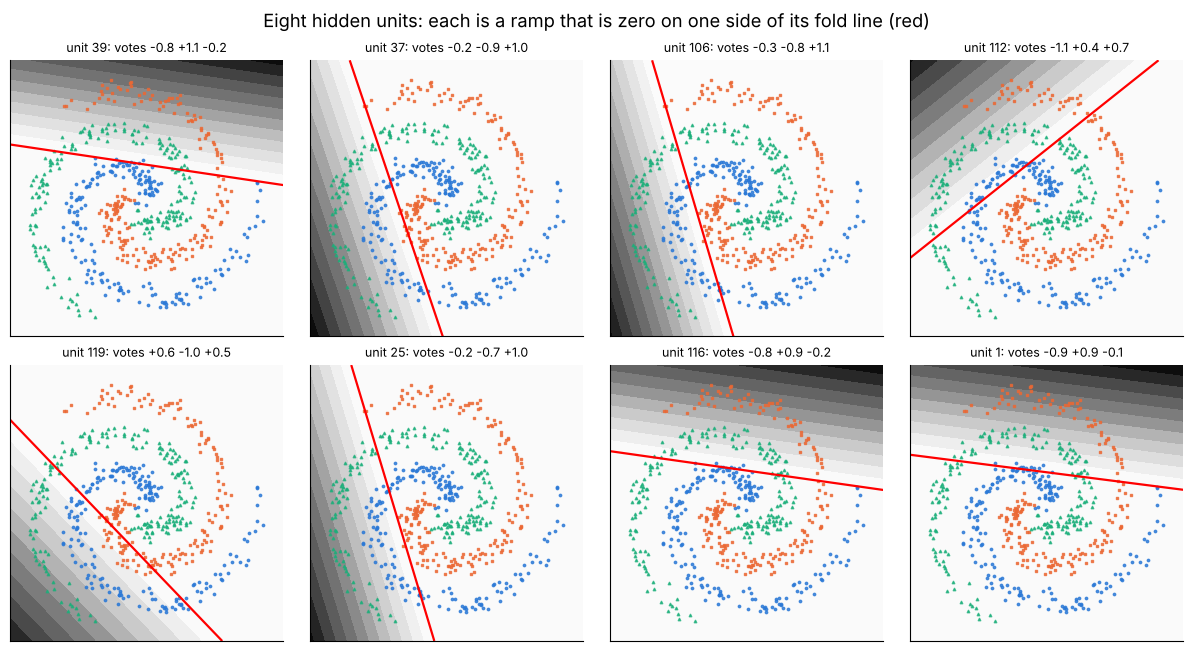

In [43]:
xx, yy, grid = make_grid(X, steps=200)
grid_t = torch.tensor(scaler.transform(grid), dtype=torch.float32, device=DEVICE)
model.eval()
with torch.no_grad():
    A_grid = model.linear1(grid_t).cpu().numpy()                 # (40000, 128) pre-activations a = W1 x + b1
H_grid = np.maximum(A_grid, 0.0)                                  # hidden features h = ReLU(a)
W1 = model.linear1.weight.detach().cpu().numpy()                  # (128, 2)
b1 = model.linear1.bias.detach().cpu().numpy()                    # (128,)
W2 = model.output.weight.detach().cpu().numpy()                   # (3, 128)
influence = np.linalg.norm(W2, axis=0)                            # size of each unit's outgoing weights
top_units = np.argsort(influence)[::-1][:8]

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4), layout="constrained")
for ax, j in zip(axes.flat, top_units):
    ax.contourf(xx, yy, H_grid[:, j].reshape(xx.shape), levels=12, cmap="Greys")
    ax.contour(xx, yy, A_grid[:, j].reshape(xx.shape), levels=[0.0], colors="red", linewidths=1.6)
    for k in range(3):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=3, c=CLASS_COLORS[k], marker=CLASS_MARKERS[k], alpha=0.8)
    ax.set_title(f"unit {j}: votes " + " ".join(f"{v:+.1f}" for v in W2[:, j]), fontsize=9)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Eight hidden units: each is a ramp that is zero on one side of its fold line (red)")
plt.show()

Every panel shows the same shape: white (off) on one side of a straight red line, a ramp that darkens steadily on the other side. The "votes" in each title are the unit's column of $\mathbf{W}_2$ (its effect on the logits of arms 0, 1, 2). No single ramp looks anything like a spiral, but the spiral emerges from the weighted **sum** of 128 of them.

To see the sum at work, walk along a straight segment through the data. Along a segment $\mathbf{x}(t) = \mathbf{A} + t(\mathbf{B} - \mathbf{A})$, $t \in [0, 1]$, every pre-activation $a_j(t)$ is a linear function of $t$, so every $h_j(t)$ is zero up to some point and linear after it (or the reverse), and every logit is a sum of such pieces: a **piecewise linear** curve whose corners ("kinks") sit exactly where the segment crosses a fold line. Because $a_j$ is linear in $t$, the crossing is at $t_j^* = -a_j(0) / (a_j(1) - a_j(0))$, which we can compute exactly.

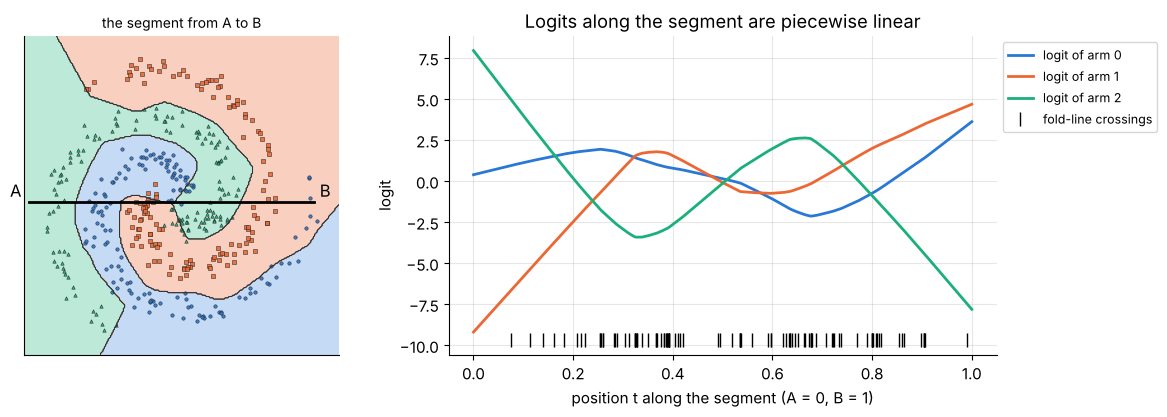

the segment crosses 95 of the 128 fold lines -> each logit is made of 96 straight pieces


In [44]:
A_pt, B_pt = CENTER + SCALE * np.array([-1.0, 0.0]), CENTER + SCALE * np.array([1.0, 0.0])
t_path = np.linspace(0.0, 1.0, 801)
seg = A_pt + t_path[:, None] * (B_pt - A_pt)                      # (801, 2) points along the segment
with torch.no_grad():
    seg_t = torch.tensor(scaler.transform(seg), dtype=torch.float32, device=DEVICE)
    a_seg = model.linear1(seg_t).cpu().numpy()                     # (801, 128)
    z_seg = model(seg_t).cpu().numpy()                             # (801, 3)
a_start, a_end = a_seg[0], a_seg[-1]
with np.errstate(divide="ignore", invalid="ignore"):              # units parallel to the segment give 0/0
    t_star = -a_start / (a_end - a_start)
kinks = np.sort(t_star[(t_star > 0) & (t_star < 1)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.5]})
plot_regions(axes[0], mlp_proba, X_train, y_train, title="the segment from A to B", s=6)
axes[0].plot(*np.array([A_pt, B_pt]).T, color="black", lw=2)
axes[0].annotate("A", A_pt, xytext=(-14, 4), textcoords="offset points", fontsize=12)
axes[0].annotate("B", B_pt, xytext=(4, 4), textcoords="offset points", fontsize=12)
for k in range(3):
    axes[1].plot(t_path, z_seg[:, k], color=CLASS_COLORS[k], lw=2, label=f"logit of arm {k}")
lo = z_seg.min() - 0.5
axes[1].plot(kinks, np.full_like(kinks, lo), "|", color="black", ms=10, label="fold-line crossings")
axes[1].set(xlabel="position t along the segment (A = 0, B = 1)", ylabel="logit",
            title="Logits along the segment are piecewise linear")
axes[1].legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()
print(f"the segment crosses {len(kinks)} of the 128 fold lines -> each logit is made of {len(kinks) + 1} straight pieces")

Between two consecutive tick marks no unit switches on or off, so each logit is exactly a straight line there, and at a tick, the slopes change. The predicted class along the segment is whichever colored line is on top, and the class changes where two lines cross. Folding a function many times, in the right places, is how a ReLU network approximates a curved boundary.

### 9.2 Linear regions: the plane cut into polygons

Now draw all 128 fold lines at once. They cut the plane into convex polygons called **linear regions**. Inside one region every unit stays in the same state (on or off), so the network collapses to one fixed affine function. If $\mathbf{m} \in \{0, 1\}^{128}$ records which units are on (the **activation pattern**) and $\mathbf{D} = \operatorname{diag}(\mathbf{m})$, then for every $\mathbf{x}$ in that region

$$
\mathbf{z}(\mathbf{x}) = \mathbf{W}_2\mathbf{D}(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2
  = \underbrace{\mathbf{W}_2\mathbf{D}\mathbf{W}_1}_{3 \times 2}\,\mathbf{x} + \underbrace{\mathbf{W}_2\mathbf{D}\mathbf{b}_1 + \mathbf{b}_2}_{3}.
$$

Within one region the network *is* a softmax regression, so there the class boundary is straight (Section 4.1). Globally, the boundary is a chain of straight segments that can change direction at every region border. That is the "made of short straight segments" look from Section 8.1.

**How many regions can 128 lines make?** Add lines one at a time. A new line crosses each earlier line at most once, so the first $k - 1$ lines cut the $k$-th line into at most $k$ pieces, and each piece splits one existing region into two. Starting from 1 region (the whole plane), $n$ lines therefore create at most

$$
1 + \sum_{k=1}^{n} k = 1 + \frac{n(n+1)}{2} \qquad \text{regions;} \qquad n = 128:\ 1 + \frac{128 \cdot 129}{2} = 8257,
$$

with equality when no two lines are parallel and no three meet at a point ("general position"). We can count the regions that actually appear in the picture by evaluating the activation pattern on a fine grid and counting the **distinct** patterns, which is a job for `torch.unique(..., dim=0)` (it returns the distinct rows of a matrix).

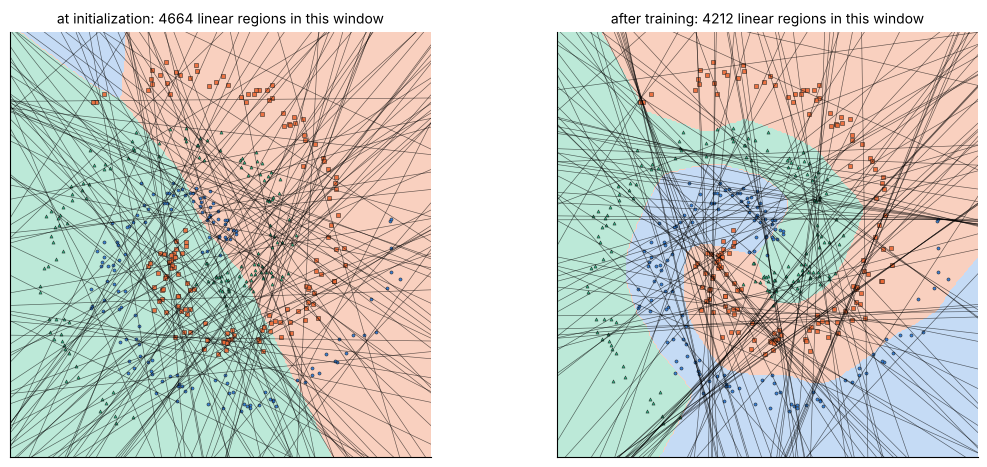

distinct activation patterns on the grid: {'at initialization': 4664, 'after training': 4212} | upper bound for 128 lines: 8257
median distance from the spiral center to a fold line (standardized units): {'at initialization': 0.716, 'after training': 0.72}
linear1.weight changed by 52% of its initial size during training
output.weight changed by 786% of its initial size during training


In [45]:
def activation_patterns(net, points_std):
    """On/off pattern of the first hidden layer, shape (n, hidden): True where a_j > 0."""
    with torch.no_grad():
        return net.linear1(torch.as_tensor(points_std, dtype=torch.float32)) > 0


def draw_fold_lines(ax, net, scaler, **kw):
    """Draw every first-layer fold line w.z + b = 0, converted to original units (it stays a line)."""
    W = net.linear1.weight.detach().cpu().numpy() / scaler.scale_      # z = (x - mu) / sigma  ->  (w / sigma) . x
    c = net.linear1.bias.detach().cpu().numpy() - W @ scaler.mean_     # ... + (b - (w / sigma) . mu) = 0
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    for (a1, a2), c0 in zip(W, c):
        foot = CENTER - (a1 * CENTER[0] + a2 * CENTER[1] + c0) / (a1**2 + a2**2) * np.array([a1, a2])
        ax.axline(foot, foot + np.array([-a2, a1]), **kw)              # point nearest the center + direction
    ax.set_xlim(xlim)                                                  # infinite lines must not widen the view
    ax.set_ylim(ylim)


def fold_distance_to_center(net, scaler):
    """Distance (in standardized units) from the spiral's center to each fold line."""
    c_std = torch.tensor(scaler.transform(CENTER[None]), dtype=torch.float32)[0]
    W, b = net.linear1.weight.detach().cpu(), net.linear1.bias.detach().cpu()
    return ((W @ c_std + b).abs() / W.norm(dim=1)).numpy()


torch.manual_seed(SEED)
model_at_init = MLP(input_dims, HIDDEN_DIMS, output_dims)          # the exact starting point of `model`
_, _, grid_r = make_grid(X, steps=300, pad=0.8)                    # 90,000 points covering the data
grid_r_std = scaler.transform(grid_r)
region_counts, median_dist = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for ax, (name, net) in zip(axes, [("at initialization", model_at_init), ("after training", model)]):
    patterns = activation_patterns(net.cpu(), grid_r_std)          # (90000, 128) booleans
    region_counts[name] = torch.unique(patterns, dim=0).shape[0]   # distinct rows = distinct regions hit
    median_dist[name] = round(float(np.median(fold_distance_to_center(net, scaler))), 3)
    plot_regions(ax, lambda P, net=net: predict_proba(net, P, scaler), X_train, y_train, s=5, boundary=False,
                 title=f"{name}: {region_counts[name]} linear regions in this window")
    draw_fold_lines(ax, net, scaler, color="black", lw=0.45, alpha=0.6)
plt.tight_layout()
plt.show()
model = model.to(DEVICE)
print("distinct activation patterns on the grid:", region_counts, "| upper bound for 128 lines: 8257")
print("median distance from the spiral center to a fold line (standardized units):", median_dist)
for name in ("linear1", "output"):
    w0, w1 = getattr(model_at_init, name).weight, getattr(model, name).weight.detach().cpu()
    print(f"{name}.weight changed by {((w1 - w0).norm() / w0.norm()).item():.0%} of its initial size during training")

Compare the two pictures. At initialization the fold lines are scattered at random, and the region colors come from an untrained output layer. After training the lines have shifted and turned, yet the overall layout is similar: the median distance of a fold line from the spiral center barely moved, and the window still holds a few thousand regions (out of at most 8257). The printed weight changes say the same in numbers: the first-layer weights moved by about half of their initial size, while the output weights changed by almost eight times theirs. With 128 units, the random initial folds already cut the data region into thousands of small polygons, and training mostly learns how to *weight* the ramps, while nudging the folds into better places. (Only a few thousand of the 8257 possible regions appear here because many crossings of the lines happen outside the window.)

> **Going deeper.** For deeper networks, the number of linear regions can grow *exponentially* with depth (each layer can fold the already-folded space again), whereas one wide layer only gives polynomially many. This is one theoretical argument for depth (Montúfar et al., 2014, in "Going further"). In practice, trained networks use far fewer regions than the theoretical maximum.

### 9.3 Why standardization matters: folds must cross the data

A fold line is only useful if it passes **through** the data. A unit whose line misses the data cloud is either off for every training point (it outputs 0, receives zero gradient and never learns: a **dead** unit) or on for every point (then it is just a linear function on the data and adds no bending). Section 2.2 claimed that PyTorch's default initialization puts fold lines near the origin, so they only cut through data that is centered there. Let us count, for the same freshly initialized network, how many fold lines cross the training cloud when it is given standardized inputs and when it is given raw inputs.

In [46]:
def fraction_crossing(net, points):
    """Fraction of first-layer units that are on for some points and off for others."""
    with torch.no_grad():
        a = net.linear1(torch.as_tensor(points, dtype=torch.float32))
    return ((a > 0).any(dim=0) & (a <= 0).any(dim=0)).float().mean().item()


print(f"fold lines crossing the training data at initialization: "
      f"standardized inputs {fraction_crossing(model_at_init, X_train_s):.1%} | "
      f"raw inputs {fraction_crossing(model_at_init, X_train):.1%}")

# The reference recipe again, but on raw (unstandardized) inputs.
torch.manual_seed(SEED)
raw_model = MLP(input_dims, HIDDEN_DIMS, output_dims).to(DEVICE)
raw_train_loader = DataLoader(SpiralDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED))
raw_val_loader = DataLoader(SpiralDataset(X_val, y_val), batch_size=BATCH_SIZE)
raw_history = fit(raw_model, raw_train_loader, raw_val_loader, nn.CrossEntropyLoss(),
                  torch.optim.SGD(raw_model.parameters(), lr=LR), epochs=EPOCHS, log_every=0)
print(f"raw inputs, after {EPOCHS} epochs: train acc {raw_history['train_acc'][-1]:.3f}, "
      f"val acc {raw_history['val_acc'][-1]:.3f}, train loss {raw_history['train_loss'][-1]:.4f} "
      f"(standardized: val acc {history['val_acc'][-1]:.3f})")

fold lines crossing the training data at initialization: standardized inputs 96.9% | raw inputs 24.2%


raw inputs, after 100 epochs: train acc 0.471, val acc 0.425, train loss 0.9057 (standardized: val acc 0.892)


With standardized inputs almost every fold line (about 97%) passes through the data, so almost every unit can bend the function where it matters. With raw inputs only about a quarter do: the data cloud sits around $(12, -3)$, far from where the initial fold lines are, and three quarters of the hidden layer starts out either dead or purely linear on the data. The same training recipe then fails badly, with validation accuracy near 0.43 after 100 epochs, little better than the linear baseline of Section 4 and far below the 0.89 of the standardized run. (The large raw input values also make the first-layer gradients large and uneven, which is the second problem standardization solves.)

### 9.4 The hidden layer as a new coordinate system

Here is another way to read the network. The output layer, $\mathbf{z} = \mathbf{W}_2\mathbf{h} + \mathbf{b}_2$, is nothing but **softmax regression on the hidden features** $\mathbf{h} \in \mathbb{R}^{128}$. A linear classifier can only succeed if the classes are (nearly) linearly separable in the space it sees, so training must have produced coordinates $\mathbf{h}$ in which the three arms *are* nearly linearly separable, even though they are hopelessly intertwined in the original coordinates $(x_1, x_2)$. The first layer is a learned **feature map** $\mathbb{R}^2 \to \mathbb{R}^{128}$, and the second is a linear classifier on top of it.

We cannot plot 128 dimensions, but **PCA** (principal component analysis) finds the two directions along which the hidden vectors vary most and projects onto them. We also run **linear probes**: fit a fresh logistic regression on a set of features and see how well a purely linear model can do with them. A high probe accuracy means the classes are close to linearly separable in that representation.

In [47]:
model.eval()
with torch.no_grad():
    H_train = model.hidden(X_train_t.to(DEVICE)).cpu().numpy()        # (420, 128) trained features
    H_val = model.hidden(X_val_t.to(DEVICE)).cpu().numpy()            # (120, 128)
    H0_train = model_at_init.hidden(X_train_t).numpy()                 # same layer before training
    H0_val = model_at_init.hidden(X_val_t).numpy()
    own_train_acc = compute_accuracy(model(X_train_t.to(DEVICE)).cpu(), y_train_t)
    own_val_acc = compute_accuracy(model(X_val_t.to(DEVICE)).cpu(), y_val_t)

pca = PCA(n_components=2).fit(H_train)
P_train, P_val = pca.transform(H_train), pca.transform(H_val)


def linear_probe(F_train, F_val):
    """Train/validation accuracy of a logistic regression fitted on the given features."""
    clf = LogisticRegression(max_iter=5000).fit(F_train, y_train)
    return clf.score(F_train, y_train), clf.score(F_val, y_val)


probes = pd.DataFrame({
    "raw inputs (2 numbers)": linear_probe(X_train_s, X_val_s),
    "hidden layer before training (128)": linear_probe(H0_train, H0_val),
    "hidden layer after training (128)": linear_probe(H_train, H_val),
    "2 PCA components of trained layer": linear_probe(P_train, P_val),
    "the network's own output layer": (own_train_acc, own_val_acc),
}, index=["train accuracy", "validation accuracy"]).T
display(probes.round(4))
print(f"dead units (never active on training data): {(H_train == 0).all(axis=0).sum()} | "
      f"always-on units (purely linear on the data): {(H_train > 0).all(axis=0).sum()} | "
      f"PCA: 2 components explain {pca.explained_variance_ratio_.sum():.1%} of the hidden-feature variance")

,train accuracy,validation accuracy
raw inputs (2 numbers),0.3690,0.4083
hidden layer before training (128),0.9548,0.9250
hidden layer after training (128),0.9738,0.9500
2 PCA components of trained layer,0.3738,0.4167
the network's own output layer,0.9262,0.8917


dead units (never active on training data): 2 | always-on units (purely linear on the data): 3 | PCA: 2 components explain 78.9% of the hidden-feature variance


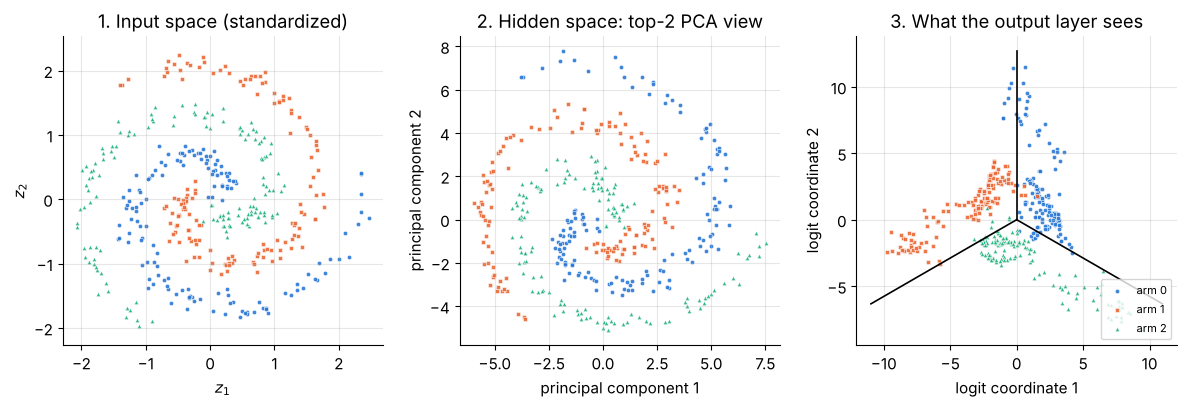

validation accuracy of a linear probe on the top-k principal components of the trained hidden layer:
  k=1: 0.350 | k=2: 0.417 | k=3: 0.392 | k=5: 0.408 | k=10: 0.917 | k=20: 0.950 | k=40: 0.950 | k=128: 0.950


In [48]:
with torch.no_grad():
    Z_train = model(X_train_t.to(DEVICE)).cpu().numpy()              # (420, 3) logits of the training points
U = np.array([[1, -1, 0], [1, 1, -2]]) / np.array([[np.sqrt(2)], [np.sqrt(6)]])   # orthonormal, both _|_ (1,1,1)
Z_plane = Z_train @ U.T                                              # (420, 2) logits seen up to a common shift

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
scatter_classes(axes[0], X_train_s, y_train, s=10)
axes[0].set(xlabel="$z_1$", ylabel="$z_2$", title="1. Input space (standardized)")
scatter_classes(axes[1], P_train, y_train, s=10)
axes[1].set(xlabel="principal component 1", ylabel="principal component 2", title="2. Hidden space: top-2 PCA view")
scatter_classes(axes[2], Z_plane, y_train, s=10)
reach = np.abs(Z_plane).max() * 1.1
for k in range(3):                                                   # boundary rays: where two logits tie on top
    ray = -U @ np.eye(3)[k]                                          # direction where class k is the loser
    axes[2].plot([0, reach * ray[0] / np.linalg.norm(ray)], [0, reach * ray[1] / np.linalg.norm(ray)], color="black", lw=1.2)
axes[2].set(xlabel="logit coordinate 1", ylabel="logit coordinate 2", title="3. What the output layer sees")
axes[2].legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.show()

ks = [1, 2, 3, 5, 10, 20, 40, 128]
pca_all = PCA().fit(H_train)
probe_k = [linear_probe(pca_all.transform(H_train)[:, :k], pca_all.transform(H_val)[:, :k])[1] for k in ks]
print("validation accuracy of a linear probe on the top-k principal components of the trained hidden layer:")
print("  " + " | ".join(f"k={k}: {acc:.3f}" for k, acc in zip(ks, probe_k)))

**Reading the table and the pictures.**

- **Raw inputs:** a linear probe stays near chance, as Section 4 proved it must.
- **Hidden layer before training:** above 0.9 on validation. One hundred twenty-eight *random* ramps, followed by a carefully fitted linear classifier, already separate the arms well. Mapping the data nonlinearly into many dimensions tends to make classes linearly separable, and this is the idea behind **random-features** methods and kernel machines.
- **Hidden layer after training:** better still. Training improved the features themselves.
- **The network's own output layer:** clearly *below* a logistic regression fitted on the very same trained features. The network's output weights are not yet the best possible ones for its own features: 100 epochs of plain SGD left the model under-trained, which matches the still-sloping curves of Section 7.5.
- **PCA:** the two directions of largest variance hold most of the variance, yet a linear probe on them is no better than on the raw inputs. Panel 2 shows why: the top principal components mostly reproduce the input geometry (a stretched spiral), because many ramps vary almost linearly across the data. The class information lives in lower-variance directions: the probe stays near chance with up to five components, then jumps to about 0.92 with ten and reaches the full 128-dimensional value with twenty. "Nearly linearly separable" is a statement about the full 128-dimensional space, not about any two-dimensional picture of it.
- **Dead and always-on units:** only 2 of the 128 units are never active on the training data and only 3 are always active, and the other 123 change state somewhere inside the data cloud, as Section 9.3 promised for standardized inputs.
- **Panel 3** shows the hidden vectors the way the output layer sees them: their logits, projected onto the plane perpendicular to $(1, 1, 1)$. Adding the same number to all three logits never changes the softmax, so this projection loses nothing. In that plane the classifier is three straight rays from the origin, precisely the three convex wedges of Section 4. The network has not escaped linearity at the output, and it has moved the data into a space where a linear cut works.

> **Key idea.** An MLP is a **learned feature map followed by a linear classifier**. The hidden layer folds and stretches the input space, and the output layer cuts the result with straight lines. Everything you learned about linear classifiers still applies, but in the learned coordinates.

<details>
<summary><b>Quick check</b>: a classmate claims the hidden layer "must have learned the polar coordinates $(r, \phi)$" of Section 1.4. How could you test this claim with the tools of this section?</summary>

Fit linear probes that *predict* those quantities from $\mathbf{h}$: a linear regression from $\mathbf{h}$ to $r$, and one from $\mathbf{h}$ to $(\cos\phi, \sin\phi)$ (the angle itself jumps at $2\pi$, so predict its cosine and sine). If $\mathbf{h}$ contains these coordinates in linearly readable form, the probes will have a high $R^2$ on validation data (compare with the same probes on the random hidden layer as a baseline). Probes measure what is *linearly decodable*, which is exactly what the next linear layer can use.
</details>

### ✏️ Exercise 9: the affine map inside one linear region

Implement `local_affine_map(net, x_std)` for a one-hidden-layer `MLP` and one standardized point `x_std` of shape `(2,)`. Return `(W_eff, b_eff)` with shapes `(3, 2)` and `(3,)` such that `net(x') = W_eff @ x' + b_eff` for every `x'` in the same linear region as `x_std` (the formula of Section 9.2). The checker compares your matrix with the Jacobian computed by autograd and tests the toy network of Section 5.5.

In [49]:
# ✏️ Exercise 9: local affine map of a ReLU network
def local_affine_map(net, x_std):
    """(W_eff, b_eff) with net(x') = W_eff @ x' + b_eff on the linear region containing x_std."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    net = MLP(input_dims, HIDDEN_DIMS, output_dims)
    net.load_state_dict(model.state_dict())                     # a CPU copy of the trained model
    x0 = X_train_t[7]
    W_eff, b_eff = local_affine_map(net, x0)
    assert tuple(W_eff.shape) == (3, 2) and tuple(b_eff.shape) == (3,), "shapes must be (3, 2) and (3,)"
    with torch.no_grad():
        assert torch.allclose(W_eff @ x0 + b_eff, net(x0), atol=1e-4), "W_eff @ x + b_eff must equal net(x)"
    jac = torch.autograd.functional.jacobian(net, x0)           # (3, 2): d logits / d input at x0
    assert torch.allclose(W_eff, jac, atol=1e-4), "W_eff must equal the Jacobian of the network at x0"
    W_toy, b_toy = local_affine_map(toy, torch.tensor([1.0, -2.0]))
    assert torch.allclose(W_toy, torch.tensor([[1.0, -0.5], [-2.0, 1.0], [2.0, -1.0]])), f"toy W_eff: {W_toy}"
    assert torch.allclose(b_toy, torch.tensor([-0.5, 2.0, -1.0])), f"toy b_eff: {b_toy}"


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def local_affine_map(net, x_std):
    W1, b1 = net.linear1.weight, net.linear1.bias              # (H, 2), (H,)
    W2, b2 = net.output.weight, net.output.bias                # (3, H), (3,)
    with torch.no_grad():
        m = (W1 @ x_std + b1 > 0).float()                      # activation pattern, (H,)
        W_eff = W2 @ (m[:, None] * W1)                         # W2 D W1 without building D
        b_eff = W2 @ (m * b1) + b2                             # W2 D b1 + b2
    return W_eff, b_eff
```
Multiplying row $j$ of $\mathbf{W}_1$ by $m_j$ is the same as computing $\mathbf{D}\mathbf{W}_1$ with $\mathbf{D} = \operatorname{diag}(\mathbf{m})$, but avoids an $H \times H$ matrix. In the toy network only hidden unit 2 is on, so $\mathbf{W}_\text{eff}$ is the outer product of the second column of $\mathbf{W}_2$, $(0.5, -1, 1)$, with the second row of $\mathbf{W}_1$, $(2, -1)$. The Jacobian test works because inside a linear region the derivative of an affine map is its matrix.
</details>

## 10. Reproducible experiments: seeds, evaluation mode and a fast trainer

Sections 11 and 12 train about a hundred networks to compare settings. Before running experiments we need three things: control over randomness, an honest idea of how much results vary by chance, and a trainer fast enough to run many configurations on a CPU.

### 10.1 Where randomness enters, and how to pin it down

| source of randomness | where it happens | how this notebook controls it |
|---|---|---|
| the data itself | `make_spiral_arms` | its own `np.random.default_rng(seed)` |
| the train/validation/test split | `train_test_split` | `random_state=SEED` |
| initial weights | `nn.Linear(...)` draws from the **global** torch generator | `torch.manual_seed(seed)` right before building the model |
| batch order | `DataLoader(shuffle=True)` | its own `torch.Generator().manual_seed(seed)` |
| dropout masks (Section 12) | `nn.Dropout` uses the global torch generator | `torch.manual_seed(seed)` |
| non-deterministic kernels | some GPU operations (atomic additions) sum in a varying order | not needed here: on a CPU with one thread (setup cell), this notebook's operations repeat exactly, and on a GPU, add `torch.use_deterministic_algorithms(True)` (see PyTorch's reproducibility notes) |

Two details deserve emphasis. First, the global generator is a **stream**: every random call advances it, so `torch.manual_seed(SEED)` must come *immediately* before the model is built, otherwise any random call in between (an innocent `torch.randn` while debugging) changes the initial weights. Second, giving the `DataLoader` its own generator decouples the batch order from everything else. Let us verify that a seed fully determines a training run:

In [50]:
def run_reference(seed, epochs=5):
    """Build and briefly train the reference MLP with one seed for weights and shuffling."""
    torch.manual_seed(seed)
    net = MLP(input_dims, HIDDEN_DIMS, output_dims).to(DEVICE)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(seed))
    hist = fit(net, loader, val_loader, nn.CrossEntropyLoss(), torch.optim.SGD(net.parameters(), lr=LR),
               epochs=epochs, log_every=0)
    return net, hist


net_a, hist_a = run_reference(seed=7)
torch.randn(3)                                    # an unrelated random call between the runs ...
net_b, hist_b = run_reference(seed=7)             # ... does not matter: the seed is set inside
net_c, hist_c = run_reference(seed=8)
same = all(torch.equal(p, q) for p, q in zip(net_a.parameters(), net_b.parameters()))
print(f"seed 7 twice -> identical weights: {same}, identical validation curve: {hist_a['val_acc'] == hist_b['val_acc']}")
print(f"seed 7 vs 8  -> first-layer weights differ by up to "
      f"{(net_a.linear1.weight - net_c.linear1.weight).abs().max().item():.3f}")
print("validation accuracy after 5 epochs, seeds 7 / 7 / 8:",
      [round(h["val_acc"][-1], 4) for h in (hist_a, hist_b, hist_c)])

seed 7 twice -> identical weights: True, identical validation curve: True
seed 7 vs 8  -> first-layer weights differ by up to 1.277
validation accuracy after 5 epochs, seeds 7 / 7 / 8: [0.45, 0.45, 0.4833]


> **Going deeper.** Bit-for-bit reproducibility holds for the same code, library versions and hardware. A different PyTorch version, a different CPU instruction set or a GPU can change the last bits of floating-point sums, and those tiny differences grow during training. That is why we never trust a single run anyway, as the next sections show. For full determinism on a GPU, PyTorch's reproducibility notes (see "Going further") list the extra switches.

### 10.2 A fast trainer for experiments

The `DataLoader` is general: it can stream data from disk, apply transforms and use worker processes. For a few hundred points that already sit in memory as one tensor, its per-example Python calls are pure overhead. The function below performs **exactly the same mini-batch updates** by shuffling indices itself (`torch.randperm`) and slicing the tensors. It also measures the training metrics at the *end* of each epoch in evaluation mode, like the validation metrics, so the two curves describe the same weights. It builds models with a small factory, `make_mlp`, so the experiments can vary depth, width, activation and dropout.

In [51]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": lambda: nn.LeakyReLU(0.1), "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}


def make_mlp(hidden=(128,), activation="relu", dropout=0.0, d_in=2, d_out=3, seed=SEED):
    """Linear -> activation [-> Dropout] for each hidden width, then a final Linear to d_out logits."""
    torch.manual_seed(seed)
    layers, prev = [], d_in
    for width in hidden:
        layers += [nn.Linear(prev, width), ACTIVATIONS[activation]()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        prev = width
    layers.append(nn.Linear(prev, d_out))
    return nn.Sequential(*layers).to(DEVICE)


def make_optimizer(params, name, lr, momentum=0.0, weight_decay=0.0):
    """'sgd' (optionally with momentum), 'adam' or 'adamw'."""
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=momentum, weight_decay=weight_decay)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":
        return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"unknown optimizer {name!r}")

In [52]:
def train_fast(model, X_tr, y_tr, X_va, y_va, *, epochs=100, lr=0.1, batch_size=32, optimizer="sgd",
               momentum=0.0, weight_decay=0.0, seed=SEED, shuffle=True, keep_best=False):
    """Mini-batch training on in-memory tensors. Returns a history dict of end-of-epoch metrics.

    keep_best=True restores the weights from the epoch with the lowest validation loss
    (early stopping, Section 12.2) and records that epoch in history["best_epoch"].
    """
    X_tr, y_tr, X_va, y_va = (t.to(DEVICE) for t in (X_tr, y_tr, X_va, y_va))
    gen = torch.Generator().manual_seed(seed)
    opt = make_optimizer(model.parameters(), optimizer, lr, momentum, weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, n = float("inf"), None, len(y_tr)
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n, generator=gen).to(DEVICE) if shuffle else torch.arange(n, device=DEVICE)
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            loss = loss_fn(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            for split, Xs, ys in (("train", X_tr, y_tr), ("val", X_va, y_va)):
                logits = model(Xs)
                history[f"{split}_loss"].append(loss_fn(logits, ys).item())
                history[f"{split}_acc"].append(compute_accuracy(logits, ys))
        if keep_best and history["val_loss"][-1] < best_loss:
            best_loss = history["val_loss"][-1]
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            history["best_epoch"] = epoch + 1
    if keep_best:
        model.load_state_dict(best_state)
    return history

Is it really the same computation? With shuffling switched off, both trainers see identical batches in identical order, so after a few epochs their weights must agree exactly. Then we compare speed on the full reference recipe.

In [53]:
torch.manual_seed(SEED)
net_loader = MLP(input_dims, HIDDEN_DIMS, output_dims).to(DEVICE)
fit(net_loader, DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False), val_loader, nn.CrossEntropyLoss(),
    torch.optim.SGD(net_loader.parameters(), lr=LR), epochs=3, log_every=0)
net_fast = make_mlp((HIDDEN_DIMS,), seed=SEED)                    # same initial weights as MLP(...) above
train_fast(net_fast, X_train_t, y_train_t, X_val_t, y_val_t, epochs=3, lr=LR, shuffle=False)
max_diff = max((p - q).abs().max().item() for p, q in zip(net_loader.parameters(), net_fast.parameters()))
print(f"largest weight difference after 3 epochs without shuffling: {max_diff:.1e}")

t0 = time.time()
reference_fast = make_mlp((HIDDEN_DIMS,), seed=SEED)
hist_fast = train_fast(reference_fast, X_train_t, y_train_t, X_val_t, y_val_t, epochs=EPOCHS, lr=LR)
t_fast = time.time() - t0
print(f"reference recipe, 100 epochs: DataLoader version (Section 7.4) {t_loader:.1f} s | "
      f"fast trainer {t_fast:.1f} s -> {t_loader / t_fast:.1f}x faster")
print(f"fast trainer result: train acc {hist_fast['train_acc'][-1]:.3f}, val acc {hist_fast['val_acc'][-1]:.3f}")

largest weight difference after 3 epochs without shuffling: 0.0e+00


reference recipe, 100 epochs: DataLoader version (Section 7.4) 0.8 s | fast trainer 0.5 s -> 1.7x faster
fast trainer result: train acc 0.955, val acc 0.942


The two trainers agree to the last bit when they see the same batches, and the in-memory version is clearly faster (the exact speed-up depends on the machine, as the printed ratio shows). With shuffling on, its final accuracy differs from the `DataLoader` run of Section 7 only because the two shuffle the data in different orders, and the next subsection shows that differences of this size are normal. From now on, every experiment uses `train_fast`.

### 10.3 How much do results vary from seed to seed?

The seed decides the initial weights and the batch order. Neither has anything to do with the question "is this a good recipe?", yet both change the result. Let us train the reference recipe with five different seeds and look at the spread.

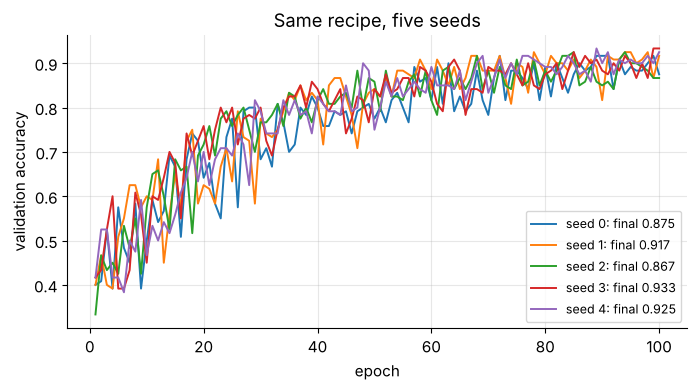

final validation accuracy over 5 seeds: mean 0.903, std 0.030, range 0.867 to 0.933


In [54]:
seed_runs = {}
for seed in range(5):
    net = make_mlp((HIDDEN_DIMS,), seed=seed)
    seed_runs[seed] = train_fast(net, X_train_t, y_train_t, X_val_t, y_val_t, epochs=EPOCHS, lr=LR, seed=seed)
final_val = np.array([h["val_acc"][-1] for h in seed_runs.values()])

fig, ax = plt.subplots(figsize=(8, 3.8))
for seed, h in seed_runs.items():
    ax.plot(np.arange(1, EPOCHS + 1), h["val_acc"], lw=1.4, label=f"seed {seed}: final {h['val_acc'][-1]:.3f}")
ax.set(xlabel="epoch", ylabel="validation accuracy", title="Same recipe, five seeds")
ax.legend(fontsize=9, loc="lower right")
plt.show()
print(f"final validation accuracy over 5 seeds: mean {final_val.mean():.3f}, std {final_val.std(ddof=1):.3f}, "
      f"range {final_val.min():.3f} to {final_val.max():.3f}")

The spread between seeds is several percentage points, as large as many of the "improvements" people report from changing a setting. Two rules for every experiment that follows:

1. **Repeat each configuration with several seeds** and report the mean and the spread (Section 11 uses three seeds per setting, and more would be better, but we have a CPU budget).
2. **Treat differences smaller than the seed-to-seed spread as noise.**

> **Common pitfall.** Tuning a setting on a single seed and keeping whichever value "won" is a way of fitting the noise. The same is true for picking the luckiest seed: a seed is not a hyperparameter.

### 10.4 `model.train()`, `model.eval()`, `torch.no_grad()` and `torch.inference_mode()`

These four look similar but do completely different jobs, and evaluation code normally needs **two** of them.

| call | what it changes | what it does **not** change |
|---|---|---|
| `model.train()` | sets the flag `module.training = True` in every submodule: dropout drops units, batch norm uses batch statistics | gradient tracking |
| `model.eval()` | sets `training = False`: dropout passes everything through, batch norm uses its stored averages | gradient tracking (it does **not** turn autograd off) |
| `with torch.no_grad():` | autograd stops recording: no graph, less memory, faster, and results have `requires_grad=False` | dropout and batch-norm behavior |
| `with torch.inference_mode():` | like `no_grad`, slightly faster, but its outputs can never be used in autograd later | dropout and batch-norm behavior |

A dropout layer makes the difference visible. In training mode it zeroes each hidden value with probability $p$ and multiplies the survivors by $1/(1-p)$, so the same input gives a different output on every call. In evaluation mode it does nothing:

In [55]:
net_drop = make_mlp((64,), dropout=0.5, seed=SEED)
x_one = X_val_t[:1].to(DEVICE)

net_drop.train()
outs_train = [net_drop(x_one).detach().cpu().numpy().round(3) for _ in range(3)]
net_drop.eval()
outs_eval = [net_drop(x_one).detach().cpu().numpy().round(3) for _ in range(3)]
print("train mode, three calls on the same point:", *outs_train, sep="\n   ")
print("eval mode, three calls on the same point: ", *outs_eval, sep="\n   ")

out_tracked = net_drop(x_one)
with torch.no_grad():
    out_plain = net_drop(x_one)
print(f"eval mode without no_grad: requires_grad={out_tracked.requires_grad}, grad_fn={type(out_tracked.grad_fn).__name__}")
print(f"eval mode with no_grad   : requires_grad={out_plain.requires_grad}, grad_fn={out_plain.grad_fn}")

train mode, three calls on the same point:
   [[-1.327  0.331  0.004]]
   [[-0.782  0.584  0.384]]
   [[-0.984 -0.14  -0.521]]
eval mode, three calls on the same point: 
   [[-0.813  0.071 -0.093]]
   [[-0.813  0.071 -0.093]]
   [[-0.813  0.071 -0.093]]
eval mode without no_grad: requires_grad=True, grad_fn=AddmmBackward0
eval mode with no_grad   : requires_grad=False, grad_fn=None


So `model.eval()` alone still builds a computation graph for every evaluation batch (wasting memory), and `torch.no_grad()` alone would still apply dropout during evaluation (giving noisy, pessimistic validation scores). Our `evaluate` function uses both, and `train_one_epoch` calls `model.train()` at its start because `evaluate` left the model in evaluation mode. Forgetting that last call is a classic silent bug: after the first validation pass, dropout would be switched off for the rest of training.

### 10.5 `torch.unique`: counting classes and re-encoding labels

We set the output size with `torch.unique(y_train_t).shape[0]`. The function returns the **sorted distinct values** of a tensor, and optionally how often each occurs (`return_counts=True`) and, for every element, the position of its value in the sorted list (`return_inverse=True`).

In [56]:
values, counts = torch.unique(y_train_t, return_counts=True)
print("distinct training labels:", values.tolist(), "| counts:", counts.tolist())

raw_labels = torch.tensor([5, 9, 0, 9, 5, 5])                 # labels that are NOT 0, 1, 2
classes, codes = torch.unique(raw_labels, return_inverse=True)
print("raw labels:", raw_labels.tolist(), "-> classes:", classes.tolist(), "-> codes:", codes.tolist())
print("decode back:", classes[codes].tolist())

three_logits = torch.zeros(len(raw_labels), 3)                  # a 3-class model's output for these 6 points
for name, targets in [("raw labels {0, 5, 9}", raw_labels), ("re-encoded codes {0, 1, 2}", codes)]:
    try:
        print(f"{name:27s} -> loss {F.cross_entropy(three_logits, targets).item():.4f}")
    except (IndexError, RuntimeError) as err:
        print(f"{name:27s} -> {type(err).__name__}: {str(err).splitlines()[0][:60]}")

distinct training labels: [0, 1, 2] | counts: [140, 140, 140]
raw labels: [5, 9, 0, 9, 5, 5] -> classes: [0, 5, 9] -> codes: [1, 2, 0, 2, 1, 1]
decode back: [5, 9, 0, 9, 5, 5]
raw labels {0, 5, 9}        -> IndexError: Target 5 is out of bounds.
re-encoded codes {0, 1, 2}  -> loss 1.0986


Two pitfalls hide behind the convenient `torch.unique(y_train).shape[0]`:

- **Labels must already be $0, \dots, C-1$.** With labels $\{0, 5, 9\}$ there are 3 distinct values, but 5 and 9 are not valid indices into 3 logits, so the loss fails. Re-encode first, as the `codes` from `return_inverse=True` are exactly the labels a model needs, and `classes[codes]` maps predictions back to the original names.
- **A class can be missing from a subset.** With a rare class or a tiny training split, the training labels may not contain every class, and the model gets too few outputs. Take our classes $\{0, 1, 2\}$: if one of them is missing from the training split, `torch.unique` counts 2, so the model has 2 logits and only the targets 0 and 1 are valid. If the missing class is the *largest* label (2), training runs without complaint, but the model can never predict class 2, and the first validation or test example of class 2 makes the loss fail (on a CPU: `IndexError: Target 2 is out of bounds`). If class 0 or 1 is missing instead, label 2 is still in the training data and is itself out of range, so training crashes on the first batch that contains it (Quiz Q10 is this case with four classes). The robust choice is to define the class list once, from the problem specification or the full label set, and use it everywhere.

Our stratified split guarantees all three arms appear in every subset, so here the shortcut is safe.

### ✏️ Exercise 10: a label encoder with `torch.unique`

Write `fit_label_encoder(labels)` that returns the sorted tensor of classes, and `encode(labels, classes)` that maps each label to its index in `classes`, raising a `ValueError` if some label is not in `classes` (this is how you catch labels never seen in training). Hint: `torch.searchsorted(classes, labels)` finds where each label would be inserted in the sorted `classes`, and check that the class at that position really equals the label.

In [57]:
# ✏️ Exercise 10: label encoding
def fit_label_encoder(labels):
    """Sorted 1-d tensor of the distinct values in labels."""
    # YOUR CODE HERE
    raise NotImplementedError


def encode(labels, classes):
    """Index of each label in classes (a long tensor), raising ValueError if a label is unknown."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex10():
    classes = fit_label_encoder(torch.tensor([30, 10, 20, 10, 30]))
    assert classes.tolist() == [10, 20, 30], f"classes should be sorted and distinct, got {classes.tolist()}"
    codes = encode(torch.tensor([20, 30, 10, 10]), classes)
    assert codes.dtype == torch.long and codes.tolist() == [1, 2, 0, 0], f"got {codes}"
    assert torch.equal(classes[codes], torch.tensor([20, 30, 10, 10])), "classes[codes] must recover the labels"
    for unknown in (torch.tensor([10, 25]), torch.tensor([40]), torch.tensor([5])):
        try:
            encode(unknown, classes)
        except ValueError:
            pass
        else:
            raise AssertionError(f"encode should raise ValueError for the unknown label(s) in {unknown.tolist()}")


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def fit_label_encoder(labels):
    return torch.unique(labels)                                # sorted by default

def encode(labels, classes):
    idx = torch.searchsorted(classes, labels)                  # insertion positions, in 0..len(classes)
    idx_clipped = idx.clamp(max=len(classes) - 1)              # a label above every class gives len(classes)
    if not torch.equal(classes[idx_clipped], labels):
        raise ValueError("labels contain values not seen when fitting the encoder")
    return idx_clipped.long()
```
`searchsorted` does a binary search for each label, so encoding $n$ labels into $C$ classes costs $O(n \log C)$. The clamp is needed because a label larger than every class gets the position `len(classes)`, which is not a valid index, and after clamping, the equality check flags it as unknown.
</details>

## 11. Controlled experiments: learning rate, batch size, optimizer, width, depth, activation

Now we can ask *why* the reference recipe lands where it does, by changing **one setting at a time** and keeping everything else fixed. The protocol for every experiment:

- three seeds per configuration (seeds 0, 1, 2 for both initialization and batch order), reporting the mean and standard deviation.
- all decisions based on **validation** accuracy (the test set stays locked away).
- the reference recipe (SGD, learning rate 0.1, batch 32, 100 epochs, width 128, ReLU) unless stated otherwise.

The first three experiments are about **optimization** (how fast and how well training finds good weights), and the last three are about **capacity** (which functions the network can represent at all).

In [58]:
SEEDS = (0, 1, 2)


_run_cache = {}                     # configurations shared by several experiments are trained only once


def run_config(hidden=(HIDDEN_DIMS,), activation="relu", dropout=0.0, seeds=SEEDS, epochs=EPOCHS, **train_kw):
    """Train one configuration once per seed. Returns a list of (model, history) pairs."""
    settings = {"lr": LR, "batch_size": BATCH_SIZE, "optimizer": "sgd", "momentum": 0.0, "weight_decay": 0.0}
    settings.update(train_kw)
    key = (tuple(hidden), activation, dropout, tuple(seeds), epochs, tuple(sorted(settings.items())))
    if key not in _run_cache:
        runs = []
        for seed in seeds:
            net = make_mlp(hidden, activation, dropout, seed=seed)
            hist = train_fast(net, X_train_t, y_train_t, X_val_t, y_val_t, epochs=epochs, seed=seed, **settings)
            runs.append((net, hist))
        _run_cache[key] = runs
    return _run_cache[key]


def summarize(runs):
    """Mean final metrics over seeds (and the spread of validation accuracy)."""
    final = lambda key: np.array([h[key][-1] for _, h in runs])
    return {"train acc": final("train_acc").mean(), "val acc": final("val_acc").mean(),
            "val acc std": final("val_acc").std(ddof=1), "train loss": final("train_loss").mean()}


def plot_region_grid(models_and_titles, ncols, figsize):
    """Small multiples: decision regions of several models, with the training points."""
    nrows = math.ceil(len(models_and_titles) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    for ax, (net, title) in zip(axes.flat, models_and_titles):
        plot_regions(ax, lambda P, net=net: predict_proba(net, P, scaler), X_train, y_train, title=title, s=4, steps=150)
    for ax in axes.flat[len(models_and_titles):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### 11.1 Learning rate

The learning rate $\eta$ sets the step size in $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\nabla\mathcal{L}$. If it is too small, training crawls, and if it is too large, each step overshoots the valley it is trying to descend, so the loss oscillates or explodes. We sweep $\eta$ over a factor of 300, on a logarithmic grid, because what matters is the order of magnitude.

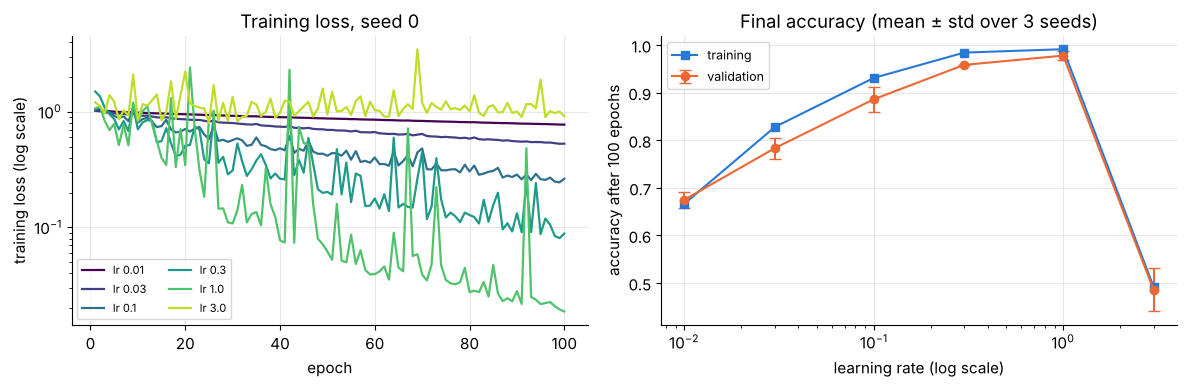

,train acc,val acc,val acc std,train loss
learning rate,,,,
0.01,0.667,0.675,0.017,0.768
0.03,0.828,0.783,0.022,0.520
0.10,0.931,0.886,0.027,0.259
0.30,0.984,0.958,0.000,0.087
1.00,0.991,0.978,0.010,0.048
3.00,0.492,0.486,0.046,1.174


In [59]:
lr_grid = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
lr_runs = {lr: run_config(lr=lr) for lr in lr_grid}
lr_table = pd.DataFrame({lr: summarize(runs) for lr, runs in lr_runs.items()}).T
lr_table.index.name = "learning rate"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(lr_grid)))
for color, (lr, runs) in zip(colors, lr_runs.items()):
    axes[0].plot(np.arange(1, EPOCHS + 1), runs[0][1]["train_loss"], color=color, lw=1.6, label=f"lr {lr}")
axes[0].set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="Training loss, seed 0")
axes[0].legend(fontsize=8, ncol=2)
axes[1].errorbar(lr_grid, lr_table["val acc"], yerr=lr_table["val acc std"], marker="o", capsize=4,
                 color=VAL_COLOR, label="validation")
axes[1].plot(lr_grid, lr_table["train acc"], marker="s", color=TRAIN_COLOR, label="training")
axes[1].set(xscale="log", xlabel="learning rate (log scale)", ylabel="accuracy after 100 epochs",
            title="Final accuracy (mean ± std over 3 seeds)")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
display(lr_table.round(3))

The sweep tells a textbook story:

- **Too small** ($\eta = 0.01$): the loss creeps down in a nearly straight line and the model reaches only 0.675 validation accuracy in 100 epochs. Nothing is wrong except speed.
- **Better and better**: every increase up to $\eta = 1.0$ helps: 0.3 gives 0.958 and 1.0 gives 0.978. The loss curves of the larger learning rates are jagged (each step is big enough to overshoot a little), but the trend is strongly downward.
- **Too large** ($\eta = 3.0$): training breaks down. The loss jumps around near or above $\ln 3 \approx 1.10$, the value of a uniform guess, and accuracy collapses to 0.486.

So the reference value $\eta = 0.1$ was simply too timid for a budget of 100 epochs, which is the "under-training" we diagnosed in Section 7.5. Notice also that the best learning rate sits just below the point where training becomes unstable, a very common pattern.

> **Olympiad tip.** Search learning rates on a **logarithmic** grid (for example $10^{-3}, 3 \cdot 10^{-3}, 10^{-2}, \dots$), never on a linear one: the useful range spans orders of magnitude. Start coarse, then refine around the best value, and remember that the best learning rate depends on the batch size, the optimizer and the number of epochs.

### 11.2 Batch size

The batch size $B$ trades two things against each other:

- **Number of updates.** One epoch over $n = 420$ points makes $\lceil n/B \rceil$ updates: 53 with $B = 8$, 14 with $B = 32$, 4 with $B = 128$, and a single one with full-batch gradient descent ($B = 420$).
- **Gradient noise.** A batch gradient is an estimate of the full-data gradient. Its variance shrinks roughly like $1/B$: small batches give noisy steps, large batches give accurate ones.

With a fixed number of epochs and a fixed learning rate, small batches therefore take many noisy steps and large batches take few precise ones. A common heuristic, the **linear scaling rule**, says that when you multiply $B$ by $k$ you can multiply $\eta$ by about $k$ as well, so each epoch moves the weights about as far. We test both the fixed learning rate and the scaled one.

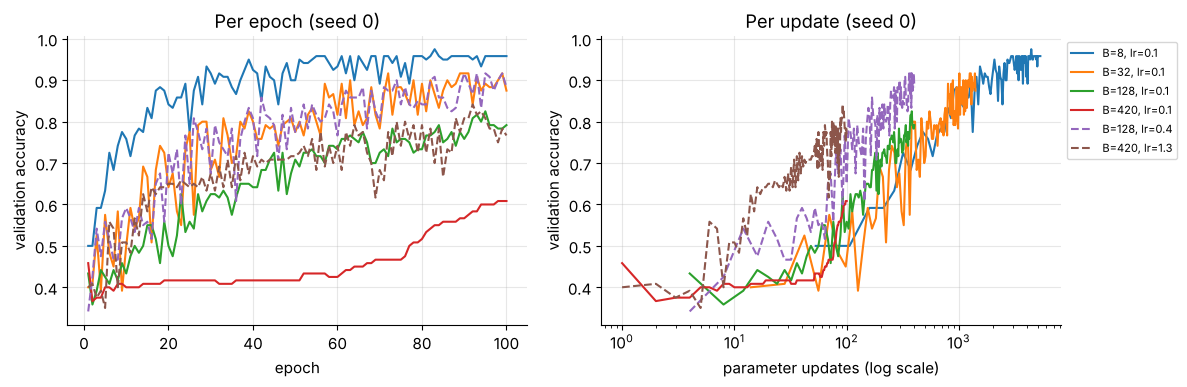

,train acc,val acc,val acc std,train loss,updates
"B=8, lr=0.1",0.990,0.958,0.000,0.063,5300.0
"B=32, lr=0.1",0.931,0.886,0.027,0.259,1400.0
"B=128, lr=0.1",0.844,0.797,0.025,0.529,400.0
"B=420, lr=0.1",0.564,0.614,0.010,0.824,100.0
"B=128, lr=0.4",0.941,0.917,0.030,0.233,400.0
"B=420, lr=1.3",0.809,0.783,0.022,0.432,100.0


In [60]:
bs_configs = [(8, 0.1), (32, 0.1), (128, 0.1), (420, 0.1), (128, 0.4), (420, 1.3)]
bs_runs = {(bs, lr): run_config(batch_size=bs, lr=lr) for bs, lr in bs_configs}
bs_table = pd.DataFrame({f"B={bs}, lr={lr}": {**summarize(runs), "updates": EPOCHS * math.ceil(420 / bs)}
                         for (bs, lr), runs in bs_runs.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (bs, lr), runs in bs_runs.items():
    hist = runs[0][1]
    style = "-" if lr == 0.1 else "--"
    steps = np.arange(1, EPOCHS + 1) * math.ceil(420 / bs)
    axes[0].plot(np.arange(1, EPOCHS + 1), hist["val_acc"], ls=style, lw=1.5, label=f"B={bs}, lr={lr}")
    axes[1].plot(steps, hist["val_acc"], ls=style, lw=1.5, label=f"B={bs}, lr={lr}")
axes[0].set(xlabel="epoch", ylabel="validation accuracy", title="Per epoch (seed 0)")
axes[1].set(xscale="log", xlabel="parameter updates (log scale)", ylabel="validation accuracy",
            title="Per update (seed 0)")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()
display(bs_table.round(3))

**Per epoch** (left), smaller batches win clearly: with $\eta = 0.1$, batch size 8 reaches 0.958 validation accuracy, while full-batch gradient descent ($B = 420$) is still at 0.614 after 100 epochs, because it has made only 100 updates against 5,300. **Per update** (right), the picture flips: each large-batch step is more accurate, and with the linearly scaled learning rate the large batches make the most progress per step. Scaling the learning rate recovers much of the gap ($B = 128$: 0.797 → 0.917 with $\eta = 0.4$, and $B = 420$: 0.614 → 0.783 with $\eta = 1.3$), but not all of it: a hundred steps are just too few, however good each one is, and the rule breaks down when $\eta$ gets close to the unstable range of Section 11.1.

In practice the batch size is often set by the hardware (as large as fits comfortably in memory, because one big matrix product is much faster than many small ones), and then the learning rate and number of epochs are tuned to match. Small batches also add gradient noise, which acts as a mild regularizer, and on this small problem that effect is minor compared with the number of updates.

### 11.3 Optimizers: SGD, momentum and Adam

Plain SGD uses the current batch gradient $\mathbf{g}_t$ only. Two famous improvements:

**Momentum** keeps a running "velocity" that accumulates past gradients, like a ball rolling downhill that does not stop at every bump:

$$
\mathbf{v}_t = \mu\,\mathbf{v}_{t-1} + \mathbf{g}_t, \qquad \boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\mathbf{v}_t, \qquad \mu = 0.9 \text{ typically.}
$$

Directions in which gradients consistently agree build up speed (up to $1/(1-\mu) = 10\times$ for $\mu = 0.9$), while directions in which they flip sign cancel out. That is also why momentum usually needs a *smaller* $\eta$ than plain SGD.

**Adam** keeps running averages of the gradient and of its elementwise square, and divides one by the square root of the other, so every parameter gets its own step size (all operations elementwise):

$$
\mathbf{m}_t = \beta_1\mathbf{m}_{t-1} + (1-\beta_1)\mathbf{g}_t, \qquad
\mathbf{s}_t = \beta_2\mathbf{s}_{t-1} + (1-\beta_2)\mathbf{g}_t^2, \qquad
\boldsymbol\theta_t = \boldsymbol\theta_{t-1} - \eta\,\frac{\hat{\mathbf{m}}_t}{\sqrt{\hat{\mathbf{s}}_t} + \epsilon},
$$

with $\hat{\mathbf{m}}_t = \mathbf{m}_t / (1 - \beta_1^t)$ and $\hat{\mathbf{s}}_t = \mathbf{s}_t / (1 - \beta_2^t)$ correcting the bias of averages that start at zero, and defaults $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$. Because the step is normalized, its size is roughly $\eta$ in every coordinate, whatever the scale of the gradient. That makes Adam forgiving, and it is why Adam's typical learning rates ($10^{-3}$ to $10^{-2}$) look tiny next to SGD's.

We compare them over 100 epochs, and we also run the reference recipe **four times longer** (400 epochs) to answer the question left open in Section 7.5.

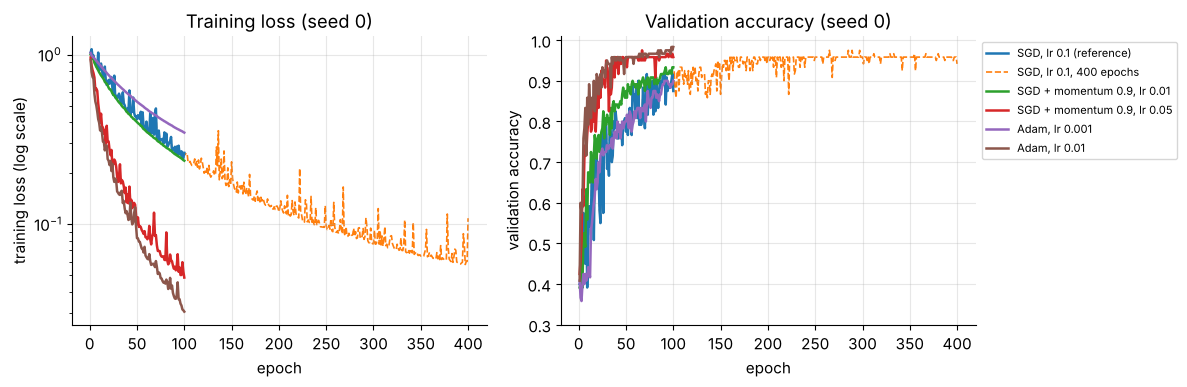

,train acc,val acc,val acc std,train loss
"SGD, lr 0.1 (reference)",0.9310,0.8861,0.0268,0.2586
"SGD, lr 0.1, 400 epochs",0.9849,0.9583,0.0144,0.0740
"SGD + momentum 0.9, lr 0.01",0.9476,0.9278,0.0048,0.2322
"SGD + momentum 0.9, lr 0.05",0.9913,0.9667,0.0083,0.0489
"Adam, lr 0.001",0.9024,0.9000,0.0000,0.3386
"Adam, lr 0.01",0.9929,0.9806,0.0048,0.0295


In [61]:
opt_configs = {
    "SGD, lr 0.1 (reference)": dict(optimizer="sgd", lr=0.1),
    "SGD, lr 0.1, 400 epochs": dict(optimizer="sgd", lr=0.1, epochs=400),
    "SGD + momentum 0.9, lr 0.01": dict(optimizer="sgd", lr=0.01, momentum=0.9),
    "SGD + momentum 0.9, lr 0.05": dict(optimizer="sgd", lr=0.05, momentum=0.9),
    "Adam, lr 0.001": dict(optimizer="adam", lr=0.001),
    "Adam, lr 0.01": dict(optimizer="adam", lr=0.01),
}
opt_runs = {name: run_config(**cfg) for name, cfg in opt_configs.items()}
opt_table = pd.DataFrame({name: summarize(runs) for name, runs in opt_runs.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, runs in opt_runs.items():
    hist = runs[0][1]
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    long_run = "400" in name                                             # starts exactly on the reference curve
    kw = dict(ls="--", lw=1.2, zorder=1) if long_run else dict(ls="-", lw=1.8, zorder=2)
    axes[0].plot(ep, hist["train_loss"], label=name, **kw)
    axes[1].plot(ep, hist["val_acc"], label=name, **kw)
axes[0].set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="Training loss (seed 0)")
axes[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy (seed 0)", ylim=(0.3, 1.01))
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()
display(opt_table.round(4))

Four observations:

- **Training longer works.** The reference recipe run for 400 epochs (its first 100 epochs are exactly the reference curve, since the seed is the same) climbs from 0.886 to 0.958 validation accuracy. The model of Section 7 was under-trained, not too small.
- **Momentum is a multiplier.** With $\mu = 0.9$ and $\eta = 0.01$, the effective step $\eta/(1-\mu) = 0.1$ matches plain SGD with $\eta = 0.1$, and indeed the two training-loss curves nearly coincide (final training loss 0.232 vs 0.259), and momentum even ends ahead on validation (0.928 vs 0.886). With $\eta = 0.05$ (effective step 0.5) momentum reaches 0.967.
- **Adam with $\eta = 0.01$ is fastest here**: training loss 0.03 and validation accuracy 0.981 after 100 epochs, close to the 0.995 ceiling of Section 1.5. With $\eta = 0.001$ Adam is as slow as the reference SGD.
- **Every optimizer has its own good learning rate.** "Adam beats SGD" is not a law of nature: we tried only two learning rates per optimizer, and carefully tuned SGD with momentum is competitive on many problems. Adam's appeal is that its default range ($10^{-3}$ to $10^{-2}$) works well for many small networks without much tuning.

### 11.4 Width: how many hidden units are needed?

For the capacity experiments we want each network trained *close to convergence*, so that a poor result means "this architecture cannot do it" rather than "the optimizer has not finished yet". Section 11.3 showed that Adam with learning rate 0.01 gets much further in 100 epochs than our SGD recipe, so the next three experiments use it. Everything else stays fixed (batch 32, 100 epochs, three seeds).

Section 9 gives a prediction. A layer of $w$ ReLU units has $w$ fold lines, hence at most $1 + w(w+1)/2$ linear regions: 4 regions for $w = 2$, 11 for $w = 4$, 37 for $w = 8$, 137 for $w = 16$. A spiral boundary that winds once around the center needs quite a few straight pieces, so very narrow networks should fail no matter how well they are trained.

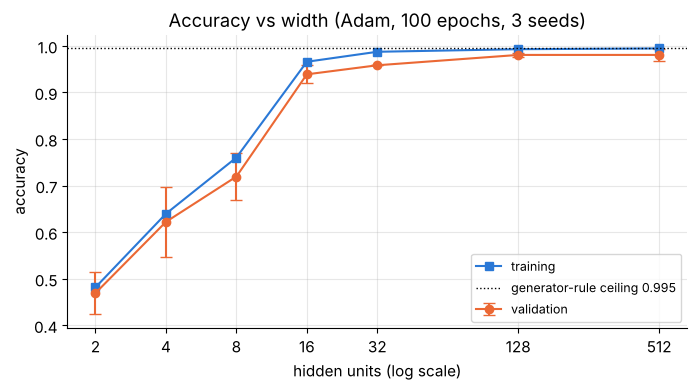

,train acc,val acc,val acc std,train loss,parameters
width,,,,,
2,0.482,0.469,0.046,0.920,15.0
4,0.640,0.622,0.075,0.738,27.0
8,0.760,0.719,0.051,0.555,51.0
16,0.966,0.939,0.019,0.156,99.0
32,0.987,0.958,0.000,0.079,195.0
128,0.993,0.981,0.005,0.029,771.0
512,0.994,0.981,0.013,0.023,3075.0


In [62]:
width_grid = [2, 4, 8, 16, 32, 128, 512]
width_runs = {w: run_config(hidden=(w,), optimizer="adam", lr=0.01) for w in width_grid}
width_table = pd.DataFrame({w: {**summarize(runs), "parameters": count_params} for w, runs in width_runs.items()
                            for count_params in [sum(p.numel() for p in runs[0][0].parameters())]}).T
width_table.index.name = "width"

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(width_grid, width_table["val acc"], yerr=width_table["val acc std"], marker="o", capsize=4,
            color=VAL_COLOR, label="validation")
ax.plot(width_grid, width_table["train acc"], marker="s", color=TRAIN_COLOR, label="training")
ax.axhline(ceiling, color="black", ls=":", lw=1, label=f"generator-rule ceiling {ceiling:.3f}")
ax.set_xscale("log", base=2)
ax.set_xticks(width_grid, [str(w) for w in width_grid])
ax.set(xlabel="hidden units (log scale)", ylabel="accuracy", title="Accuracy vs width (Adam, 100 epochs, 3 seeds)")
ax.legend(fontsize=9, loc="lower right")
plt.show()
display(width_table.round(3))

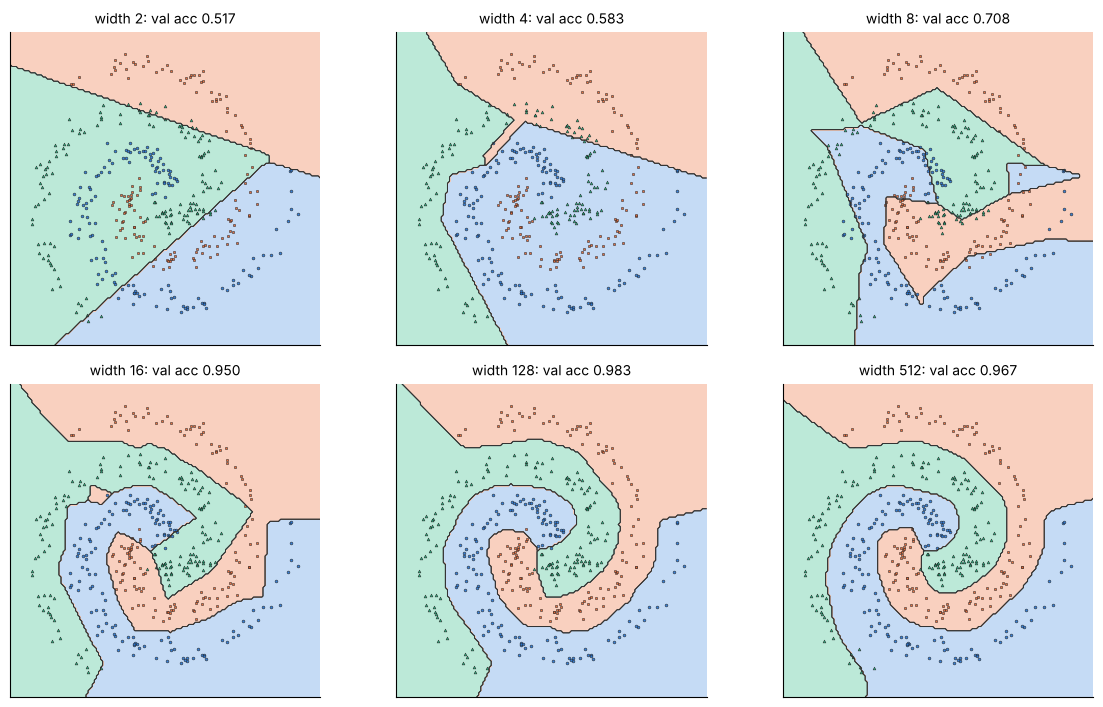

In [63]:
plot_region_grid([(width_runs[w][0][0], f"width {w}: val acc {width_runs[w][0][1]['val_acc'][-1]:.3f}")
                  for w in (2, 4, 8, 16, 128, 512)], ncols=3, figsize=(12, 7.2))

The prediction from Section 9 holds:

- **Width 2 and 4** (at most 4 and 11 linear regions) cannot draw a spiral at all: a few straight cuts, and training accuracy (0.48 and 0.64) as poor as validation accuracy. When a model fails even on its own training data it is **underfitting**: it lacks the capacity for the task, and no optimizer can fix that.
- **Width 8** (at most 37 regions) gets the rough layout with a polygon of a dozen edges, but no full winding (0.72).
- **Width 16**, only 99 parameters, already winds around the center (0.94), 32 units give 0.958, and **128 or 512** units reach 0.981, not far below the generator-rule ceiling of 0.995.
- **No overfitting at width 512.** It has 3,075 parameters for 420 training points, yet its validation accuracy matches the 128-unit network and its boundary is just as smooth. With data that are plentiful and clean relative to the difficulty of the task, extra width does no harm here. Overfitting needs few, noisy examples, the situation of Section 12.

So the reference width of 128 is more than enough, and 16 to 32 units would do the job, at least with a good optimizer.

<details>
<summary><b>Quick check</b>: at most how many linear regions can a hidden layer of 16 ReLU units create on 2-D inputs, and why does a network with that many regions still need training to classify the spiral?</summary>

At most $1 + 16 \cdot 17/2 = 137$ regions (Section 9.2). Having enough regions is necessary but not sufficient: the fold lines must sit in the right places, and the output layer must give each region the right affine scores. Training does both, and an untrained network has plenty of regions but classifies roughly at chance level (the reference MLP started at 0.36 training accuracy in Section 5.4).
</details>

### 11.5 Depth at an equal parameter budget

Is it better to spend parameters on one wide layer or on several narrow ones? A fair comparison fixes the **parameter count**. Using the counting rule of Exercise 5, three architectures with about 770 parameters each are 2 → 128 → 3 (771 parameters), 2 → 24 → 24 → 3 (747) and 2 → 18 → 18 → 18 → 3 (795).

Section 9.2 counted linear regions for one hidden layer. In a deeper ReLU network the activation pattern includes the on/off state of *every* hidden unit in *every* layer, and the network is still affine inside each region, so we can count regions the same way: evaluate all patterns on a grid and count the distinct ones.

,parameters,Adam val acc,Adam train loss,SGD (reference) val acc,"linear regions (Adam, seed 0)"
1 layer: 128,771.0,0.9806,0.0295,0.8861,3880.0
"2 layers: 24, 24",747.0,0.9806,0.0102,0.9333,988.0
"3 layers: 18, 18, 18",795.0,0.9917,0.0037,0.9722,955.0


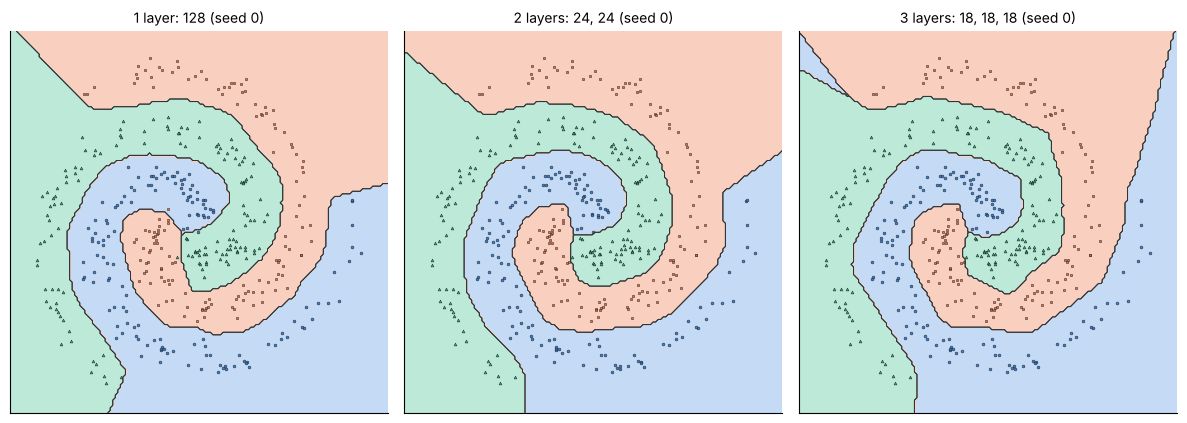

In [64]:
def count_linear_regions(net, points_std):
    """Distinct joint on/off patterns of all ReLU layers of an nn.Sequential, over the given points."""
    h = torch.as_tensor(points_std, dtype=torch.float32, device=DEVICE)
    patterns = []
    with torch.no_grad():
        for layer in net:
            h = layer(h)
            if isinstance(layer, nn.ReLU):
                patterns.append(h > 0)
    return torch.unique(torch.cat(patterns, dim=1), dim=0).shape[0]


depth_configs = {"1 layer: 128": (128,), "2 layers: 24, 24": (24, 24), "3 layers: 18, 18, 18": (18, 18, 18)}
depth_runs = {name: run_config(hidden=hid, optimizer="adam", lr=0.01) for name, hid in depth_configs.items()}
depth_sgd_runs = {name: run_config(hidden=hid, optimizer="sgd", lr=0.1) for name, hid in depth_configs.items()}
depth_table = pd.DataFrame({
    name: {"parameters": sum(p.numel() for p in depth_runs[name][0][0].parameters()),
           "Adam val acc": summarize(depth_runs[name])["val acc"],
           "Adam train loss": summarize(depth_runs[name])["train loss"],
           "SGD (reference) val acc": summarize(depth_sgd_runs[name])["val acc"],
           "linear regions (Adam, seed 0)": count_linear_regions(depth_runs[name][0][0], grid_r_std)}
    for name in depth_configs}).T
display(depth_table.round(4))
plot_region_grid([(depth_runs[name][0][0], f"{name} (seed 0)") for name in depth_configs], ncols=3, figsize=(12, 4.2))

At (almost) the same parameter count:

- **With Adam** all three networks classify well (validation 0.981, 0.981 and 0.992), and the deeper ones fit the training data more tightly (training loss 0.030, 0.010, 0.004).
- **With the reference SGD recipe** depth helps much more: 0.886 for one layer, 0.933 for two, 0.972 for three. With the same optimizer and budget, the deeper networks find a good solution far faster.
- **Region counts** hold a surprise: the deeper networks use *fewer* linear regions inside the window (about 1,000 against 3,880), yet fit better. A raw count of regions is not the whole story. A deep network composes its folds (the second layer folds the already folded space), so it can place a modest number of bends in a coordinated way, while a single layer can only add independent straight cuts, most of which do little for the boundary.

Be careful not to over-generalize from a 2-D toy problem: with a good optimizer (Adam) the accuracy differences here are a point or so, and the large gaps appear only with the slow SGD recipe. Depth pays off most on high-dimensional data with hierarchical structure (images, sound, text), and it brings its own training difficulties, which tools such as careful initialization, normalization layers and residual connections address.

### 11.6 Activation functions

The activation function decides the shape of each hidden unit's response. Four common choices:

| name | $\phi(a)$ | $\phi'(a)$ | range | notes |
|---|---|---|---|---|
| ReLU | $\max(0, a)$ | $0$ or $1$ | $[0, \infty)$ | piecewise linear, and units can "die" if always off |
| LeakyReLU | $\max(\alpha a, a)$, $\alpha = 0.1$ here | $\alpha$ or $1$ | $\mathbb{R}$ | never exactly zero gradient |
| tanh | $\dfrac{e^a - e^{-a}}{e^a + e^{-a}}$ | $1 - \tanh^2 a \le 1$ | $(-1, 1)$ | smooth, zero-centered, saturates for large $\lvert a\rvert$ |
| sigmoid | $\dfrac{1}{1 + e^{-a}}$ | $\sigma(a)(1 - \sigma(a)) \le 0.25$ | $(0, 1)$ | smooth, not zero-centered, saturates |

The derivative column matters for training: backpropagation multiplies by $\phi'(a)$ at every hidden unit, and the sigmoid's derivative is never larger than $0.25$.

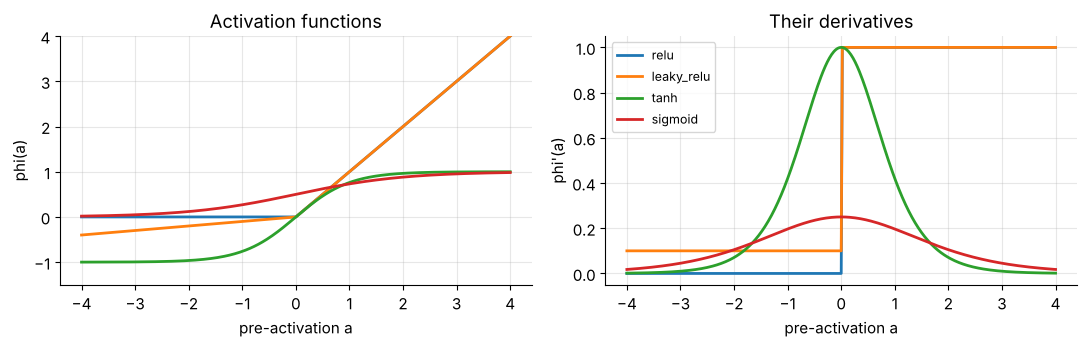

In [65]:
a_axis = np.linspace(-4, 4, 401)
a_t = torch.tensor(a_axis, dtype=torch.float32, requires_grad=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, make_act in ACTIVATIONS.items():
    out = make_act()(a_t)
    (grad,) = torch.autograd.grad(out.sum(), a_t)              # elementwise derivative phi'(a)
    axes[0].plot(a_axis, out.detach().numpy(), lw=2, label=name)
    axes[1].plot(a_axis, grad.numpy(), lw=2, label=name)
axes[0].set(xlabel="pre-activation a", ylabel="phi(a)", title="Activation functions", ylim=(-1.5, 4))
axes[1].set(xlabel="pre-activation a", ylabel="phi'(a)", title="Their derivatives")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

,Adam val acc,Adam train loss,SGD val acc,SGD train loss
relu,0.9806,0.0295,0.8861,0.2586
leaky_relu,0.9694,0.0439,0.8639,0.3088
tanh,0.9639,0.0900,0.8056,0.3846
sigmoid,0.8889,0.3703,0.4361,1.4136


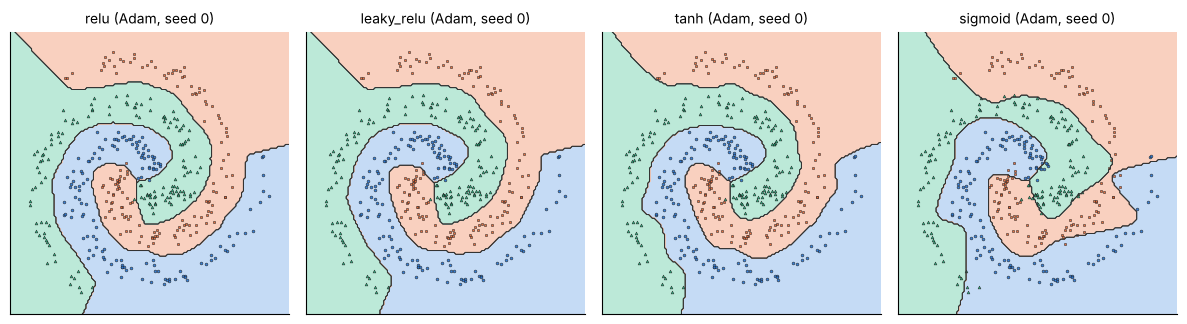

In [66]:
act_runs = {act: run_config(activation=act, optimizer="adam", lr=0.01) for act in ACTIVATIONS}
act_sgd_runs = {act: run_config(activation=act, optimizer="sgd", lr=0.1) for act in ACTIVATIONS}
act_table = pd.DataFrame({act: {"Adam val acc": summarize(act_runs[act])["val acc"],
                                "Adam train loss": summarize(act_runs[act])["train loss"],
                                "SGD val acc": summarize(act_sgd_runs[act])["val acc"],
                                "SGD train loss": summarize(act_sgd_runs[act])["train loss"]}
                          for act in ACTIVATIONS}).T
display(act_table.round(4))
plot_region_grid([(act_runs[act][0][0], f"{act} (Adam, seed 0)") for act in ACTIVATIONS], ncols=4, figsize=(12, 3.6))

- **With Adam**, ReLU, LeakyReLU and tanh all learn the spiral (validation 0.981, 0.969 and 0.964), while sigmoid lags behind (0.889, with a training loss still at 0.37). The boundaries differ in character: networks of ReLU-type units are piecewise linear, so their boundaries are polygons with corners, while tanh and sigmoid networks are smooth functions, so their boundaries are smooth curves.
- **With plain SGD** the differences grow: ReLU 0.886, LeakyReLU 0.864, tanh 0.806, and sigmoid fails completely (0.436, with a final training loss of 1.41, worse than the uniform guess $\ln 3 \approx 1.10$). Two reasons. First, $\sigma'(a) \le 0.25$, so every gradient flowing back through a sigmoid unit shrinks at least four-fold. Second, sigmoid outputs are always positive and hover around 0.5, so all 128 hidden features share a large common component. For the output layer these are badly scaled, uncentered inputs, the same problem standardization solved for the raw data in Section 9.3, and plain SGD zig-zags instead of descending. Adam rescales every parameter's step individually, which largely compensates.

Practical rule: use ReLU or one of its relatives (LeakyReLU, GELU, ...) in hidden layers, and keep the sigmoid for outputs that must lie in $(0, 1)$, such as a binary-classification probability.

### What the experiments taught us

| experiment | result on this task | general lesson |
|---|---|---|
| learning rate | SGD works best near $\eta = 1$ (0.978), and $\eta = 3$ breaks training | search on a log grid, as the best value is often just below instability |
| batch size | large batches make few updates per epoch, and scaling $\eta$ recovers part of the gap | count updates, not only epochs, and scale $\eta$ with $B$ |
| optimizer | Adam (0.01) is fastest, and 4x longer SGD also gets close | each optimizer has its own good learning-rate range |
| width | underfits below 16 units, saturates by 128 | capacity must match the complexity of the boundary |
| depth at equal size | slightly better with Adam, much better with SGD | depth composes folds instead of adding independent cuts |
| activation | ReLU best here, and sigmoid fails with plain SGD | default to ReLU-type units in hidden layers |

## 12. Generalization: overfitting, regularization and calibration

Until now the training set was generous for the difficulty of the task, and the reference model was, if anything, under-trained. Real projects often face the opposite situation: few, noisy examples and a network with far more parameters than data points. Let us create that situation on purpose. Because we own the generator, we can measure each model's **true** generalization on thousands of fresh points instead of guessing it from a small validation set, and we can compare with the generator rule of Section 1.5.

### 12.1 A harder problem: small, noisy data and a big network

| ingredient | setting |
|---|---|
| noise | angular noise $\sigma_\theta = 0.4$ (twice as thick arms), $\sigma_{xy} = 0.07$ |
| training set | 50 points per arm (150 in total) |
| validation set | 100 points per arm, used for early stopping and for fitting the temperature in 12.7 |
| fresh set | 2,000 points per arm, used **only** to measure generalization (it plays the role of "the future") |
| network | 2 → 128 → 128 → 3, ReLU: 17,283 parameters, more than 100 per training point |
| training | Adam, learning rate 0.003, full batch (all 150 points per step), 600 epochs, seed 0 |

In [67]:
NOISY = dict(angle_noise=0.4, xy_noise=0.07)
X_small, y_small = make_spiral_arms(n_per_class=50, seed=1, **NOISY)
X_sval, y_sval = make_spiral_arms(n_per_class=100, seed=2, **NOISY)
X_new, y_new = make_spiral_arms(n_per_class=2000, seed=3, **NOISY)       # the "future"
X_more, y_more = make_spiral_arms(n_per_class=500, seed=4, **NOISY)      # 10x more training data (12.5)

scaler_small = StandardScaler().fit(X_small)
to_tensor = lambda A: torch.tensor(scaler_small.transform(A), dtype=torch.float32)
Xs_t, Xsv_t, Xnew_t, Xmore_t = (to_tensor(A) for A in (X_small, X_sval, X_new, X_more))
ys_t, ysv_t, ynew_t, ymore_t = (torch.tensor(a, dtype=torch.long) for a in (y_small, y_sval, y_new, y_more))
noisy_ceiling = (generator_rule(X_new) == y_new).mean()
print(f"training {len(ys_t)} | validation {len(ysv_t)} | fresh {len(ynew_t)} points")
print(f"generator-rule accuracy on the fresh points (near-optimal reference): {noisy_ceiling:.4f}")

BIG = (128, 128)
SMALL_EPOCHS = 600


def train_small(hidden=BIG, dropout=0.0, X_tr=Xs_t, y_tr=ys_t, epochs=SMALL_EPOCHS, **kw):
    """Adam (lr 0.003), full batch, seed 0, on the noisy problem. Returns (model, history)."""
    net = make_mlp(hidden, dropout=dropout, seed=0)
    hist = train_fast(net, X_tr, y_tr, Xsv_t, ysv_t, epochs=epochs, seed=0, optimizer="adam", lr=0.003,
                      batch_size=len(y_tr), **kw)
    return net, hist


@torch.no_grad()
def scores(net, X_t, y_t):
    """(accuracy, mean cross-entropy) of a network on a labeled tensor dataset."""
    net.eval()
    logits = net(X_t.to(DEVICE)).cpu()
    return compute_accuracy(logits, y_t), F.cross_entropy(logits, y_t).item()


fresh_scores = lambda net: scores(net, Xnew_t, ynew_t)                    # generalization to the "future"


net_over, hist_over = train_small()
print(f"parameters: {sum(p.numel() for p in net_over.parameters()):,}")
print("final: train acc {:.3f} | val acc {:.3f} | fresh acc {:.3f} | train loss {:.4f} | val loss {:.3f}".format(
    hist_over["train_acc"][-1], hist_over["val_acc"][-1], fresh_scores(net_over)[0],
    hist_over["train_loss"][-1], hist_over["val_loss"][-1]))

training 150 | validation 300 | fresh 6000 points
generator-rule accuracy on the fresh points (near-optimal reference): 0.8942


parameters: 17,283
final: train acc 1.000 | val acc 0.813 | fresh acc 0.842 | train loss 0.0084 | val loss 1.287


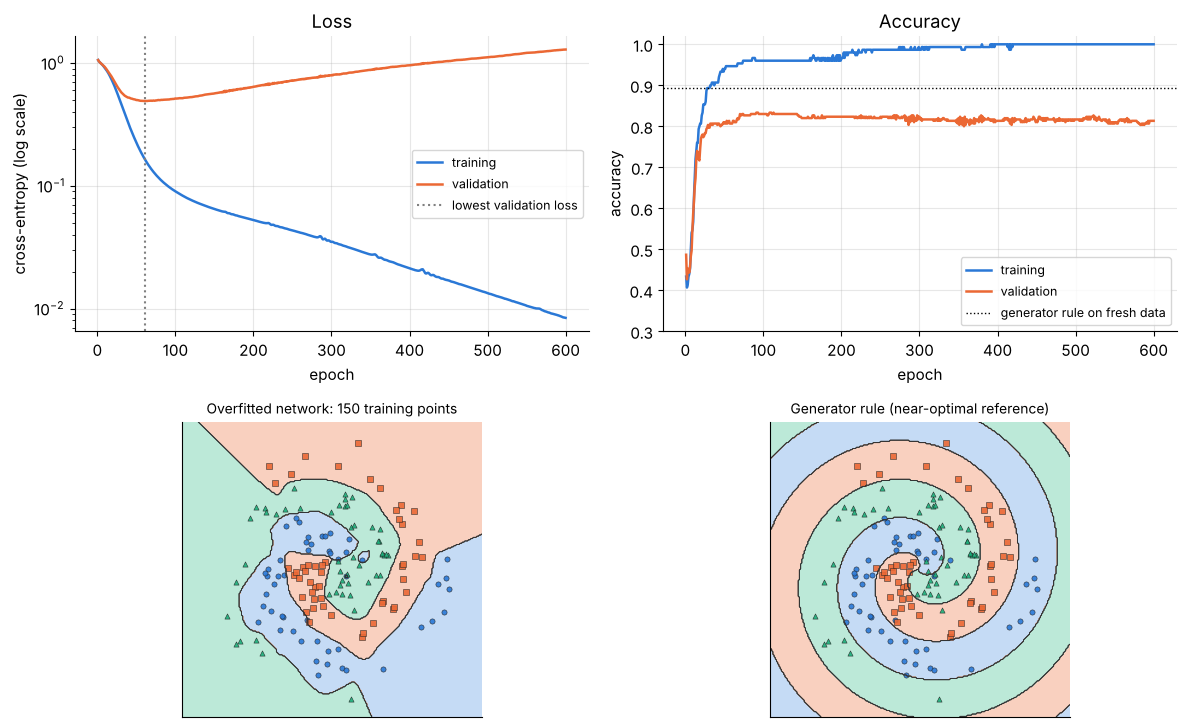

In [68]:
small_proba = lambda net: (lambda P: predict_proba(net, P, scaler_small))
rule_proba = lambda P: np.eye(3)[generator_rule(P)]                        # one-hot "probabilities" of the rule

fig = plt.figure(figsize=(12, 7.4))
ep_small = np.arange(1, SMALL_EPOCHS + 1)
ax1, ax2 = fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)
ax1.plot(ep_small, hist_over["train_loss"], color=TRAIN_COLOR, lw=1.8, label="training")
ax1.plot(ep_small, hist_over["val_loss"], color=VAL_COLOR, lw=1.8, label="validation")
ax1.axvline(int(np.argmin(hist_over["val_loss"])) + 1, color="gray", ls=":", label="lowest validation loss")
ax1.set(yscale="log", xlabel="epoch", ylabel="cross-entropy (log scale)", title="Loss")
ax1.legend(fontsize=9)
ax2.plot(ep_small, hist_over["train_acc"], color=TRAIN_COLOR, lw=1.8, label="training")
ax2.plot(ep_small, hist_over["val_acc"], color=VAL_COLOR, lw=1.8, label="validation")
ax2.axhline(noisy_ceiling, color="black", ls=":", lw=1, label="generator rule on fresh data")
ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy", ylim=(0.3, 1.02))
ax2.legend(fontsize=9, loc="lower right")
ax3, ax4 = fig.add_subplot(2, 2, 3), fig.add_subplot(2, 2, 4)
plot_regions(ax3, small_proba(net_over), X_small, y_small, X_ref=X_new, s=14,
             title="Overfitted network: 150 training points")
plot_regions(ax4, rule_proba, X_small, y_small, X_ref=X_new, s=14, title="Generator rule (near-optimal reference)")
plt.tight_layout()
plt.show()

This is overfitting in its purest form:

- The **training loss** falls steadily toward zero (0.0084 after 600 epochs) and the training accuracy reaches 100%. With more than 100 parameters per training point the network can memorize every point, including the noisy ones that sit inside another arm.
- The **validation loss** is lowest at epoch 61 and then climbs for the remaining 539 epochs, ending at 1.287.
- The **validation accuracy** levels off early, a little above 0.8, and stays there. Most decisions stop changing, and what keeps changing is the network's **confidence**. To push the training loss toward zero it inflates its logits, so its validation mistakes become ever more confident and ever more expensive in cross-entropy.
- On the 6,000 fresh points the model scores 0.842, against 0.894 for the generator rule, and its **generalization gap** (training minus fresh accuracy) is about 16 percentage points.
- The decision regions show the memorization: bulges and small islands around individual noisy training points, where the generator rule has smooth spiral bands.

The generator rule is near-optimal but not exactly optimal on this noisier data: it unwinds the angle as if there were no $\sigma_{xy}$ jitter, which is a poor approximation near the center, where the jitter dominates. Treat it as a strong reference rather than a hard ceiling, and a model trained on plenty of data can come close to it or even edge past it.

### 12.2 Early stopping

The validation curves suggest the simplest remedy: stop training when the validation loss stops improving, and keep the weights from the best epoch. In practice you cannot see the future, so you wait a fixed number of epochs, the **patience**, for a new best value before giving up. Our `train_fast(..., keep_best=True)` implements the "keep the best checkpoint" part: it saves a copy of the weights whenever the validation loss reaches a new minimum and restores that copy at the end.

In [69]:
net_es, hist_es = train_small(keep_best=True)
results = {}                                                                # comparison table for 12.6


def record(name, net):
    """Store train / validation / fresh scores of a model under a name."""
    (tr_acc, _), (va_acc, va_loss), (fr_acc, fr_loss) = (scores(net, Xs_t, ys_t), scores(net, Xsv_t, ysv_t),
                                                         fresh_scores(net))
    results[name] = {"train acc": tr_acc, "val acc": va_acc, "fresh acc": fr_acc, "fresh loss": fr_loss,
                     "gap (train - fresh)": tr_acc - fr_acc}
    return results[name]


record("no regularization (600 epochs)", net_over)
print(f"lowest validation loss at epoch {hist_es['best_epoch']} of {SMALL_EPOCHS}, and "
      f"best validation accuracy at epoch {int(np.argmax(hist_es['val_acc'])) + 1}")
print("early-stopped model:", {k: round(v, 4) for k, v in record("early stopping (val loss)", net_es).items()})

lowest validation loss at epoch 61 of 600; best validation accuracy at epoch 91
early-stopped model: {'train acc': 0.9467, 'val acc': 0.8133, 'fresh acc': 0.8432, 'fresh loss': 0.5008, 'gap (train - fresh)': 0.1035}


The restored weights from epoch 61 classify the fresh points about as well as the fully trained network (0.843 vs 0.842), but their fresh cross-entropy is much lower (0.501. Compare the unregularized model in the table of Section 12.6.). Early stopping did not make the boundary much better here, and it stopped the network from becoming **overconfident**. (Our `keep_best` option simply trains to the end and restores the best checkpoint, and a patience-based rule, as in Exercise 11, would also have saved most of the 600 epochs of computation.)

Notice the subtlety of the stopping criterion: the validation loss was lowest at epoch 61, the validation accuracy highest at epoch 91. Stopping on the loss favors trustworthy probabilities, stopping on accuracy favors the decisions themselves. Monitor the metric you actually care about, and remember that with 300 validation points one point is a third of a percentage point, so the epoch of "best accuracy" is itself noisy.

### ✏️ Exercise 11: early stopping with patience

Write `early_stopping_epoch(val_losses, patience)` that simulates early stopping on a list of validation losses (one per epoch, epochs numbered from 1). Training stops as soon as `patience` consecutive epochs have passed without a **strictly** lower loss than the best so far. Return `(best_epoch, stop_epoch)`. If stopping never triggers, `stop_epoch` is the last epoch.

In [70]:
# ✏️ Exercise 11: early stopping
def early_stopping_epoch(val_losses, patience):
    """Return (best_epoch, stop_epoch), both 1-based."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex11():
    losses = [1.0, 0.8, 0.85, 0.7, 0.72, 0.71, 0.73, 0.69]
    assert early_stopping_epoch(losses, patience=2) == (4, 6), f"patience 2: got {early_stopping_epoch(losses, 2)}"
    assert early_stopping_epoch(losses, patience=3) == (4, 7), f"patience 3: got {early_stopping_epoch(losses, 3)}"
    assert early_stopping_epoch(losses, patience=10) == (8, 8), "if it never triggers, stop at the last epoch"
    assert early_stopping_epoch([0.5, 0.5, 0.5], patience=2) == (1, 3), "equal losses are not improvements"
    best, _ = early_stopping_epoch(hist_over["val_loss"], patience=len(hist_over["val_loss"]))
    assert best == int(np.argmin(hist_over["val_loss"])) + 1, "with infinite patience, best = argmin + 1"


run_check("Exercise 11", _test_ex11)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def early_stopping_epoch(val_losses, patience):
    best_loss, best_epoch, waited = float("inf"), 0, 0
    for epoch, loss in enumerate(val_losses, start=1):
        if loss < best_loss:                         # strictly better: new checkpoint, reset the counter
            best_loss, best_epoch, waited = loss, epoch, 0
        else:
            waited += 1
            if waited >= patience:
                return best_epoch, epoch
    return best_epoch, len(val_losses)
```
With patience 2 on the example list, epoch 4 sets the best loss 0.7, and epochs 5 and 6 fail to beat it, so training stops at epoch 6 and the weights of epoch 4 are restored. Larger patience tolerates longer plateaus (useful with noisy validation curves) at the cost of extra epochs.
</details>

### 12.3 Weight decay (L2 regularization)

Weight decay adds a penalty on the size of the weights to the loss:

$$
\mathcal{L}_{\text{reg}}(\boldsymbol\theta) = \mathcal{L}_{\text{CE}}(\boldsymbol\theta) + \frac{\lambda}{2}\,\|\boldsymbol\theta\|^2
\quad\Longrightarrow\quad
\nabla\mathcal{L}_{\text{reg}} = \nabla\mathcal{L}_{\text{CE}} + \lambda\boldsymbol\theta .
$$

For plain SGD the update becomes $\boldsymbol\theta \leftarrow (1 - \eta\lambda)\,\boldsymbol\theta - \eta\nabla\mathcal{L}_{\text{CE}}$: before every step the weights shrink by the factor $1 - \eta\lambda$, hence the name "decay". Why does it help? A ReLU network's logits scale with its weights, so small weights mean gentler slopes, fewer sharp turns in the boundary, and smaller logits, i.e. less extreme probabilities. The network can still use large weights where the data demands it, but every unit of weight now has to "pay for itself" by reducing the cross-entropy.

In PyTorch, `weight_decay=λ` in the optimizer adds $\lambda\boldsymbol\theta$ to every parameter's gradient (biases included, unless you use parameter groups). We sweep $\lambda$ over two orders of magnitude.

In [71]:
wd_nets = {}
for wd in (1e-3, 1e-2, 1e-1):
    wd_nets[wd], _ = train_small(weight_decay=wd)
    record(f"weight decay {wd:g}", wd_nets[wd])
display(pd.DataFrame(results).T.round(4))

,train acc,val acc,fresh acc,fresh loss,gap (train - fresh)
no regularization (600 epochs),1.0000,0.8133,0.8418,1.1973,0.1582
early stopping (val loss),0.9467,0.8133,0.8432,0.5008,0.1035
weight decay 0.001,0.9933,0.8267,0.8517,0.4973,0.1417
weight decay 0.01,0.9667,0.8333,0.8518,0.4258,0.1148
weight decay 0.1,0.3333,0.3333,0.3333,1.0986,0.0000


The sweep shows both sides of the trade-off:

- $\lambda = 0.001$ and $\lambda = 0.01$ keep the training accuracy high (0.993 and 0.967) but cut the fresh cross-entropy from 1.197 to 0.497 and 0.426, and add about one percentage point of fresh accuracy (0.852 instead of 0.842).
- $\lambda = 0.1$ is far too strong. The penalty overwhelms the data term, all weights are pulled toward zero and the network collapses to a constant output: uniform probabilities (loss exactly $\ln 3 \approx 1.0986$) and accuracy $1/3$ on every set. That is **underfitting caused by regularization**.

Like the learning rate, $\lambda$ is a hyperparameter to tune on validation data, on a logarithmic grid.

<details>
<summary><b>Quick check</b>: why does the $\lambda = 0.1$ model score <i>exactly</i> 0.3333 on the training, validation and fresh sets, with loss 1.0986?</summary>

The penalty pulls every weight and bias to (almost) zero, so all three logits are (almost) equal for every input. The softmax is then uniform, $(1/3, 1/3, 1/3)$, and the loss is $-\ln(1/3) = \ln 3 \approx 1.0986$. The argmax of nearly equal logits picks the same class everywhere (whichever logit is a hair larger), so the accuracy equals that class's share of each set, and every one of our sets is perfectly balanced: exactly $1/3$.
</details>

> **Going deeper.** For Adam, `weight_decay` is added to the gradient *before* the adaptive rescaling, so parameters with large gradient history are decayed less. `torch.optim.AdamW` instead shrinks the weights directly ("decoupled" weight decay), which usually works better for large models and is the default choice in modern practice, and its good values of $\lambda$ are much larger (around $10^{-2}$ to $10^{-1}$ relative to a learning rate of $10^{-3}$).

### 12.4 Dropout

**Dropout** zeroes each hidden activation independently with probability $p$ at every training step, and scales the survivors by $1/(1-p)$ so that the expected activation is unchanged:

$$
\tilde{h}_j = \frac{m_j}{1 - p}\,h_j, \qquad m_j \sim \text{Bernoulli}(1 - p), \qquad \mathbb{E}[\tilde{h}_j] = h_j .
$$

Because any unit can disappear at any step, the network cannot rely on fragile combinations of specific units, and it is pushed toward redundant, more robust features. One can also view training with dropout as training a huge family of thinned sub-networks that share weights, and evaluation (dropout off, Section 10.4) as averaging them. We place `nn.Dropout(0.5)` after each hidden ReLU.

In [72]:
net_drop_small, _ = train_small(dropout=0.5)
print("dropout 0.5:", {k: round(v, 4) for k, v in record("dropout 0.5", net_drop_small).items()})

dropout 0.5: {'train acc': 0.9667, 'val acc': 0.8367, 'fresh acc': 0.8552, 'fresh loss': 0.5693, 'gap (train - fresh)': 0.1115}


### 12.5 More data

The most reliable cure for overfitting is not a trick but more data: the same network, trained on 1,500 instead of 150 points (still noisy), for 200 full-batch epochs.

In [73]:
net_more, _ = train_small(X_tr=Xmore_t, y_tr=ymore_t, epochs=200)
more_scores = record("10x more data", net_more)
more_scores["train acc"] = scores(net_more, Xmore_t, ymore_t)[0]            # its own (larger) training set
more_scores["gap (train - fresh)"] = more_scores["train acc"] - more_scores["fresh acc"]
print("10x more data:", {k: round(v, 4) for k, v in more_scores.items()})

10x more data: {'train acc': 0.918, 'val acc': 0.87, 'fresh acc': 0.8998, 'fresh loss': 0.2801, 'gap (train - fresh)': 0.0182}


### 12.6 Comparing the remedies

The table collects every model of this section. "Fresh" columns are measured on the 6,000 fresh points, so their sampling error is small (about $\pm 0.005$ for accuracy), and the validation columns use only 300 points. A second table compares each remedy with the unregularized network point by point, and the figure shows the decision regions on the same window, with the generator rule as a reference.

,train acc,val acc,fresh acc,fresh loss,gap (train - fresh)
no regularization (600 epochs),1.0000,0.8133,0.8418,1.1973,0.1582
early stopping (val loss),0.9467,0.8133,0.8432,0.5008,0.1035
weight decay 0.001,0.9933,0.8267,0.8517,0.4973,0.1417
weight decay 0.01,0.9667,0.8333,0.8518,0.4258,0.1148
weight decay 0.1,0.3333,0.3333,0.3333,1.0986,0.0000
dropout 0.5,0.9667,0.8367,0.8552,0.5693,0.1115
10x more data,0.9180,0.8700,0.8998,0.2801,0.0182
generator rule (reference),NaN,0.8800,0.8942,NaN,NaN


each remedy against no regularization, point by point on the fresh set:


,fixed,new mistakes,net gain,z
early stopping,236,228,8,0.37
weight decay 0.01,253,193,60,2.84
dropout 0.5,256,176,80,3.85


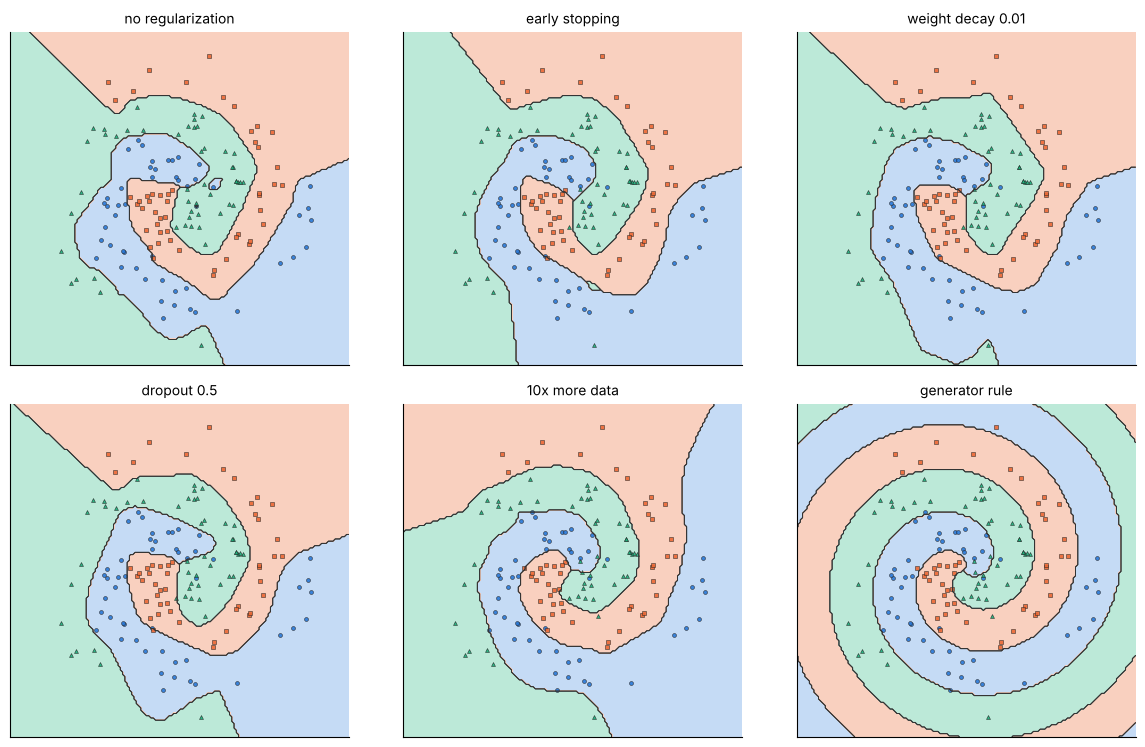

In [74]:
comparison = pd.DataFrame(results).T
comparison.loc["generator rule (reference)"] = [np.nan, (generator_rule(X_sval) == y_sval).mean(), noisy_ceiling,
                                                np.nan, np.nan]
display(comparison.round(4))


@torch.no_grad()
def fresh_correct(net):
    """Boolean array: which of the 6,000 fresh points the network classifies correctly."""
    net.eval()
    return net(Xnew_t.to(DEVICE)).argmax(dim=1).cpu().numpy() == y_new


# Paired comparison: all models are scored on the same fresh points, so only the points on which
# two models disagree can change the difference between their accuracies.
base_right, paired = fresh_correct(net_over), {}
for name, net in [("early stopping", net_es), ("weight decay 0.01", wd_nets[1e-2]), ("dropout 0.5", net_drop_small)]:
    right = fresh_correct(net)
    fixed, broken = int((right & ~base_right).sum()), int((~right & base_right).sum())
    paired[name] = {"fixed": fixed, "new mistakes": broken, "net gain": fixed - broken,
                    "z": (fixed - broken) / math.sqrt(fixed + broken)}   # standard deviations from an even split
print("each remedy against no regularization, point by point on the fresh set:")
display(pd.DataFrame.from_dict(paired, orient="index").round(2))

panels = [(small_proba(net_over), "no regularization"), (small_proba(net_es), "early stopping"),
          (small_proba(wd_nets[1e-2]), "weight decay 0.01"), (small_proba(net_drop_small), "dropout 0.5"),
          (small_proba(net_more), "10x more data"), (rule_proba, "generator rule")]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for ax, (proba_fn, title) in zip(axes.flat, panels):
    plot_regions(ax, proba_fn, X_small, y_small, X_ref=X_new, s=8, steps=150, title=title)
plt.tight_layout()
plt.show()

What the comparison says:

- **Accuracy.** Weight decay (0.852) and dropout (0.855) help a little on fresh data, against 0.842 without regularization, and early stopping (0.843) leaves accuracy essentially unchanged, as Section 12.2 noted. Are such small gains real? Every model is scored on the *same* 6,000 fresh points, so only the points on which two models disagree can change the difference, and the second table counts them. Weight decay fixes 253 of the unregularized network's mistakes and makes 193 new ones (net gain 60). If the two models were equally good, each of these 446 disagreements would be a coin flip, and $m$ fair coin flips give on average $m/2$ heads, with a standard deviation of $\sqrt{m}/2$, so $z = (\text{fixed} - \text{new})/\sqrt{\text{fixed} + \text{new}} = 2.84$ says the split is almost 3 standard deviations from even. Dropout ($z = 3.85$) is clearer still, while early stopping's net gain of 8 points ($z = 0.37$) is noise. So the gains of weight decay and dropout are real for this seed, but they are small, and the ranking could change with another seed or another hyperparameter value.
- **Cross-entropy.** The remedies cut the fresh loss by more than half (from 1.197 to between 0.43 and 0.57). The unregularized network's main problem is not *where* it draws the boundary but *how sure* it claims to be (Section 12.7 looks at this directly).
- **More data beats every trick.** With 1,500 training points the same 17,283-parameter network reaches 0.900 fresh accuracy with a gap of under 2 points and the lowest loss (0.280). It even edges past the generator rule (0.894), which ignores the $\sigma_{xy}$ jitter.
- **Pictures.** The regularized boundaries are smoother than the unregularized one (no islands around single points), but only the model trained on more data recovers the outer windings of the arms: 150 noisy points simply do not contain that information.

> **Key idea.** Regularization trades a little training fit for a simpler, smoother, less overconfident function. It cannot create information that the data do not contain, but more (or better) data can.

### 12.7 Calibration: can we trust the probabilities?

A classifier is **calibrated** if its confidence means what it says: among all predictions made with confidence about 0.8, about 80% should be correct. Accuracy alone cannot tell you this, yet it matters whenever probabilities feed decisions (abstaining when unsure, combining models, estimating risk).

**Reliability diagram and ECE.** Sort the predictions into $M$ bins by their confidence $\hat{c}_i = \max_c \hat{p}_{ic}$ (e.g. $[0.3, 0.4), [0.4, 0.5), \dots$). For each bin $b$ with $n_b$ predictions, compare the average confidence $\text{conf}_b$ with the fraction that is correct, $\text{acc}_b$. A calibrated model has $\text{acc}_b \approx \text{conf}_b$ in every bin: its reliability diagram follows the diagonal. The **expected calibration error** summarizes the gaps, weighting each bin by its share of the data:

$$
\text{ECE} = \sum_{b=1}^{M} \frac{n_b}{n}\,\bigl|\text{acc}_b - \text{conf}_b\bigr| .
$$

A small worked example with $n = 10$ predictions and two bins: four predictions in the bin $[0.5, 0.75)$ with confidences $0.6, 0.6, 0.7, 0.7$ (mean $0.65$), of which 2 are correct (acc $0.5$), and six in $[0.75, 1]$ with mean confidence $0.9$, of which 5 are correct (acc $0.8\overline{3}$). Then $\text{ECE} = 0.4 \cdot |0.5 - 0.65| + 0.6 \cdot |0.8\overline{3} - 0.9| = 0.06 + 0.04 = 0.10$.

worked example (equal-width bins of 0.25): ECE = 0.1000


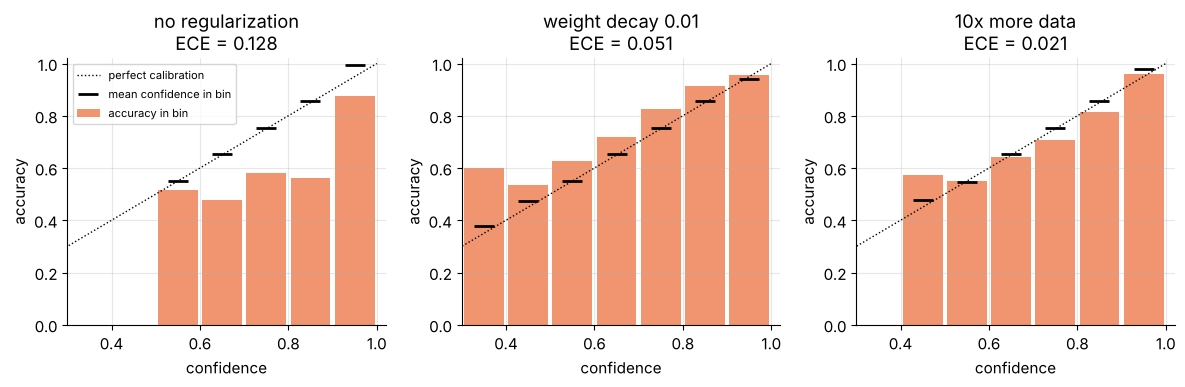

In [75]:
def calibration_table(probs, labels, n_bins=10):
    """Per-bin count, mean confidence and accuracy for equal-width confidence bins on [0, 1]."""
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    correct = (pred == labels).astype(float)
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)              # bin index 0..n_bins-1
    table = pd.DataFrame({"bin": bins, "confidence": conf, "correct": correct})
    return table.groupby("bin").agg(count=("correct", "size"), confidence=("confidence", "mean"),
                                    accuracy=("correct", "mean"))


def expected_calibration_error(probs, labels, n_bins=10):
    tab = calibration_table(probs, labels, n_bins)
    return float((tab["count"] / tab["count"].sum() * (tab["accuracy"] - tab["confidence"]).abs()).sum())


@torch.no_grad()
def logits_of(net, X_t):
    net.eval()
    return net(X_t.to(DEVICE)).cpu()


toy_probs = np.array([[0.6, 0.4, 0]] * 2 + [[0.7, 0.3, 0]] * 2 + [[0.9, 0.1, 0]] * 6)
toy_labels = np.array([0, 1, 0, 1] + [0] * 5 + [1])
print(f"worked example (equal-width bins of 0.25): ECE = {expected_calibration_error(toy_probs, toy_labels, n_bins=4):.4f}")

calib_models = {"no regularization": net_over, "weight decay 0.01": wd_nets[1e-2], "10x more data": net_more}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, net) in zip(axes, calib_models.items()):
    probs_new = torch.softmax(logits_of(net, Xnew_t), dim=1).numpy()
    tab = calibration_table(probs_new, y_new)
    centers = (tab.index.to_numpy() + 0.5) / 10                         # middle of each 0.1-wide bin
    ax.plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="perfect calibration")
    ax.bar(centers, tab["accuracy"], width=0.09, color=VAL_COLOR, alpha=0.7, label="accuracy in bin")
    ax.plot(centers, tab["confidence"], "k_", ms=14, mew=2, label="mean confidence in bin")
    ax.set(xlim=(0.3, 1.02), ylim=(0, 1.02), xlabel="confidence", ylabel="accuracy",
           title=f"{name}\nECE = {expected_calibration_error(probs_new, y_new):.3f}")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

The unregularized network is badly **overconfident**. Most of its predictions land in the top bin with confidence near 1, yet only about 88% of those are correct, and in the middle bins its accuracy is far below its confidence (bars under the diagonal): ECE 0.128. Weight decay brings the bars close to the diagonal (ECE 0.051) and even errs slightly on the *under*confident side: every bar sits above its confidence mark, by 0.02 to 0.08 in the well-populated bins. The model trained on more data is the best calibrated (ECE 0.021). This is the story the validation loss already told in Section 12.1: the rising validation loss of an overfitting network is mostly a calibration problem.

**Temperature scaling.** A cheap and remarkably effective fix after training: divide all logits by one number $T > 0$ before the softmax,

$$
\hat{\mathbf{p}} = \operatorname{softmax}(\mathbf{z} / T).
$$

$T > 1$ softens the probabilities toward uniform, $T < 1$ sharpens them, and because dividing by a positive number never changes which logit is largest, **accuracy is unchanged**. We choose $T$ by minimizing the cross-entropy on the **validation** set (never on the test or fresh data). The cross-entropy as a function of $1/T$ is convex, so a simple one-dimensional search finds the minimum.

In [76]:
def fit_temperature(val_logits, val_labels, grid=np.exp(np.linspace(np.log(0.05), np.log(20), 600))):
    """Temperature T (from a log-spaced grid) that minimizes the validation cross-entropy."""
    nll = [F.cross_entropy(val_logits / T, val_labels).item() for T in grid]
    return float(grid[int(np.argmin(nll))])


rows = {}
for name, net in calib_models.items():
    T = fit_temperature(logits_of(net, Xsv_t), ysv_t)
    z_new = logits_of(net, Xnew_t)
    for label, temp in [("before", 1.0), ("after", T)]:
        p_new = torch.softmax(z_new / temp, dim=1).numpy()
        rows[(name, label)] = {"T": temp, "fresh acc": (p_new.argmax(1) == y_new).mean(),
                               "fresh loss": F.cross_entropy(z_new / temp, ynew_t).item(),
                               "fresh ECE": expected_calibration_error(p_new, y_new)}
display(pd.DataFrame(rows).T.round(4))

T  fresh acc  fresh loss  fresh ECE
no regularization before  1.0000     0.8418      1.1973     0.1276
                  after   5.0299     0.8418      0.4622     0.0447
weight decay 0.01 before  1.0000     0.8518      0.4258     0.0507
                  after   0.8479     0.8518      0.4171     0.0206
10x more data     before  1.0000     0.8998      0.2801     0.0207
                  after   1.2399     0.8998      0.2745     0.0070

Temperature scaling, fitted on the 300 validation points, works remarkably well:

- For the unregularized network it picks $T \approx 5.0$: the logits are about five times too large. Dividing by $T$ cuts the fresh ECE from 0.128 to 0.045 and the fresh cross-entropy from 1.197 to 0.462 **without changing a single prediction** (fresh accuracy stays 0.8418).
- For weight decay 0.01 it picks $T \approx 0.85 < 1$: that model was slightly underconfident, so temperature scaling *sharpens* it (ECE from 0.051 to 0.021).
- For the model trained on more data, $T \approx 1.24$ and the ECE drops from 0.021 to 0.007.

Temperature scaling cannot fix the decisions (accuracy is unchanged by construction), and one global $T$ cannot fix a model that is overconfident in some regions and underconfident in others. As a one-parameter correction applied after training, it is the standard first step whenever probabilities matter.

> **Common pitfall.** Never fit the temperature (or any other calibration) on the training set: an overfitted network is almost always right and nearly certain on its own training points, so the training set would tell you to make it *even more* confident.

### ✏️ Exercise 12: ECE with equal-mass bins

Equal-width bins have a weakness: a confident model puts almost all predictions in the last bin, so the other bins hold a handful of points and their accuracies are noisy. An alternative is **equal-mass** (adaptive) binning: sort the predictions by confidence and cut them into `n_bins` groups of (nearly) equal size, then apply the same ECE formula. Implement `adaptive_ece(probs, labels, n_bins=10)` for NumPy inputs `probs` of shape `(n, C)` and `labels` of shape `(n,)`. Hint: `np.argsort` and `np.array_split`.

In [77]:
# ✏️ Exercise 12: adaptive (equal-mass) ECE
def adaptive_ece(probs, labels, n_bins=10):
    """ECE with bins that each hold (nearly) the same number of predictions, sorted by confidence."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex12():
    # In every test n is a multiple of n_bins and the answer does not depend on the sort direction
    # or on how tied confidences are ordered, so every correct implementation passes.
    # 1. Perfectly calibrated, no ties: the 4 least confident (mean 0.5) have 2 correct, the 4 most confident (mean 0.75) have 3.
    probs = np.array([[0.44, 0.30, 0.26], [0.48, 0.30, 0.22], [0.52, 0.30, 0.18], [0.56, 0.30, 0.14],
                      [0.70, 0.20, 0.10], [0.74, 0.16, 0.10], [0.76, 0.14, 0.10], [0.80, 0.10, 0.10]])
    labels = np.array([0, 1, 0, 1, 0, 0, 1, 0])
    got = float(adaptive_ece(probs, labels, n_bins=2))
    assert abs(got) < 1e-6, f"a perfectly calibrated example must give ECE 0, got {got:.4f}"
    # 2. The worked example of Section 12.7, shuffled, 5 bins of 2: 0.2 * (0.1 + 0.2 + 0.4 + 0.1 + 0.1) = 0.18.
    shuffle = np.array([9, 2, 5, 0, 7, 3, 8, 1, 6, 4])
    got = float(adaptive_ece(toy_probs[shuffle], toy_labels[shuffle], n_bins=5))
    assert abs(got - 0.18) < 1e-6, f"worked example (shuffled), 5 bins: expected 0.18, got {got:.4f}. Did you sort by confidence?"
    # 3. A random case where some bins are over- and some underconfident, so the binning really matters.
    gen = np.random.default_rng(0)
    p = gen.dirichlet(np.ones(3) * 0.5, size=105)                  # 105 = 7 bins of exactly 15
    lab = np.array([gen.choice(3, p=row) for row in p])            # labels drawn from the predicted probabilities
    order = np.argsort(p.max(1), kind="stable")
    ref = sum(len(g) / 105 * abs((p[g].argmax(1) == lab[g]).mean() - p[g].max(1).mean())
              for g in np.array_split(order, 7))
    got = float(adaptive_ece(p, lab, n_bins=7))
    assert abs(got - ref) < 1e-6, f"random case: expected {ref:.4f}, got {got:.4f}. Bins must be consecutive groups by confidence"


run_check("Exercise 12", _test_ex12)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def adaptive_ece(probs, labels, n_bins=10):
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    order = np.argsort(conf, kind="stable")                   # least to most confident
    ece = 0.0
    for group in np.array_split(order, n_bins):               # nearly equal-size consecutive groups
        if len(group) == 0:
            continue
        acc = (pred[group] == labels[group]).mean()
        ece += len(group) / len(labels) * abs(acc - conf[group].mean())
    return ece
```
The checker's second test uses the ten predictions of the worked example in Section 12.7, shuffled, with `n_bins=5`. Sorting puts the two $0.6$ predictions in one bin (one of them correct: $|0.5 - 0.6| = 0.1$) and the two $0.7$ predictions in the next ($|0.5 - 0.7| = 0.2$). The six $0.9$ predictions fill three bins of two: the bin that gets the single wrong $0.9$ prediction has accuracy $0.5$ ($|0.5 - 0.9| = 0.4$), and the other two have accuracy $1$ ($0.1$ each). Each bin holds $2/10$ of the data, so $\text{ECE} = 0.2\,(0.1 + 0.2 + 0.4 + 0.1 + 0.1) = 0.18$, whichever bin the wrong prediction lands in. That is not always so: when a bin edge falls *inside* a group of tied confidences, the result can depend on how the ties are ordered. With two bins, this example gives $0.10$ or $0.20$, depending on which $0.9$ prediction lands in the lower bin. `kind="stable"` breaks ties by the original order, so your own result is at least reproducible.
</details>

## 13. Quiz

Ten exam-style questions. Answer each one before opening the explanation, and every explanation says why the right option is right *and* why each wrong option is wrong.

**Q1.** A softmax-regression classifier with 3 classes acts on 2-D inputs. Which statement is **always** true?

- (A) Each class region is convex.
- (B) Each class region is bounded.
- (C) The three pairwise boundaries are parallel lines.
- (D) The class whose weight vector has the largest norm gets the largest region.

<details>
<summary>Answer</summary>

**(A).** Each region is an intersection of half-planes $(\mathbf{w}_i - \mathbf{w}_j)^\top\mathbf{x} + b_i - b_j \ge 0$, and intersections of convex sets are convex. (B) is wrong: the regions are typically unbounded wedges. (C) is wrong: in general the three boundaries meet at a single triple point (Section 4.1), and they are parallel only in special cases. (D) is wrong: region sizes depend on the *differences* between weight vectors and on the biases, not on individual norms.
</details>

**Q2.** You delete every ReLU from a 2 → 128 → 128 → 3 network and train it. The resulting model is

- (A) more expressive than with ReLUs, because nothing is clipped to zero.
- (B) exactly as expressive as softmax regression.
- (C) able to learn the spiral if trained long enough.
- (D) unable to train, because gradients vanish without activations.

<details>
<summary>Answer</summary>

**(B).** A composition of affine maps is affine, $\mathbf{W}_3(\mathbf{W}_2(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2) + \mathbf{b}_3 = \mathbf{W}\mathbf{x} + \mathbf{b}$, so its regions are convex wedges (Section 5.2). (A) is backwards: the clipping is what creates the folds. (C) is wrong because no amount of training changes the model class. (D) is wrong: a linear network trains without trouble, and it just cannot represent the answer.
</details>

**Q3.** A model's `forward` ends with `torch.softmax(..., dim=1)` and it is trained with `nn.CrossEntropyLoss` on 3 classes. What happens?

- (A) PyTorch raises an error because the inputs to the loss are not logits.
- (B) Training runs, but the training loss can never drop below $\ln(1 + 2/e) \approx 0.551$.
- (C) Nothing changes, because softmax applied twice equals softmax applied once.
- (D) Training is faster, because the probabilities are already normalized.

<details>
<summary>Answer</summary>

**(B).** The loss applies a second softmax to numbers in $[0, 1]$, and the most confident output it can produce is $e/(e+2)$, so the loss is at least $-\ln\frac{e}{e+2} = \ln\frac{e+2}{e} = \ln(1 + 2/e)$ (Sections 6.6 and 7.7). (A) is wrong: the loss cannot tell logits from probabilities, which is why the bug is silent. (C) is wrong: softmax is not idempotent, and $\operatorname{softmax}(0.7, 0.2, 0.1) \ne (0.7, 0.2, 0.1)$. (D) is wrong: the extra squashing *shrinks* the gradients and slows training.
</details>

**Q4.** A hidden layer of 6 ReLU units receives 2-D inputs. What is the largest possible number of linear regions of this layer?

- (A) 7
- (B) 12
- (C) 22
- (D) 64

<details>
<summary>Answer</summary>

**(C).** Six fold lines in general position cut the plane into $1 + 6 \cdot 7/2 = 22$ regions (Section 9.2). (A) counts only one extra region per line, which happens when all lines are parallel. (B) is $2 \times 6$, which has no geometric meaning here. (D) is $2^6$, the number of on/off patterns, but in two dimensions most patterns cannot occur together: 6 lines cannot create 64 regions.
</details>

**Q5.** How many parameters does the network 2 → 24 → 24 → 3 have?

- (A) 696
- (B) 744
- (C) 747
- (D) 771

<details>
<summary>Answer</summary>

**(C).** $(2+1)\cdot 24 + (24+1)\cdot 24 + (24+1)\cdot 3 = 72 + 600 + 75 = 747$. (A) counts the weights but forgets all $24 + 24 + 3 = 51$ biases. (B) forgets the 3 output biases. (D) is the parameter count of the one-hidden-layer network 2 → 128 → 3.
</details>

**Q6.** Your evaluation code runs inside `with torch.no_grad():` but you forgot `model.eval()`. The model contains `nn.Dropout(0.5)`. What is the effect?

- (A) None: `no_grad` also switches dropout off.
- (B) Dropout stays active, so validation predictions are random and the measured accuracy is noisy and usually too low.
- (C) A runtime error, because dropout needs gradients.
- (D) Gradients are still computed for the validation batches.

<details>
<summary>Answer</summary>

**(B).** `torch.no_grad()` only controls autograd, and the train/eval flag controls dropout (Section 10.4). (A) confuses the two mechanisms. (C) is wrong: dropout works fine without gradients. (D) is wrong: `no_grad` does stop the graph from being recorded, and the problem here is the other switch.
</details>

**Q7.** On a small noisy dataset the training loss approaches 0, the validation loss is lowest at epoch 40 and then rises, while the validation accuracy keeps creeping up until about epoch 90. What is the most likely explanation?

- (A) The validation set is mislabeled.
- (B) The learning rate is too small.
- (C) After epoch 40 the network becomes ever more confident, including on the validation points it gets wrong, and each confident mistake costs a lot of cross-entropy, so the loss rises even while a few more points are classified correctly.
- (D) Accuracy and loss always move in opposite directions after convergence.

<details>
<summary>Answer</summary>

**(C).** Cross-entropy punishes confident mistakes heavily ($-\ln 0.01 \approx 4.6$), while accuracy only counts right and wrong. Growing confidence can therefore raise the loss while the accuracy improves slightly (Sections 12.1 and 12.2). (A) is possible in real data but nothing here suggests it. (B) is wrong: the training loss reaching 0 shows the optimizer works well. (D) is false as a general rule, and early in training both improve together.
</details>

**Q8.** You apply temperature scaling with $T = 2$ to a trained classifier. Which statement is correct?

- (A) Accuracy changes because the logits change.
- (B) Predicted classes stay the same, and the probabilities become less extreme.
- (C) The model becomes more confident.
- (D) $T$ should be chosen by minimizing the cross-entropy on the training set.

<details>
<summary>Answer</summary>

**(B).** Dividing all logits by the same positive number keeps their order, so the argmax is unchanged, while the softmax of smaller logits is closer to uniform. (A) is wrong for that same reason. (C) describes $T < 1$. (D) is wrong: an overfitted model is (nearly) perfectly confident and correct on its own training set, so the training set would push $T$ toward sharpening, and $T$ must be fitted on held-out validation data.
</details>

**Q9.** You change the batch size from 32 to 128 but keep the learning rate (0.1) and the number of epochs (100). What do you expect on our spiral task?

- (A) The same result, because the average gradient is the same.
- (B) Noisier gradients and a better final accuracy.
- (C) About 3.5 times fewer parameter updates (400 instead of 1,400), so after 100 epochs the network is clearly less trained.
- (D) Each epoch takes four times longer.

<details>
<summary>Answer</summary>

**(C).** One epoch over 420 points becomes 4 updates instead of 14 (Section 11.2), and with an unchanged step size the model simply moves less. (A) ignores that the *number* of steps matters, not only their direction. (B) is backwards: larger batches give *less* noisy gradients. (D) is wrong: each epoch processes the same 420 points, in fewer, larger matrix operations, so it is usually faster, not slower.
</details>

**Q10.** The training labels happen to be $\{0, 2, 3\}$ (class 1 is missing from the training split) and you set `output_dims = torch.unique(y_train).shape[0]`. What happens?

- (A) `torch.unique` re-encodes the labels to $\{0, 1, 2\}$ automatically, so everything works.
- (B) The model gets 3 outputs, and the first training batch that contains label 3 fails with an index error.
- (C) The model gets 4 outputs, one per class.
- (D) Training works, and the problem only appears at test time.

<details>
<summary>Answer</summary>

**(B).** There are 3 distinct values, so 3 logits, but label 3 is not a valid index into 3 logits (Section 10.5). (A) is wrong: `torch.unique` only re-encodes if you ask for `return_inverse=True` and *use* the codes. (C) is wrong: `unique` counts the values present, not the largest label plus one. (D) is wrong because the out-of-range label 3 is already in the training data.
</details>

## 14. Summary and going further

### Key formulas and facts

| topic | formula / fact |
|---|---|
| linear classifier regions | $R_i = \bigcap_{j \ne i}\{(\mathbf{w}_i - \mathbf{w}_j)^\top\mathbf{x} + b_i - b_j \ge 0\}$: convex, and 3 classes meet at one triple point |
| one-hidden-layer MLP | $\mathbf{z} = \mathbf{W}_2\,\operatorname{ReLU}(\mathbf{W}_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2$, with shapes $(B,2) \to (B,128) \to (B,3)$ |
| parameters of a layer | $(d_\text{in} + 1)\, d_\text{out}$, and the reference MLP has $3 \cdot 128 + 129 \cdot 3 = 771$ |
| no activation | stacked linear layers collapse to one: $\mathbf{W}_2\mathbf{W}_1\mathbf{x} + (\mathbf{W}_2\mathbf{b}_1 + \mathbf{b}_2)$ |
| softmax | $p_c = e^{z_c} / \sum_j e^{z_j}$, and it is invariant to adding a constant to all logits |
| cross-entropy | $\ell = -\log p_y = -z_y + \log\sum_j e^{z_j}$, and a uniform guess over $C$ classes costs $\ln C$ |
| log-sum-exp trick | $\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m}$, $m = \max_j z_j$ |
| gradient w.r.t. logits | $\partial\ell/\partial\mathbf{z} = \mathbf{p} - \mathbf{y}$ (divided by $N$ for a batch mean) |
| double-softmax floor (3 classes) | $\ell \ge \ln(1 + 2/e) \approx 0.5514$ |
| ReLU unit | a ramp $h_j = \|\mathbf{w}_j\|\operatorname{dist}(\mathbf{x}, \text{fold line})$ on its active side |
| linear regions of one layer, 2-D input | at most $1 + n(n+1)/2$ for $n$ units, and inside a region $\mathbf{z} = \mathbf{W}_2\mathbf{D}\mathbf{W}_1\mathbf{x} + \mathbf{W}_2\mathbf{D}\mathbf{b}_1 + \mathbf{b}_2$ |
| SGD / momentum | $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\mathbf{g}$, and $\mathbf{v} \leftarrow \mu\mathbf{v} + \mathbf{g}$, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\mathbf{v}$ |
| Adam | $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\hat{\mathbf{m}} / (\sqrt{\hat{\mathbf{s}}} + \epsilon)$ with bias-corrected moment averages |
| weight decay | $\nabla(\mathcal{L} + \tfrac{\lambda}{2}\|\boldsymbol\theta\|^2) = \nabla\mathcal{L} + \lambda\boldsymbol\theta$ |
| dropout | $\tilde h_j = m_j h_j / (1-p)$, $m_j \sim \text{Bernoulli}(1-p)$, and off in `eval()` mode |
| calibration | $\text{ECE} = \sum_b \frac{n_b}{n}\lvert\text{acc}_b - \text{conf}_b\rvert$, and temperature scaling $\operatorname{softmax}(\mathbf{z}/T)$ keeps accuracy |

### Takeaways

1. **Linear models carve convex regions**, and problems like the spiral need a model that can bend its boundary. An MLP does this by folding the input space with ReLU units and cutting the folded space with a linear output layer.
2. **The PyTorch pipeline**: own the data (and know the pickle risk of `allow_pickle=True`), split with stratification, fit the scaler on training data only, use `float32` features and `long` labels, serve batches with a `Dataset` and a shuffling `DataLoader`, and let the model output **logits** for `nn.CrossEntropyLoss`.
3. **The training loop** is `zero_grad → forward → loss → backward → step`, evaluation needs both `model.eval()` and `torch.no_grad()`, and predictions are collected with `.detach().cpu()` and `torch.cat`, with batch losses weighted by batch size.
4. **Look at the model**: decision regions on a grid (through the same scaler), probability and confidence maps, the hardest examples, the confusion matrix. ReLU networks are confidently wrong far from the data.
5. **Experiment like a scientist**: one change at a time, several seeds, validation data only, and treat differences within the seed-to-seed spread as noise. Separate optimization problems (learning rate, batch size, optimizer, epochs) from capacity problems (width, depth, activation).
6. **Generalization** is measured, not assumed. With few noisy examples a big network memorizes, and early stopping, weight decay, dropout and especially more data reduce the damage, and validation loss also tracks *calibration*, which temperature scaling can repair cheaply.

### Going further

- [PyTorch documentation: `nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) (targets as indices or probabilities, `weight`, `label_smoothing`, `ignore_index`).
- [PyTorch documentation: `torch.utils.data`](https://pytorch.org/docs/stable/data.html) (datasets, samplers, `collate_fn`, worker processes).
- [PyTorch notes on reproducibility](https://pytorch.org/docs/stable/notes/randomness.html) and [`torch.unique`](https://pytorch.org/docs/stable/generated/torch.unique.html).
- [NumPy documentation: `numpy.load`](https://numpy.org/doc/stable/reference/generated/numpy.load.html) (why `allow_pickle` defaults to `False`).
- I. Goodfellow, Y. Bengio, A. Courville, *Deep Learning*, [Chapter 6: Deep Feedforward Networks](https://www.deeplearningbook.org/contents/mlp.html) and [Chapter 7: Regularization](https://www.deeplearningbook.org/contents/regularization.html).
- [Stanford CS231n notes: a neural network case study on spiral data](https://cs231n.github.io/neural-networks-case-study/), and the interactive [TensorFlow Playground](https://playground.tensorflow.org) to watch small networks learn spirals.
- G. Montúfar, R. Pascanu, K. Cho, Y. Bengio (2014), [On the Number of Linear Regions of Deep Neural Networks](https://arxiv.org/abs/1402.1869).
- A. Rahimi, B. Recht (2007), [Random Features for Large-Scale Kernel Machines](https://people.eecs.berkeley.edu/~brecht/papers/07.rah.rec.nips.pdf) (why random hidden features already help, Section 9.4).
- D. Kingma, J. Ba (2014), [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980). I. Loshchilov, F. Hutter (2019), [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101).
- N. Srivastava et al. (2014), [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html).
- C. Guo, G. Pleiss, Y. Sun, K. Weinberger (2017), [On Calibration of Modern Neural Networks](https://arxiv.org/abs/1706.04599) (reliability diagrams, ECE, temperature scaling).
- M. Hein, M. Andriushchenko, J. Bitterwolf (2019), [Why ReLU Networks Yield High-Confidence Predictions Far Away From the Training Data](https://arxiv.org/abs/1812.05720) (Section 8.3).

**Next up:** Notebook 13 moves from points in the plane to images, where `Dataset` classes load and transform files on the fly and the input dimension grows from 2 to thousands.